# Modèle final de gravité automobile : XGBoost Gamma unique

**Version finale retenue : un modèle unique à quatre variables, avec le découpage 80/20 initial par client.** Les 20 % de validation restent exclus de l'ajustement du modèle final. Les essais 90/10 et par tranches sont conservés comme comparaisons historiques.

**Variables utilisées :** `type_contrat`, `prix_vehicule`, `anciennete_vehicule`, `classe_geographique`. La taille de commune a été retirée. Les catégories sont encodées en indicatrices, les valeurs numériques manquantes par les médianes du sous-train. Le modèle Gamma à lien logarithmique prédit un coût positif.

**Fichiers à utiliser :** `models/gravite_final.joblib`, son manifeste `models/gravite_final.json`, et les 50 000 coûts conditionnels de `reports/final/gravite_test.csv`. La **section 16** entraîne, évalue et exporte cette version. Elle peut être réexécutée seule avec `python run_notebook.py --section 16`.

**Objectif :** estimer \(E[S\mid S>0,X=x]\), le coût moyen conditionnel à l'existence d'un sinistre. Aucun modèle de fréquence n'est entraîné dans la version finale, et les sorties ne sont pas des primes.

**Choix du modèle unique :** les expériences à deux et trois tranches ne démontrent pas un gain stable et ajoutent un modèle d'orientation et plusieurs experts. Les scores sont documentés selon leur propre protocole ; les résultats 90/10 ne sont pas présentés comme ceux du modèle final 80/20.

Le notebook suit la roadmap : cadrage → analyse de toutes les variables → nettoyage → choix et création de variables → références et XGBoost → validation → sauvegarde. Les sections **0 à 7** retracent la première étude ; **8 à 10** les créations métier et les variables qualitatives ; **11** le retrait de la taille communale ; **12** la distribution des montants positifs ; **13 à 15** les essais par tranches ; **16** la décision finale et l'export.

Les données ont déjà été explorées au cours de plusieurs expériences. Le découpage par client évite de mélanger les contrats d'un même client, mais ce travail ne remplace pas une validation externe neuve.

## 0. Roadmap et reproductibilité

![Roadmap de référence](assets/roadmap_reference.png)

La référence a été retrouvée dans `previous/deliverables/presentation_histoire/assets/roadmap_reference.png`, puis copiée ici sans modification. Le sujet est `../../td_data_science.pdf`.

Correspondance : **cadrage statistique** → §1 ; **description des données, cible, pertinence** → §2 ; **découpage, NaN, création, encodage, sélection a priori** → §3 ; **baseline, architecture, optimisation, sélection a posteriori** → §4 ; **métriques, sens, erreurs et sauvegarde** → §5–6 ; **journal et reproductibilité** → §7.

Exécution complète : installer `requirements.txt`, ouvrir ce dossier comme répertoire de travail, puis « Run All », ou lancer `python run_notebook.py`. Le notebook est livré avec ses sorties. Les expériences tournent sur CPU avec deux threads par modèle, sans téléchargement automatique de données ni de paquet.

In [1]:
from pathlib import Path
import os, sys, json, time, hashlib, platform, inspect, warnings
os.environ.setdefault('MPLCONFIGDIR', '/tmp/gravite_mpl')
os.environ.setdefault('OMP_NUM_THREADS', '2')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '2')
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Code, Image
import scipy, sklearn, xgboost, joblib
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, GroupKFold, ParameterSampler
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_gamma_deviance, r2_score
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import GammaRegressor
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from threadpoolctl import threadpool_limits

WORKING_DIR = Path.cwd().resolve()
CANDIDATES = [WORKING_DIR, WORKING_DIR / 'gravite_xgboost',
              WORKING_DIR / 'TD-Tarification-automobile-par-Machine-Learning' / 'gravite_xgboost']
HERE = next((p for p in CANDIDATES if (p / 'gravite_pipeline.py').exists()), None)
assert HERE is not None, 'Ouvrir depuis le dossier Project, la racine du dépôt ou ce dossier.'
sys.path.insert(0, str(HERE))
from gravite_pipeline import SeverityFeatures, SeverityEstimator, FORBIDDEN, GROUPS
DATA = HERE.parent / 'Data'
REPORTS, MODELS = HERE / 'reports', HERE / 'models'
REPORTS.mkdir(exist_ok=True); MODELS.mkdir(exist_ok=True)
SEED = 2026
np.random.seed(SEED)
pd.set_option('display.max_rows', 40)
pd.set_option('display.max_columns', 16)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .18, 'axes.prop_cycle': matplotlib.cycler(color=['#215e80','#c67538','#5e8e75'])})
VERSIONS = {m.__name__: m.__version__ for m in [np,pd,scipy,sklearn,xgboost,matplotlib,joblib]}
VERSIONS['python'] = platform.python_version()
print('Versions réellement utilisées :', VERSIONS)
START = time.time()

def savefig(name):
    plt.tight_layout()
    plt.savefig(REPORTS / (name + '.png'), bbox_inches='tight')
    display(Image(filename=str(REPORTS / (name + '.png'))))
    plt.close()

def note(text): display(Markdown(text))
def rmse(y, p): return float(np.sqrt(mean_squared_error(y, p)))
def scores(y, p):
    y, p = np.asarray(y), np.maximum(np.asarray(p), 1.)
    return {'rmse': rmse(y,p), 'mae': float(mean_absolute_error(y,p)),
            'gamma_deviance': float(mean_gamma_deviance(y,p)), 'r2': float(r2_score(y,p)) if len(y)>1 else np.nan,
            'ratio_predit_observe': float(p.sum()/y.sum()), 'moyenne_predite': float(p.mean())}

/home/cytech/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


Versions réellement utilisées : {'numpy': '2.5.3', 'pandas': '3.0.6', 'scipy': '1.18.1', 'sklearn': '1.9.1', 'xgboost': '3.0.2', 'matplotlib': '3.11.2', 'joblib': '1.6.0', 'python': '3.12.3'}


## 1. Cadrage statistique

### 1.1 Cible, population et métriques

`montant_sinistre` est le coût **total du contrat** sur la période observée. `nombre_sinistres > 0` définit la population d'apprentissage. On vérifie cette définition avant toute estimation ; on ne divise pas le montant par le nombre de sinistres. Le fichier ne donne pas de calendrier fiable d'exposition : aucune annualisation arbitraire.

La **RMSE en euros** est le critère principal fixé avant les essais : la perte quadratique vise la moyenne conditionnelle, utile pour un coût attendu, et rend visibles les grosses erreurs. La **MAE** décrit l'erreur ordinaire mais favorise une médiane ; elle ne suffit pas à sélectionner un modèle de coût moyen. La **déviance Gamma** apporte un diagnostic relatif pour une cible strictement positive. On suit aussi le **ratio somme prédite / somme observée**, le R², l'écart apprentissage–validation et la queue de distribution.

Cette RMSE conditionnelle n'est **pas** la RMSE de prime de la compétition. La métrique officielle n'est pas documentée dans les fichiers locaux ; aucune équivalence ni performance Kaggle n'est annoncée.

### 1.2 Taille d'échantillon et indépendance

Les contrats d'un même client peuvent se ressembler. Les identifiants servent uniquement à créer des groupes étanches. Un **holdout local de 20 % des clients**, sans stratification utilisant leurs coûts, est réservé dès maintenant. Toute exploration cible, optimisation, regroupement appris et sélection se déroule sur les 80 % restants. À l'intérieur de ce développement : **3 plis séparés par client**, stratifiés sur cinq tranches de coût pour mieux répartir la queue.

Les fichiers ont déjà été explorés historiquement. Ce holdout est tenu à l'écart de **cette nouvelle sélection**, mais ne constitue pas une cohorte externe neuve ni une preuve d'absence de tout biais historique.

In [2]:
train = pd.read_csv(DATA / 'train.csv', dtype={'code_postal': str})
test = pd.read_csv(DATA / 'test.csv', dtype={'code_postal': str})
TARGET = 'montant_sinistre'
assert train['index'].is_unique and test['index'].is_unique
assert train[TARGET].notna().all() and train[TARGET].ge(0).all()
assert train['nombre_sinistres'].notna().all() and train['nombre_sinistres'].ge(0).all()
assert (train['nombre_sinistres'].gt(0) == train[TARGET].gt(0)).all(), 'Cible/fréquence incohérentes : à résoudre.'
FEATURES = [c for c in test.columns if c not in FORBIDDEN]
assert set(FEATURES).issubset(train.columns)
assert not set(FEATURES) & FORBIDDEN

splitter = GroupShuffleSplit(n_splits=1, test_size=.20, random_state=SEED)
dev_idx, hold_idx = next(splitter.split(train, groups=train['id_client']))
dev_portfolio = train.iloc[dev_idx].copy()
hold_portfolio = train.iloc[hold_idx].copy()
assert not set(dev_portfolio.id_client) & set(hold_portfolio.id_client)
dev = dev_portfolio.loc[dev_portfolio.nombre_sinistres.gt(0)].copy().reset_index(drop=True)
# À ce stade, aucun descriptif des montants du holdout n'est consulté.
X, y, groups = dev[FEATURES], dev[TARGET].to_numpy(), dev.id_client.to_numpy()
strata = pd.qcut(pd.Series(y).rank(method='first'), q=5, labels=False)
cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)
FOLDS = list(cv.split(X, strata, groups))
fold_ids = np.full(len(dev), -1)
for k,(tr,va) in enumerate(FOLDS):
    assert not set(groups[tr]) & set(groups[va])
    fold_ids[va] = k
assert (fold_ids >= 0).all()
assign = train[['index','id_client']].copy()
assign['role'] = np.where(assign.index.isin(dev_idx), 'developpement', 'holdout')
assign['pli_cv_gravite'] = assign['index'].map(dict(zip(dev['index'],fold_ids))).astype('Int64')
assign.to_csv(REPORTS / 'decoupage_clients.csv', index=False)
summary_files = pd.DataFrame([
    {'fichier':'train.csv','lignes':len(train),'colonnes':train.shape[1],'rôle':'apprentissage + holdout local'},
    {'fichier':'test.csv','lignes':len(test),'colonnes':test.shape[1],'rôle':'prédictions finales sans cibles'},
])
display(summary_files)
print(f'Développement : {len(dev_portfolio):,} contrats ; {len(dev):,} sinistrés ; {len(np.unique(groups)):,} clients sinistrés.')
print(f'Holdout réservé : {len(hold_portfolio):,} contrats, cibles non examinées avant gel du modèle.')
print('Taille des plis positifs :', pd.Series(fold_ids).value_counts().sort_index().to_dict())

,fichier,lignes,colonnes,rôle
0,train.csv,50000,33,apprentissage + holdout local
1,test.csv,50000,28,prédictions finales sans cibles


Développement : 39,964 contrats ; 2,356 sinistrés ; 2,338 clients sinistrés.
Holdout réservé : 10,036 contrats, cibles non examinées avant gel du modèle.
Taille des plis positifs : {0: 785, 1: 786, 2: 785}


## 2. Analyse des données avant modélisation

### 2.1 Description exhaustive : types, manquants, modalités, valeurs aberrantes, doublons

L'audit de structure du fichier entier est autorisé, mais les statistiques dépendant des coûts restent sur le développement. Les identifiants et `index` sont exclus, car ils n'ont pas de sens tarifaire généralisable et plusieurs manquent dans le test. Le nombre de sinistres est une information future : il filtre la population et n'entre jamais dans X. Les deux variables de sexe sont exclues du modèle dans ce projet ; cette convention n'est pas un audit de conformité des autres variables.

`code_postal` est lu comme texte pour conserver les zéros initiaux. Ses nombreuses modalités et son format suggèrent qu'une interprétation géographique précise nécessite un dictionnaire absent : on teste seulement un préfixe, le code brut ou l'absence de code. Les unités et la signification exacte de `paiement`, `debut_vente_vehicule`, `fin_vente_vehicule` et des anciennetés demandent confirmation ; on n'invente pas de dates ni d'exposition.

In [3]:
descriptions = {
'index': 'ordre technique', 'id_client':'groupe client', 'id_vehicule':'identifiant véhicule local',
'id_contrat':'identifiant contrat', 'bonus':'coefficient bonus-malus', 'type_contrat':'niveau de couverture',
'duree_contrat':'ancienneté/durée déclarée, unité à confirmer', 'anciennete_info':'ancienneté information, unité à confirmer',
'freq_paiement':'fréquence de paiement', 'paiement':'indicateur paiement, sens exact à confirmer',
'utilisation':'usage du véhicule', 'code_postal':'code géographique à documenter', 'conducteur2':'présence second conducteur',
'age_conducteur1':'âge conducteur principal', 'age_conducteur2':'âge second conducteur, zéro si absent',
'sex_conducteur1':'sexe principal, exclu', 'sex_conducteur2':'sexe secondaire, absence structurelle',
'anciennete_permis1':'ancienneté permis principal', 'anciennete_permis2':'ancienneté permis secondaire',
'anciennete_vehicule':'âge du véhicule', 'cylindre_vehicule':'cylindrée', 'din_vehicule':'puissance DIN',
'essence_vehicule':'motorisation', 'marque_vehicule':'marque', 'modele_vehicule':'modèle automobile',
'debut_vente_vehicule':'ancienneté début vente, unité à confirmer', 'fin_vente_vehicule':'ancienneté fin vente, unité à confirmer',
'vitesse_vehicule':'vitesse maximale déclarée', 'type_vehicule':'tourisme ou commercial',
'prix_vehicule':'prix catalogue déclaré', 'poids_vehicule':'poids déclaré',
'nombre_sinistres':'filtre sinistré, information cible', 'montant_sinistre':'cible coût total',
}
audit = []
for c in train.columns:
    s = dev_portfolio[c]
    role = 'cible' if c == TARGET else 'filtre' if c == 'nombre_sinistres' else 'exclu' if c in FORBIDDEN else 'explicative'
    num = pd.api.types.is_numeric_dtype(s)
    audit.append({'variable':c,'description':descriptions[c],'type':str(s.dtype),'rôle':role,
                  'disponible_test':c in test,'manquants_dev':int(s.isna().sum()),
                  'modalités_dev':s.nunique(), 'modalités_moins_10':int(s.value_counts().lt(10).sum()) if not num else np.nan,
                  'min':s.min() if num else np.nan, 'médiane':s.median() if num else np.nan,
                  'max':s.max() if num else np.nan})
audit = pd.DataFrame(audit)
audit.to_csv(REPORTS/'audit_toutes_variables.csv',index=False)
display(audit)
assert not dev_portfolio.id_contrat.duplicated().any()
print('Clients multi-contrats sur développement :', int(dev_portfolio.id_client.duplicated().sum()))
print('Doublons exacts hors identifiants :', int(dev_portfolio.drop(columns=['index','id_client','id_vehicule','id_contrat']).duplicated().sum()))
quality = {
    'poids nul ou négatif': int(dev_portfolio.poids_vehicule.le(0).sum()),
    'cylindrée nulle ou négative': int(dev_portfolio.cylindre_vehicule.le(0).sum()),
    'permis1 = 111 ou supérieur à âge': int((dev_portfolio.anciennete_permis1.eq(111)|dev_portfolio.anciennete_permis1.gt(dev_portfolio.age_conducteur1)).sum()),
    'permis2 invalide si conducteur présent': int(((dev_portfolio.anciennete_permis2.eq(111)|dev_portfolio.anciennete_permis2.gt(dev_portfolio.age_conducteur2)) & dev_portfolio.conducteur2.eq('Yes')).sum()),
    'âge secondaire = 0 si absent': int((dev_portfolio.age_conducteur2.eq(0)&dev_portfolio.conducteur2.eq('No')).sum()),
    'âge obtention permis principal < 16': int((dev_portfolio.age_conducteur1-dev_portfolio.anciennete_permis1).lt(16).sum()),
}
display(pd.Series(quality,name='nombre de contrats développement').to_frame())

,variable,description,type,rôle,disponible_test,manquants_dev,modalités_dev,modalités_moins_10,min,médiane,max
0,index,ordre technique,int64,exclu,True,0,39964,NaN,0.000,"25,116.500","49,998.000"
1,id_client,groupe client,str,exclu,False,0,36628,"36,628.000",NaN,NaN,NaN
2,id_vehicule,identifiant véhicule local,str,exclu,False,0,5,1.000,NaN,NaN,NaN
3,id_contrat,identifiant contrat,str,exclu,False,0,39964,"39,964.000",NaN,NaN,NaN
4,bonus,coefficient bonus-malus,float64,explicative,True,0,72,NaN,0.500,0.500,2.160
5,type_contrat,niveau de couverture,str,explicative,True,0,4,0.000,NaN,NaN,NaN
6,duree_contrat,"ancienneté/durée déclarée, unité à confirmer",int64,explicative,True,0,41,NaN,1.000,9.000,41.000
7,anciennete_info,"ancienneté information, unité à confirmer",int64,explicative,True,0,25,NaN,1.000,2.000,25.000
8,freq_paiement,fréquence de paiement,str,explicative,True,0,4,0.000,NaN,NaN,NaN
9,paiement,"indicateur paiement, sens exact à confirmer",str,explicative,True,0,2,0.000,NaN,NaN,NaN


Clients multi-contrats sur développement : 3336
Doublons exacts hors identifiants : 0


,nombre de contrats développement
poids nul ou négatif,1515
cylindrée nulle ou négative,3
permis1 = 111 ou supérieur à âge,11
permis2 invalide si conducteur présent,310
âge secondaire = 0 si absent,26670
âge obtention permis principal < 16,15


**Décision de nettoyage à tester :** les poids/cylindrées non positifs sont remplacés par NaN avec un indicateur d'anomalie. Une ancienneté de permis égale à 111 ou supérieure à l'âge devient NaN ; 111 est traité comme un code suspect, sans prétendre connaître sa définition. Les zéros d'âge/permis du second conducteur absent deviennent des manquants structurels, avec `conducteur2` conservé. Les âges très élevés, les véhicules très chers et les grands sinistres ne sont pas supprimés automatiquement. Une variante sans ce nettoyage permet d'en mesurer l'effet.

### 2.2 Distribution de la cible et poids de la queue

Le taux de sinistralité sert à comprendre la sélection des observations, sans entraîner un modèle de fréquence. On examine le montant brut, son logarithme, les valeurs répétées et la concentration du coût. Les répétitions de montants peuvent traduire des conventions d'indemnisation, mais le fichier ne permet pas de conclure à leur origine.

,montant positif (€)
count,"2,356.000"
mean,"1,767.305"
std,"1,461.633"
min,600.600
1%,609.877
10%,697.890
25%,951.877
50%,"1,236.000"
75%,"2,195.278"
90%,"3,337.055"


Taux de contrats sinistrés sur développement : 5.90%
Montants les plus répétés :


,effectif
montant_sinistre,
"1,236.000",268
"1,010.410",103
"2,683.760",39
618.000,24
"1,442.870",21
"1,240.890",17
"2,453.280",12
"2,323.950",9
"3,288.460",5


,quantile,seuil_euros,n,part_du_cout,part_somme_carres
0,0.900,"3,337.055",236,0.287,0.588
1,0.950,"4,347.745",118,0.179,0.449
2,0.990,"7,109.233",24,0.059,0.228


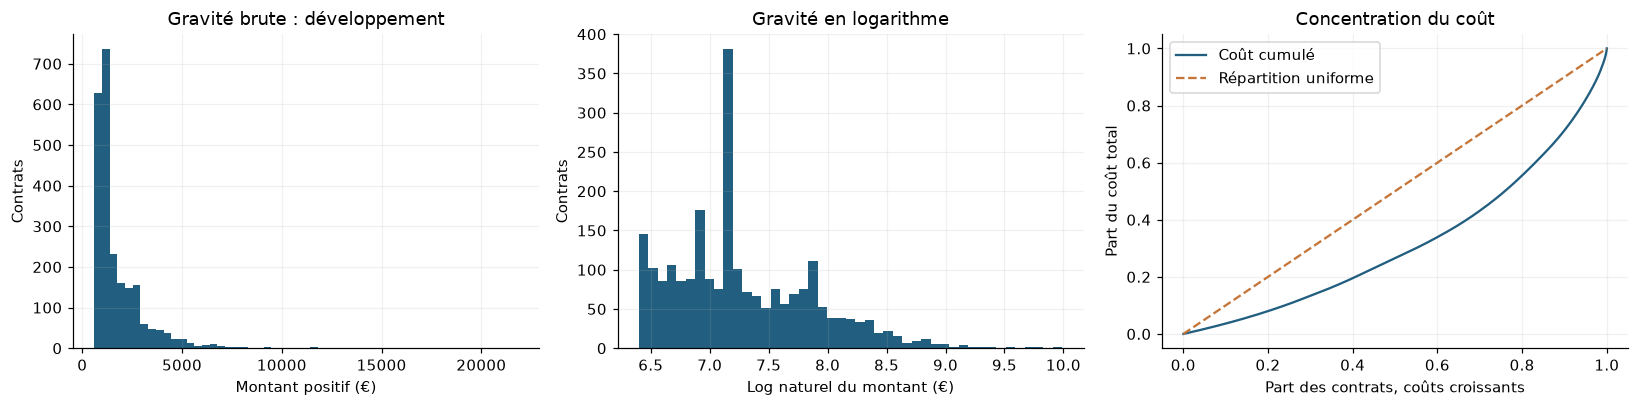

**Lecture :** moyenne 1,767 €, médiane 1,236 €, asymétrie 4.14. Le dernier centile concentre 5.9% du coût et 22.8% de la somme des carrés. Cela motive une comparaison perte quadratique / Gamma / Tweedie / logarithme et une analyse explicite des gros sinistres.

In [4]:
rate = dev_portfolio.nombre_sinistres.gt(0).mean()
quantiles = pd.Series(y).describe(percentiles=[.01,.10,.25,.50,.75,.90,.95,.99]).to_frame('montant positif (€)')
display(quantiles)
print(f'Taux de contrats sinistrés sur développement : {rate:.2%}')
print('Montants les plus répétés :'); display(dev[TARGET].value_counts().head(10).to_frame('effectif'))
tail_rows=[]
for q in [.9,.95,.99]:
    mask = y >= np.quantile(y,q)
    tail_rows.append({'quantile':q,'seuil_euros':np.quantile(y,q),'n':mask.sum(),
                      'part_du_cout':y[mask].sum()/y.sum(),'part_somme_carres':(y[mask]**2).sum()/(y**2).sum()})
tail = pd.DataFrame(tail_rows); display(tail)
tail.to_csv(REPORTS/'concentration_cible_developpement.csv',index=False)
fig, axes = plt.subplots(1,3,figsize=(15,3.8))
axes[0].hist(y,bins=55); axes[0].set(xlabel='Montant positif (€)',ylabel='Contrats',title='Gravité brute : développement')
axes[1].hist(np.log(y),bins=45); axes[1].set(xlabel='Log naturel du montant (€)',ylabel='Contrats',title='Gravité en logarithme')
a=np.sort(y); axes[2].plot(np.arange(1,len(y)+1)/len(y),np.cumsum(a)/a.sum(),label='Coût cumulé')
axes[2].plot([0,1],[0,1],linestyle='--',label='Répartition uniforme')
axes[2].set(xlabel='Part des contrats, coûts croissants',ylabel='Part du coût total',title='Concentration du coût'); axes[2].legend()
savefig('01_distribution_cible')
note(f'**Lecture :** moyenne {y.mean():,.0f} €, médiane {np.median(y):,.0f} €, asymétrie {pd.Series(y).skew():.2f}. '
     f'Le dernier centile concentre {tail.iloc[-1].part_du_cout:.1%} du coût et {tail.iloc[-1].part_somme_carres:.1%} de la somme des carrés. '
     'Cela motive une comparaison perte quadratique / Gamma / Tweedie / logarithme et une analyse explicite des gros sinistres.')

### 2.3 Lien de **chaque variable** avec les deux cibles

Pour chaque variable disponible à la tarification : moyenne du coût **conditionnelle aux sinistrés**, effectif positif, erreur standard descriptive, et taux de sinistralité sur tout le développement. Une moyenne de gravité fondée sur deux sinistres n'a pas la même fiabilité qu'une moyenne fondée sur 200. Les graphes utilisent les dix modalités les plus présentes ou des déciles numériques ; le fichier CSV conserve toutes les modalités catégorielles, même rares.

Ces analyses sont descriptives, sans tests multiples de significativité ni sélection automatique par corrélation. Une corrélation faible peut cacher un effet non linéaire ou une interaction. Les variables de sexe et les identifiants figurent dans l'audit, mais ne participent pas aux essais.

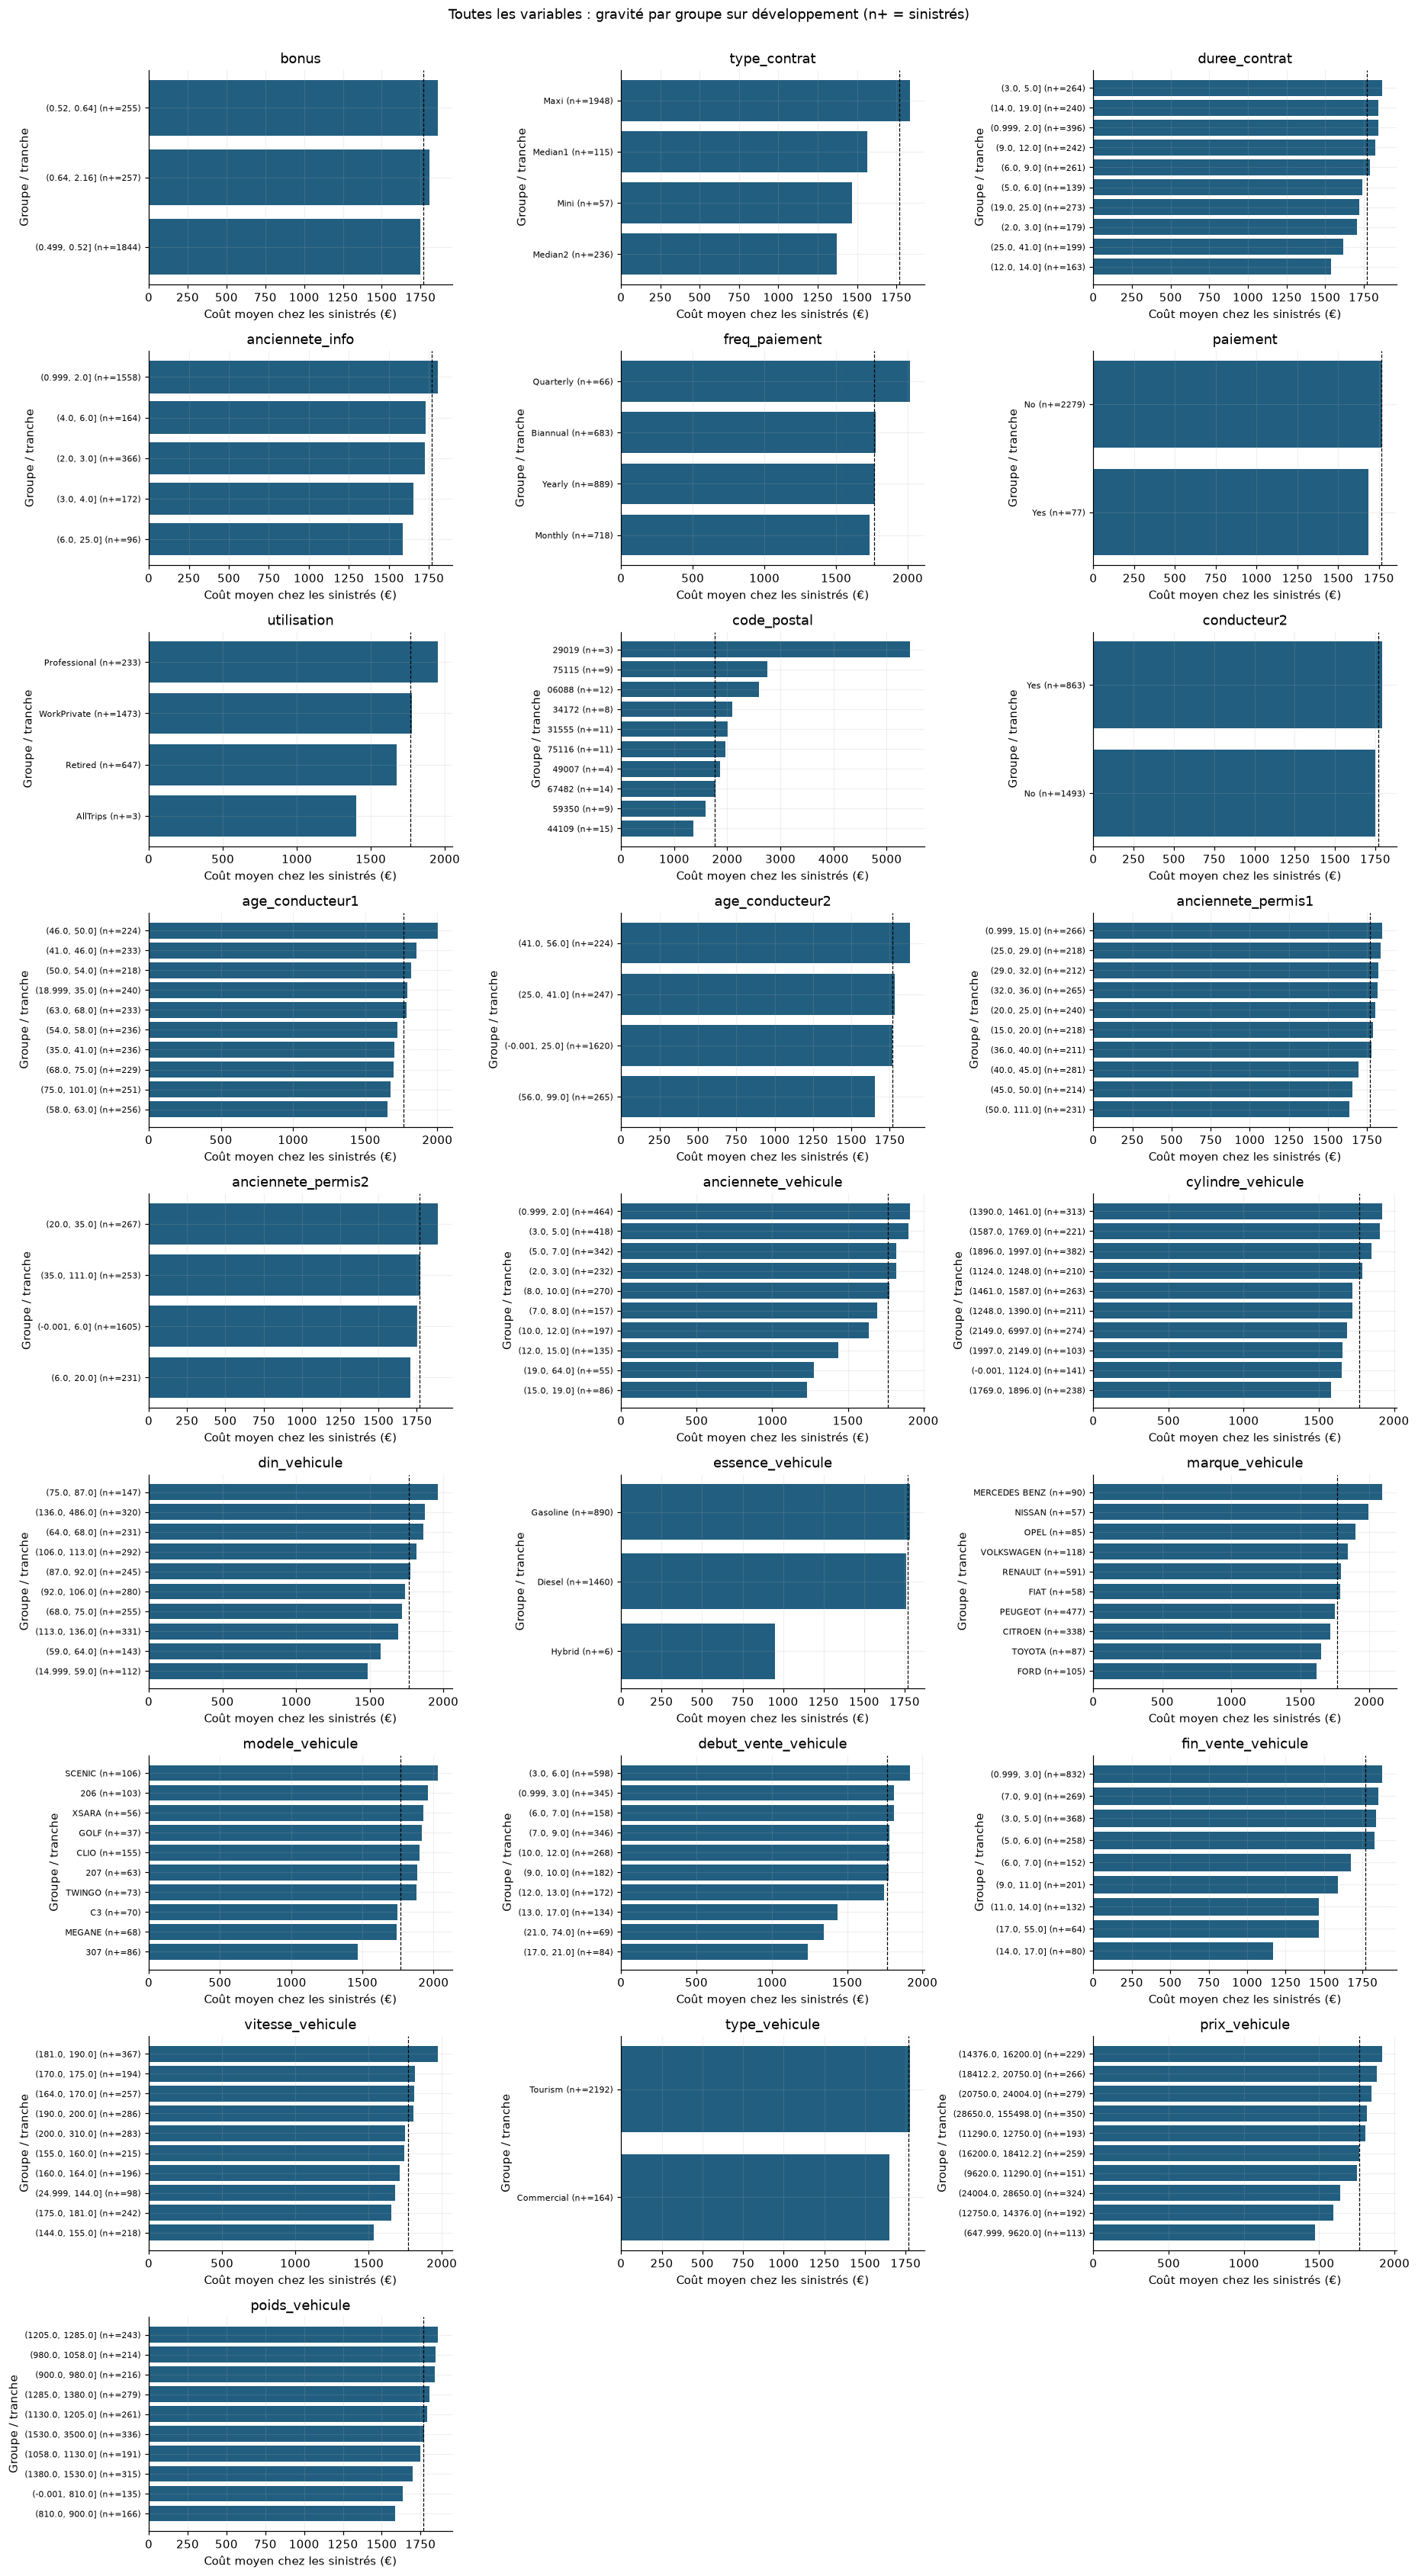

,variable,groupe,n,taux_sinistre,n_positifs,gravite_moyenne,gravite_mediane,erreur_standard
3,type_contrat,Maxi,25877,0.075,1948,"1,836.212","1,295.820",32.587
4,type_contrat,Median1,3682,0.031,115,"1,564.391","1,236.000",212.055
5,type_contrat,Median2,7020,0.034,236,"1,369.293","1,236.000",57.580
6,type_contrat,Mini,3385,0.017,57,"1,469.692","1,236.000",233.274
28,utilisation,AllTrips,37,0.081,3,"1,402.173","1,336.410",253.998
29,utilisation,Professional,2929,0.080,233,"1,951.324","1,240.890",116.095
30,utilisation,Retired,10648,0.061,647,"1,674.625","1,236.000",43.648
31,utilisation,WorkPrivate,26350,0.056,1473,"1,779.649","1,236.000",40.130
11505,essence_vehicule,Diesel,21914,0.067,1460,"1,761.222","1,236.000",37.905
11506,essence_vehicule,Gasoline,18011,0.049,890,"1,782.788","1,236.330",49.846


**Précaution :** les traits pointillés sont la moyenne globale de gravité. Les groupes minuscules servent à identifier la rareté ; leurs écarts ne justifient pas seuls une variable ou un tarif.

In [5]:
relations=[]
plot_groups={}
for col in FEATURES:
    s = dev_portfolio[col]
    if pd.api.types.is_numeric_dtype(s) and s.nunique()>12:
        cats = pd.qcut(s, q=10, duplicates='drop').astype(str).where(s.notna(),'__MANQUANT__')
    else:
        cats = s.fillna('__MANQUANT__').astype(str)
    frame=pd.DataFrame({'groupe':cats,'sinistre':dev_portfolio.nombre_sinistres.gt(0),
                        'cout_positif':dev_portfolio[TARGET].where(dev_portfolio.nombre_sinistres.gt(0))})
    tab=frame.groupby('groupe',observed=True).agg(n=('sinistre','size'),taux_sinistre=('sinistre','mean'),
                   n_positifs=('cout_positif','count'),gravite_moyenne=('cout_positif','mean'),
                   gravite_mediane=('cout_positif','median'),ecart_type=('cout_positif','std')).reset_index()
    tab['erreur_standard']=tab.ecart_type/np.sqrt(tab.n_positifs.clip(lower=1))
    tab.insert(0,'variable',col); relations.append(tab)
    plot_groups[col]=tab.sort_values('n',ascending=False).head(10).sort_values('gravite_moyenne')
relations=pd.concat(relations,ignore_index=True)
relations.to_csv(REPORTS/'relations_toutes_variables_cibles.csv',index=False)
fig, axes=plt.subplots(int(np.ceil(len(FEATURES)/3)),3,figsize=(17,3.4*int(np.ceil(len(FEATURES)/3))))
for ax,col in zip(axes.flat,FEATURES):
    t=plot_groups[col].dropna(subset=['gravite_moyenne'])
    xx=np.arange(len(t)); ax.barh(xx,t.gravite_moyenne)
    ax.set_yticks(xx, [str(g)[:26]+f' (n+={n})' for g,n in zip(t.groupe,t.n_positifs)],fontsize=7)
    ax.axvline(y.mean(),color='black',linestyle='--',linewidth=.8)
    ax.set(title=col,xlabel='Coût moyen chez les sinistrés (€)',ylabel='Groupe / tranche')
for ax in list(axes.flat)[len(FEATURES):]: ax.set_visible(False)
fig.suptitle('Toutes les variables : gravité par groupe sur développement (n+ = sinistrés)',y=1.002)
savefig('02_toutes_variables_gravite')
display(relations.loc[relations.variable.isin(['type_contrat','utilisation','essence_vehicule'])].drop(columns='ecart_type'))
note('**Précaution :** les traits pointillés sont la moyenne globale de gravité. Les groupes minuscules servent à identifier la rareté ; leurs écarts ne justifient pas seuls une variable ou un tarif.')

,Spearman avec coût positif
anciennete_vehicule,-0.075
fin_vente_vehicule,-0.068
debut_vente_vehicule,-0.059
cylindre_vehicule,-0.047
poids_vehicule,-0.035
prix_vehicule,-0.031
din_vehicule,-0.020
duree_contrat,-0.017
age_conducteur2,-0.011
vitesse_vehicule,0.010


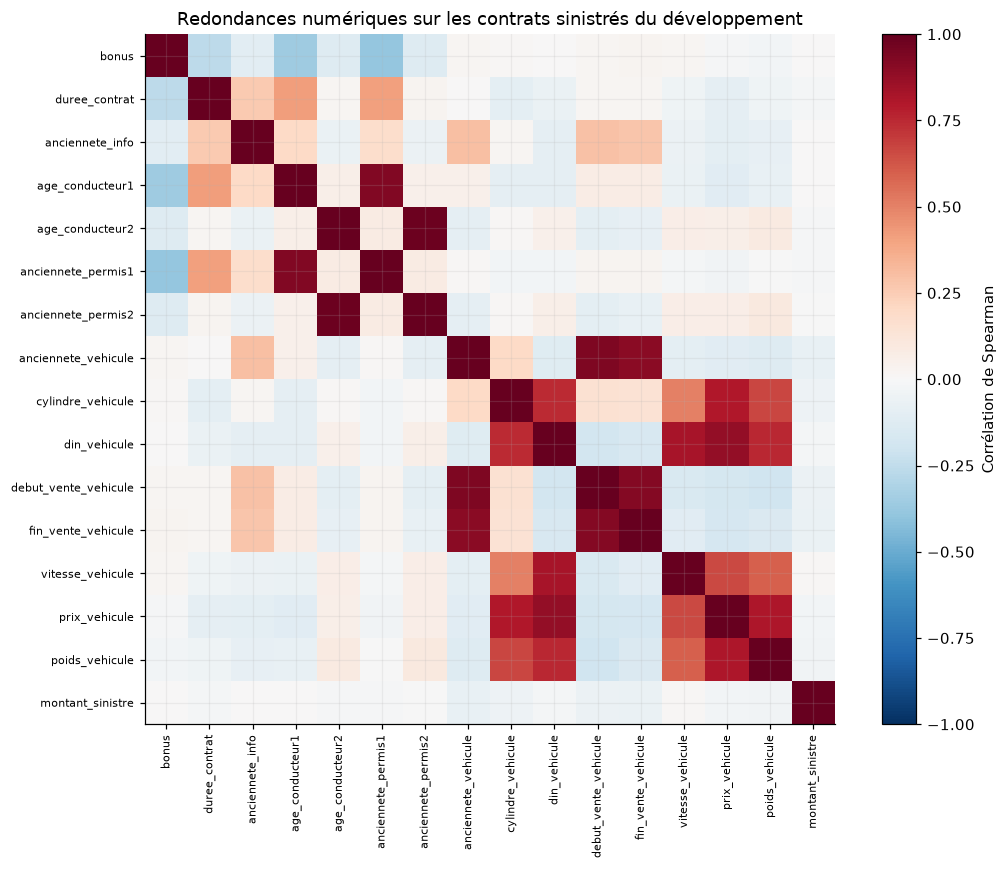

Couples marque–modèle distincts chez les sinistrés du développement : 325


,seuil,modèles_sous_seuil,part_lignes_concernées
0,2,126,0.053
1,10,271,0.288
2,25,302,0.488
3,50,316,0.669


In [6]:
numeric = [c for c in FEATURES if pd.api.types.is_numeric_dtype(X[c])]
corr=dev[numeric+[TARGET]].corr(method='spearman')
display(corr[TARGET].drop(TARGET).sort_values(key=abs,ascending=False).to_frame('Spearman avec coût positif'))
corr.to_csv(REPORTS/'correlations_spearman_developpement.csv')
fig,ax=plt.subplots(figsize=(10,8))
im=ax.imshow(corr,cmap='RdBu_r',vmin=-1,vmax=1)
ax.set_xticks(range(len(corr)),corr.columns,rotation=90,fontsize=7)
ax.set_yticks(range(len(corr)),corr.index,fontsize=7)
fig.colorbar(im,ax=ax,label='Corrélation de Spearman')
ax.set_title('Redondances numériques sur les contrats sinistrés du développement')
savefig('03_correlations')
car_counts=dev.groupby(['marque_vehicule','modele_vehicule'],observed=True).size()
print('Couples marque–modèle distincts chez les sinistrés du développement :',len(car_counts))
display(pd.DataFrame([{'seuil':s,'modèles_sous_seuil':int(car_counts.lt(s).sum()),
    'part_lignes_concernées':float(car_counts[car_counts.lt(s)].sum()/len(dev))} for s in [2,10,25,50]]))

### 2.4 Pertinence et hypothèses à éprouver

- **Couverture / prix / usage / âge véhicule :** peuvent être liés au coût indemnisé. Ils forment une version simple de cinq variables, puis sont comparés à toutes les variables admissibles.
- **Identité automobile :** marque et modèle capturent des différences techniques, mais créent beaucoup de modalités rares. On teste suppression du modèle, seuils de rareté, familles syntaxiques et clusters techniques.
- **Puissance, vitesse, cylindrée, poids, prix :** corrélés, sans être interchangeables. Les ratios puissance/poids et prix/poids peuvent exprimer un profil ; les divisions par zéro sont interdites. Leur intérêt sera mesuré, pas présumé.
- **Conducteurs :** âge, expérience et second conducteur peuvent aider ; âge d'obtention et écart entre conducteurs sont des hypothèses supplémentaires.
- **Gestion et géographie :** possibles effets de sélection ou proxys. Les ablations vérifient leur apport ; ni causalité ni validité commerciale ne sont déduites d'une importance prédictive.
- **Cible extrême :** la conserver constitue le choix initial. Un plafonnement au centile 99 appris dans chaque pli est testé comme analyse de sensibilité, puis évalué sur des coûts non plafonnés.

Les périodes et codes insuffisamment documentés sont conservés sous leur forme déclarée ou retirés par ablation. Aucune source externe ni regroupement par moyenne de coût globale n'est utilisé.

## 3. Traitement des données

### 3.1 Séparation des jeux et apprentissages confinés au train

Les indices sont fixés au §1 et exportés. Dans chaque pli, **seul le sous-train** apprend : médianes d'imputation, catégories et fréquences de rareté, centres de clusters, éventuel seuil de plafonnement et correction logarithmique. Les cibles de validation servent uniquement au score. Le même code transformera le test après le choix final.

### 3.2 Traitement des NaN et encodage

Référence : médiane numérique + indicateur de manquant ; catégories textuelles avec modalité de manquant et **one-hot**. Les catégories vues moins de 10 fois dans le sous-train sinistré sont mutualisées. Les modalités nouvelles rejoignent ce groupe s'il existe, sinon donnent des colonnes nulles. Deux alternatives : moyenne numérique et NaN laissés à XGBoost. Le seuil de rareté est lui aussi testé.

Les arbres n'ont pas besoin d'une standardisation globale. Elle n'est appliquée qu'aux variables utilisées pour les distances des clusters, après log et imputation. Les variables quantitatives ne sont pas artificiellement ordonnées par leur code catégoriel.

### 3.3 Création et regroupement de variables

**Famille de modèle :** couple marque–premier token du nom (`C4 PICASSO` → `CITROEN::C4`). C'est une règle syntaxique conservatrice, pas une classification automobile certifiée ; ses collisions sont affichées. **Segments :** prix <10 k€, 10–20 k€, 20–35 k€, ≥35 k€ et puissance en quatre classes fixées a priori. **Clusters :** KMeans à 6 ou 12 groupes sur log(prix, puissance, poids, cylindrée, vitesse), ajusté uniquement sur le sous-train.

Les ratios, logarithmes et croisements couverture×usage / couverture×segment sont évalués en blocs séparés, puis ensemble. Les logarithmes de variables d'entrée sont monotones : leur gain éventuel peut venir du découpage histogramme ou des interactions, pas d'une information nouvelle. Une variable dérivée ne crée pas de donnée supplémentaire.

### 3.4 Sélection a priori

Exclusion des cibles, identifiants, ordre des lignes et sexes. Aucune élimination automatique fondée uniquement sur Spearman. Le modèle simple et les ablations permettent ensuite de vérifier la nécessité des autres blocs.

Le code exact ci-dessous constitue la pipeline sauvegardable. Le reste des analyses et des choix est écrit directement dans ce notebook.

In [7]:
display(Code((HERE/'gravite_pipeline.py').read_text(), language='python'))
preview=SeverityFeatures(profile='all').fit_transform(X)
display(preview.head())
family_map=pd.DataFrame({'marque':X.marque_vehicule,'modele_original':X.modele_vehicule,
                        'famille':preview.famille_modele}).drop_duplicates()
collisions=family_map.groupby('famille').modele_original.nunique().sort_values(ascending=False)
display(family_map.loc[family_map.famille.isin(collisions[collisions.gt(1)].head(8).index)].sort_values('famille'))
family_map.to_csv(REPORTS/'regroupements_familles.csv',index=False)
new_features=[c for c in preview if c not in FEATURES]
display(pd.DataFrame({'variable_créée':new_features,
                     'manquants_dev':[preview[c].isna().sum() for c in new_features]}))

"""Transformations et estimateur de gravité, indépendants des anciens modèles.
Le notebook explique et affiche ce code. Tous les apprentissages restent dans fit.
"""
from __future__ import annotations
import re
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin, RegressorMixin
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBRegressor

FORBIDDEN = {'index', 'id_client', 'id_vehicule', 'id_contrat',
             'nombre_sinistres', 'montant_sinistre', 'sex_conducteur1', 'sex_conducteur2'}
GROUPS = {
    'identite_auto': ['marque_vehicule', 'modele_vehicule'],
    'geographie': ['code_postal'],
    'gestion': ['duree_contrat', 'anciennete_info', 'freq_paiement', 'paiement'],
    'conducteurs': ['conducteur2', 'age_conducteur1', 'age_conducteur2',
                    'anciennete_permis1', 'anciennete_permis2'],
    'technique_auto': ['anciennete_vehicule', 'cylindre_vehicule', 'din_vehicule',
                       'essence_vehicule', 'vitesse_vehicule', 'type_vehicule',
                       'prix_vehicule', 'poids_vehicule', 'debut_vente_vehicule', 'fin_vente_vehicule'],
    'couverture': ['type_contrat'],
    'bonus': ['bonus'],
    'usage': ['utilisation'],
    'redondantes_auto': ['vitesse_vehicule', 'cylindre_vehicule',
                         'debut_vente_vehicule', 'fin_vente_vehicule'],
}

class SeverityFeatures(TransformerMixin, BaseEstimator):
    """Nettoyage déterministe; clusters et médianes appris sur le pli courant."""
    def __init__(self, profile='raw', clean=True, geography='prefix', cluster_k=0, drop=()):
        self.profile = profile
        self.clean = clean
        self.geography = geography
        self.cluster_k = cluster_k
        self.drop = drop

    def _base(self, X):
        z = X.drop(columns=list(FORBIDDEN), errors='ignore').copy()
        if self.clean:
            for col in ['poids_vehicule', 'cylindre_vehicule']:
                z[col + '_invalide'] = z[col].le(0).astype(float)
                z.loc[z[col].le(0), col] = np.nan
            for i in [1, 2]:
                age, permit = f'age_conducteur{i}', f'anciennete_permis{i}'
                absent = z['conducteur2'].eq('No') if i == 2 else pd.Series(False, index=z.index)
                invalid = z[permit].eq(111) | z[permit].gt(z[age]) | z[permit].lt(0)
                z[permit + '_invalide'] = (invalid & ~absent).astype(float)
                z.loc[invalid | absent, permit] = np.nan
                z.loc[absent, age] = np.nan
        # La signification exacte du code n'est pas fournie : préfixe géographique,
        # jamais une densité de population ou un revenu inventé.
        if self.geography == 'prefix':
            c = z['code_postal'].astype(str).str.upper().str.zfill(5)
            z['zone_prefixe'] = np.where(c.str.startswith(('97', '98')), c.str[:3], c.str[:2])
            z = z.drop(columns='code_postal')
        elif self.geography == 'none':
            z = z.drop(columns='code_postal')
        z['modele_vehicule'] = (z['marque_vehicule'].astype(str).str.upper().str.strip()
                                + '::' + z['modele_vehicule'].astype(str).str.upper().str.strip())
        return z

    def _engineer(self, X):
        z = self._base(X)
        profile = self.profile
        if profile in ('family', 'all'):
            # Regroupement syntaxique conservateur : premier token, pas de coût cible.
            z['famille_modele'] = z['modele_vehicule'].str.split(r'[\s/\-]+', regex=True).str[0]
            z = z.drop(columns='modele_vehicule')
        if profile == 'no_model':
            z = z.drop(columns='modele_vehicule')
        if profile in ('technical', 'all', 'interactions'):
            weight = z['poids

,bonus,type_contrat,duree_contrat,anciennete_info,freq_paiement,paiement,utilisation,conducteur2,...,segment_prix,segment_puissance,age_obtention_permis1,ecart_age_conducteurs,experience_min,conducteur_novice,couverture_usage,couverture_segment
0,0.640,Median2,5,1,Monthly,No,WorkPrivate,No,...,20-35k,75-110,19.000,NaN,19.000,0.000,Median2::WorkPrivate,Median2::20-35k
1,0.640,Median2,2,2,Monthly,No,WorkPrivate,Yes,...,10-20k,75-110,20.000,2.000,22.000,0.000,Median2::WorkPrivate,Median2::10-20k
2,0.500,Maxi,16,2,Monthly,No,WorkPrivate,Yes,...,20-35k,110-150,25.000,9.000,29.000,0.000,Maxi::WorkPrivate,Maxi::20-35k
3,0.500,Maxi,1,1,Yearly,No,Retired,Yes,...,>=35k,110-150,18.000,2.000,44.000,0.000,Maxi::Retired,Maxi::>=35k
4,0.500,Median2,13,2,Yearly,No,WorkPrivate,Yes,...,10-20k,<=75,20.000,27.000,16.000,0.000,Median2::WorkPrivate,Median2::10-20k


,marque,modele_original,famille
16,ALFA ROMEO,GT,ALFA
143,ALFA ROMEO,ALFA 147,ALFA
1610,ALFA ROMEO,ALFA 159,ALFA
997,BMW,318 I,BMW::318
213,BMW,318,BMW::318
...,...,...,...
1872,NISSAN,TERRANO,NISSAN::TERRANO
1651,TOYOTA,HI ACE,TOYOTA::HI
892,TOYOTA,HI LUX,TOYOTA::HI
51,VOLKSWAGEN,GOLF,VOLKSWAGEN::GOLF


,variable_créée,manquants_dev
0,poids_vehicule_invalide,0
1,cylindre_vehicule_invalide,0
2,anciennete_permis1_invalide,0
3,anciennete_permis2_invalide,0
4,zone_prefixe,0
5,famille_modele,0
6,puissance_par_tonne,75
7,prix_par_kg,75
8,puissance_par_litre,0
9,prix_par_age,0


## 4. Modélisation et retours de la roadmap

### 4.1 Choix du contexte, références et objectifs

On commence par **moyenne** et **médiane** apprises sur chaque sous-train. Une régression Gamma à lien log sur les cinq variables métier fournit un autre point de comparaison. Le modèle final est obligatoirement un **XGBoost** ; ces références permettent de vérifier son utilité.

XGBoost utilise des arbres peu profonds, une faible vitesse d'apprentissage, une pénalisation L2 et un sous-échantillonnage pour limiter la variance sur environ 2 000 observations de développement. On compare : perte quadratique en euros ; Gamma à lien log ; Tweedie de puissance 1,5 ; carré sur log(coût). Gamma garantit une prédiction positive et modélise une moyenne avec une erreur relative différente. Le choix final reste fait sur RMSE **en euros**.

Pour le logarithme, `exp(E[log S|X])` ne donne pas `E[S|X]`. On teste donc une inversion naïve comme diagnostic, puis une **correction de Duan** : moyenne de `exp(log(y) - prédiction_log)` obtenue par une CV interne séparée par client, strictement dans le sous-train. Ce facteur global n'annule pas tous les biais en présence d'hétéroscédasticité.

Références techniques consultées : [objectifs XGBoost](https://xgboost.readthedocs.io/en/release_3.0.0/parameter.html), [prévention des fuites dans scikit-learn](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage). Les versions réellement exécutées sont consignées au §0.

In [8]:
BASE = dict(profile='raw', clean=True, geography='prefix', min_frequency=10,
            objective='reg:squarederror', target='identity', n_estimators=180, max_depth=2,
            learning_rate=.04, min_child_weight=20, reg_lambda=20,
            subsample=.8, colsample_bytree=.85, cluster_k=0, imputation='median', drop=())
registry={}; trial_rows=[]; fold_rows=[]; oof_predictions={}; cv_models={}

def baseline_predictions(kind,tr,va):
    if kind=='mean':
        return np.repeat(y[tr].mean(),len(va)), np.repeat(y[tr].mean(),len(tr))
    if kind=='median':
        return np.repeat(np.median(y[tr]),len(va)), np.repeat(np.median(y[tr]),len(tr))
    g=Pipeline([('features', SeverityFeatures(profile='core')),
        ('encoding',ColumnTransformer([
            ('num',Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]),make_column_selector(dtype_include=np.number)),
            ('cat',OneHotEncoder(handle_unknown='ignore'),make_column_selector(dtype_exclude=np.number))])),
        ('gamma',GammaRegressor(alpha=.1,max_iter=2000))])
    g.fit(X.iloc[tr],y[tr]); return g.predict(X.iloc[va]),g.predict(X.iloc[tr])

for kind in ['mean','median','gamma_simple']:
    pp=np.empty(len(y)); train_scores=[]
    for k,(tr,va) in enumerate(FOLDS):
        pv,pt=baseline_predictions(kind,tr,va); pp[va]=pv; train_scores.append(rmse(y[tr],pt))
        fold_rows.append(dict(name='baseline_'+kind,stage='baseline',fold=k,n=len(va),train_rmse=rmse(y[tr],pt),**scores(y[va],pv)))
    oof_predictions['baseline_'+kind]=pp
    trial_rows.append(dict(name='baseline_'+kind,stage='baseline',train_rmse=np.mean(train_scores),**scores(y,pp)))
baselines=pd.DataFrame(trial_rows)
display(baselines)

def evaluate(name, cfg, stage, reason):
    cfg=dict(cfg)
    assert name not in registry
    t0=time.time(); pp=np.empty(len(y)); pt_scores=[]; ms=[]
    for k,(tr,va) in enumerate(FOLDS):
        with threadpool_limits(limits=2):
            model=SeverityEstimator(cfg).fit(X.iloc[tr],y[tr],groups[tr])
        pv=model.predict(X.iloc[va]); pt=model.predict(X.iloc[tr]); pp[va]=pv
        ms.append(model); pt_scores.append(rmse(y[tr],pt))
        fold_rows.append(dict(name=name,stage=stage,fold=k,n=len(va),train_rmse=rmse(y[tr],pt),**scores(y[va],pv)))
    assert np.isfinite(pp).all() and (pp>0).all()
    registry[name]=dict(config=cfg,stage=stage,reason=reason)
    oof_predictions[name]=pp; cv_models[name]=ms
    fr=[r['rmse'] for r in fold_rows if r['name']==name]
    row=dict(name=name,stage=stage,raison=reason,train_rmse=np.mean(pt_scores),
             fold_rmse_std=np.std(fr,ddof=1),seconds=time.time()-t0,**scores(y,pp))
    trial_rows.append(row)
    pd.DataFrame(trial_rows).to_csv(REPORTS/'journal_essais.csv',index=False)
    pd.DataFrame(fold_rows).to_csv(REPORTS/'scores_par_pli.csv',index=False)
    print(f'{name:32s} RMSE OOF={row["rmse"]:8.2f} € ; MAE={row["mae"]:7.2f} € ; {row["seconds"]:.1f}s',flush=True)
    return row

,name,stage,train_rmse,rmse,mae,gamma_deviance,r2,ratio_predit_observe,moyenne_predite
0,baseline_mean,baseline,"1,460.211","1,461.502",952.001,0.409,-0.000,1.000,"1,767.298"
1,baseline_median,baseline,"1,553.899","1,554.911",829.531,0.553,-0.132,0.699,"1,236.000"
2,baseline_gamma_simple,baseline,"1,446.486","1,453.531",931.269,0.400,0.011,0.999,"1,765.132"


### 4.2 Première boucle : comparer les traitements et les variables

Plan annoncé avant le calcul : pertes différentes ; seuils de rareté 1/2/10/25/50 ; retrait ou familles du modèle automobile ; ratios et segments techniques ; caractéristiques conducteurs ; interactions ; combinaison ; clusters à 6/12 groupes ; géographie brute/absente ; nettoyage et imputation ; plafonnement d'entraînement.

Chaque variante change un bloc par rapport à la référence, sauf `all` qui teste leur combinaison et les clusters qui sont ajoutés au bloc technique. Ce plan ne couvre pas toutes les interactions possibles. Les scores sont comparés sur **les mêmes plis**, sans consulter le holdout. Le journal conserve aussi les essais défavorables.

xgb_reference                    RMSE OOF= 1462.75 € ; MAE= 937.27 € ; 0.6s


loss_gamma                       RMSE OOF= 1461.16 € ; MAE= 922.54 € ; 0.6s


loss_tweedie                     RMSE OOF= 1471.66 € ; MAE= 932.15 € ; 0.7s


log_naif                         RMSE OOF= 1492.12 € ; MAE= 847.88 € ; 0.6s


log_duan                         RMSE OOF= 1458.63 € ; MAE= 941.70 € ; 1.7s


rarete_1                         RMSE OOF= 1461.98 € ; MAE= 936.74 € ; 0.4s


... (15 outputs left out)

imputation_native                RMSE OOF= 1462.76 € ; MAE= 936.61 € ; 0.4s


imputation_moyenne               RMSE OOF= 1463.16 € ; MAE= 937.42 € ; 0.4s


plafond_train_p99                RMSE OOF= 1458.85 € ; MAE= 922.26 € ; 0.4s


,name,stage,train_rmse,rmse,mae,gamma_deviance,r2,ratio_predit_observe,moyenne_predite,raison,fold_rmse_std,seconds
14,metier_5_variables,conception,"1,417.312","1,454.436",928.510,0.401,0.009,0.996,"1,760.878","Couverture, prix, âge véhicule, bonus et usage.",136.011,0.358
7,log_duan,conception,"1,412.631","1,458.634",941.701,0.405,0.004,1.007,"1,779.877",Correction log estimée en CV interne par client.,134.801,1.663
26,plafond_train_p99,conception,"1,403.352","1,458.849",922.259,0.406,0.003,0.980,"1,732.514",Limiter les extrêmes uniquement dans les cible...,136.502,0.393
10,rarete_25,conception,"1,389.500","1,461.148",935.063,0.407,0.000,0.996,"1,760.713",Regroupement plus fort des modalités rares.,134.287,0.508
4,loss_gamma,conception,"1,393.198","1,461.164",922.535,0.408,0.000,0.978,"1,728.926","Moyenne positive, perte relative Gamma.",135.763,0.619
8,rarete_1,conception,"1,391.865","1,461.975",936.739,0.408,-0.001,0.997,"1,762.749",Conserver toutes les catégories vues.,133.998,0.429
23,sans_nettoyage,conception,"1,389.826","1,462.343",938.404,0.408,-0.001,0.999,"1,766.216",Mesurer l’effet du traitement des codes suspects.,133.243,0.413
21,geographie_brute,conception,"1,390.892","1,462.577",937.161,0.408,-0.002,0.999,"1,765.472",Tester le code géographique entier malgré sa c...,132.829,0.423
3,xgb_reference,conception,"1,390.923","1,462.755",937.269,0.408,-0.002,0.998,"1,764.042",Référence toutes variables admissibles nettoyé...,134.113,0.629
24,imputation_native,conception,"1,390.451","1,462.756",936.608,0.409,-0.002,0.998,"1,764.296",Laisser les NaN numériques à XGBoost.,134.563,0.399


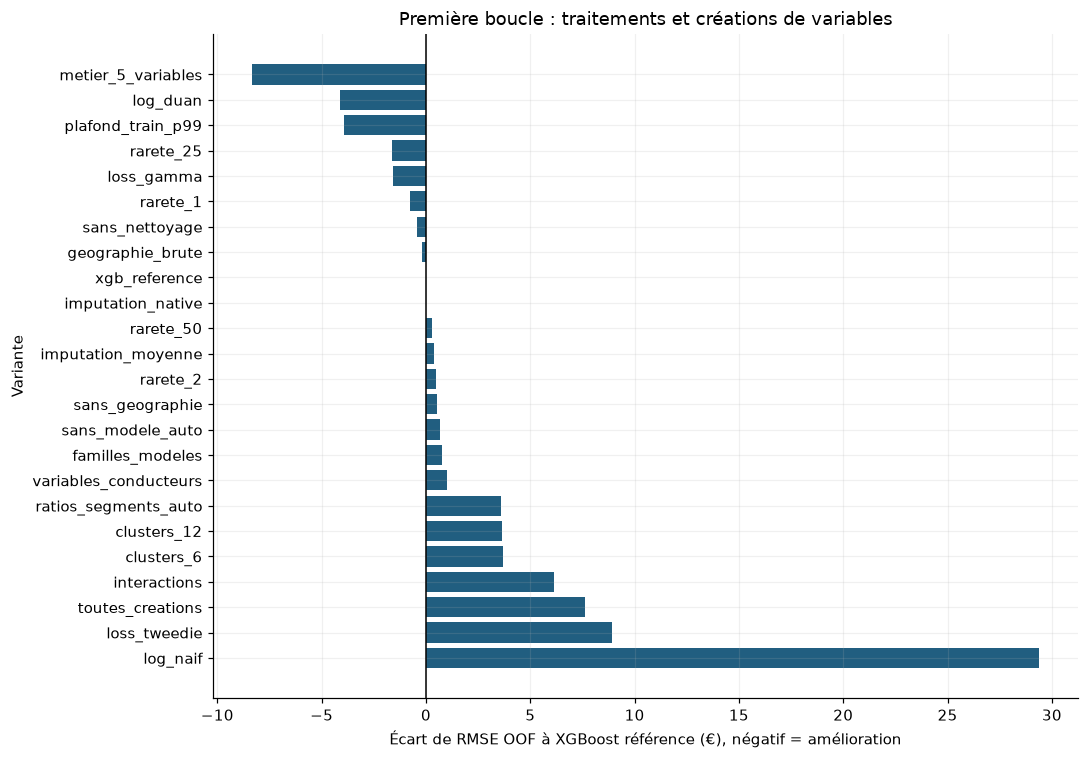

In [9]:
designs=[
 ('xgb_reference',{},'Référence toutes variables admissibles nettoyées, rareté 10.'),
 ('loss_gamma',{'objective':'reg:gamma'},'Moyenne positive, perte relative Gamma.'),
 ('loss_tweedie',{'objective':'reg:tweedie'},'Perte Tweedie, puissance fixée à 1,5.'),
 ('log_naif',{'target':'log_naive'},'Diagnostic du biais de retransformation naïve.'),
 ('log_duan',{'target':'log_smear'},'Correction log estimée en CV interne par client.'),
 ('rarete_1',{'min_frequency':1},'Conserver toutes les catégories vues.'),
 ('rarete_2',{'min_frequency':2},'Mutualiser seulement les singletons.'),
 ('rarete_25',{'min_frequency':25},'Regroupement plus fort des modalités rares.'),
 ('rarete_50',{'min_frequency':50},'Regroupement fort pour réduire la variance.'),
 ('familles_modeles',{'profile':'family'},'Regrouper le premier token au sein de la marque.'),
 ('sans_modele_auto',{'profile':'no_model'},'Vérifier la valeur ajoutée du nom du modèle.'),
 ('metier_5_variables',{'profile':'core'},'Couverture, prix, âge véhicule, bonus et usage.'),
 ('ratios_segments_auto',{'profile':'technical'},'Ajouter ratios physiques, log et segments.'),
 ('variables_conducteurs',{'profile':'driver'},'Ajouter expérience et écarts entre conducteurs.'),
 ('interactions',{'profile':'interactions'},'Bloc technique + couverture croisée usage/segment.'),
 ('toutes_creations',{'profile':'all'},'Combiner familles, ratios, conducteurs et interactions.'),
 ('clusters_6',{'profile':'technical','cluster_k':6},'Six groupes techniques appris dans chaque pli.'),
 ('clusters_12',{'profile':'technical','cluster_k':12},'Douze groupes techniques, risque de fragmentation.'),
 ('geographie_brute',{'geography':'raw'},'Tester le code géographique entier malgré sa cardinalité.'),
 ('sans_geographie',{'geography':'none'},'Tester le retrait du proxy géographique.'),
 ('sans_nettoyage',{'clean':False},'Mesurer l’effet du traitement des codes suspects.'),
 ('imputation_native',{'imputation':'native'},'Laisser les NaN numériques à XGBoost.'),
 ('imputation_moyenne',{'imputation':'mean'},'Moyenne contre médiane et indicateurs.'),
 ('plafond_train_p99',{'cap':.99},'Limiter les extrêmes uniquement dans les cibles du sous-train.'),
]
for name,delta,reason in designs:
    evaluate(name,{**BASE,**delta},'conception',reason)
ranking_design=pd.DataFrame(trial_rows).query("stage == 'conception'").sort_values('rmse')
display(ranking_design.head(12))
reference=ranking_design.set_index('name').loc['xgb_reference','rmse']
fig,ax=plt.subplots(figsize=(10,7))
t=ranking_design.sort_values('rmse',ascending=False)
ax.barh(t.name,t.rmse-reference); ax.axvline(0,color='black',linewidth=1)
ax.set(xlabel='Écart de RMSE OOF à XGBoost référence (€), négatif = amélioration',ylabel='Variante',title='Première boucle : traitements et créations de variables')
savefig('04_comparaison_conceptions')

In [10]:
indexed=ranking_design.set_index('name')
for label,names in {
    'Pertes / cible':['xgb_reference','loss_gamma','loss_tweedie','log_naif','log_duan'],
    'Rareté / regroupements auto':['rarete_1','rarete_2','xgb_reference','rarete_25','rarete_50','familles_modeles','sans_modele_auto','clusters_6','clusters_12'],
    'Créations':['xgb_reference','ratios_segments_auto','variables_conducteurs','interactions','toutes_creations'],
    'Qualité / géographie':['xgb_reference','geographie_brute','sans_geographie','sans_nettoyage','imputation_native','imputation_moyenne','plafond_train_p99'],
}.items():
    t=indexed.loc[names].sort_values('rmse')
    note(f'**{label} :** meilleure variante de ce bloc = `{t.index[0]}`, RMSE {t.iloc[0].rmse:,.2f} €, '
         f'écart à la référence {t.iloc[0].rmse-reference:+,.2f} €. '
         'Ce résultat reste une comparaison de développement, avec des fluctuations entre plis.')

**Pertes / cible :** meilleure variante de ce bloc = `log_duan`, RMSE 1,458.63 €, écart à la référence -4.12 €. Ce résultat reste une comparaison de développement, avec des fluctuations entre plis.

**Rareté / regroupements auto :** meilleure variante de ce bloc = `rarete_25`, RMSE 1,461.15 €, écart à la référence -1.61 €. Ce résultat reste une comparaison de développement, avec des fluctuations entre plis.

**Créations :** meilleure variante de ce bloc = `xgb_reference`, RMSE 1,462.75 €, écart à la référence +0.00 €. Ce résultat reste une comparaison de développement, avec des fluctuations entre plis.

**Qualité / géographie :** meilleure variante de ce bloc = `plafond_train_p99`, RMSE 1,458.85 €, écart à la référence -3.91 €. Ce résultat reste une comparaison de développement, avec des fluctuations entre plis.

### 4.3 Deuxième boucle : optimisation des hyperparamètres

On retient les **deux meilleures conceptions** de la première boucle et on explore pour chacune 12 combinaisons déterministes de paramètres : profondeur 1–4, nombre d'arbres, taux d'apprentissage, poids minimal des feuilles, L1/L2 et sous-échantillonnage. `ParameterSampler` produit ce plan fixé par graine ; on évite un produit cartésien démesuré sur ce petit échantillon.

Le nombre d'arbres est sélectionné par CV. Il n'y a pas d'early stopping sur le pli servant au score : cela utiliserait une même validation pour choisir les itérations et les évaluer. Les réglages sont appris exclusivement sur le développement. Une profondeur plus forte peut baisser l'erreur train tout en détériorant la validation ; l'écart sera montré.

In [11]:
space=dict(n_estimators=[80,180,360,600],max_depth=[1,2,3,4],learning_rate=[.02,.04,.08],
           min_child_weight=[5,20,50],reg_lambda=[5,20,80],reg_alpha=[0,5,20],
           subsample=[.7,.9,1.],colsample_bytree=[.7,1.])
param_draws=list(ParameterSampler(space,n_iter=12,random_state=SEED))
for parent in ranking_design.name.head(2):
    for j,delta in enumerate(param_draws):
        evaluate(f'tune_{parent}_{j:02d}', {**registry[parent]['config'],**delta},'optimisation',
                 f'Parent {parent}; tirage déterministe {j+1}/12.')
ranking_tuned=pd.DataFrame(trial_rows).query("stage != 'baseline'").sort_values('rmse')
display(ranking_tuned.head(12))
PRESELECTED=ranking_tuned.iloc[0]['name']
pre_cfg=registry[PRESELECTED]['config']
note(f'**Avant sélection a posteriori :** `{PRESELECTED}`, RMSE OOF {ranking_tuned.iloc[0].rmse:,.2f} €. '
     f'Configuration : `{json.dumps(pre_cfg,ensure_ascii=False)}`.')

tune_metier_5_variables_00       RMSE OOF= 1468.00 € ; MAE= 934.58 € ; 0.4s


tune_metier_5_variables_01       RMSE OOF= 1511.97 € ; MAE= 970.66 € ; 0.8s


tune_metier_5_variables_02       RMSE OOF= 1452.52 € ; MAE= 929.80 € ; 0.4s


tune_metier_5_variables_03       RMSE OOF= 1460.71 € ; MAE= 930.94 € ; 0.5s


tune_metier_5_variables_04       RMSE OOF= 1469.20 € ; MAE= 939.52 € ; 0.5s


tune_metier_5_variables_05       RMSE OOF= 1472.49 € ; MAE= 941.15 € ; 0.9s


... (16 outputs left out)

tune_log_duan_10                 RMSE OOF= 1473.25 € ; MAE= 956.88 € ; 1.8s


tune_log_duan_11                 RMSE OOF= 1455.97 € ; MAE= 940.01 € ; 1.5s


,name,stage,train_rmse,rmse,mae,gamma_deviance,r2,ratio_predit_observe,moyenne_predite,raison,fold_rmse_std,seconds
29,tune_metier_5_variables_02,optimisation,"1,415.299","1,452.520",929.804,0.399,0.012,0.998,"1,763.357",Parent metier_5_variables; tirage déterministe...,131.681,0.403
34,tune_metier_5_variables_07,optimisation,"1,427.310","1,453.220",931.109,0.400,0.011,0.998,"1,762.907",Parent metier_5_variables; tirage déterministe...,136.778,0.457
36,tune_metier_5_variables_09,optimisation,"1,432.287","1,453.683",931.170,0.400,0.010,0.999,"1,765.958",Parent metier_5_variables; tirage déterministe...,132.327,0.319
14,metier_5_variables,conception,"1,417.312","1,454.436",928.510,0.401,0.009,0.996,"1,760.878","Couverture, prix, âge véhicule, bonus et usage.",136.011,0.358
47,tune_log_duan_08,optimisation,"1,435.930","1,454.522",937.142,0.401,0.009,0.999,"1,766.173",Parent log_duan; tirage déterministe 9/12.,134.647,1.336
42,tune_log_duan_03,optimisation,"1,436.002","1,454.779",937.255,0.402,0.009,0.999,"1,766.079",Parent log_duan; tirage déterministe 4/12.,134.852,1.744
46,tune_log_duan_07,optimisation,"1,447.216","1,454.877",938.321,0.402,0.009,1.000,"1,767.139",Parent log_duan; tirage déterministe 8/12.,135.354,1.508
33,tune_metier_5_variables_06,optimisation,"1,412.166","1,455.166",928.856,0.401,0.008,0.995,"1,758.349",Parent metier_5_variables; tirage déterministe...,136.977,0.455
48,tune_log_duan_09,optimisation,"1,426.540","1,455.380",941.082,0.402,0.008,1.008,"1,780.667",Parent log_duan; tirage déterministe 10/12.,131.573,2.322
43,tune_log_duan_04,optimisation,"1,430.378","1,455.545",938.985,0.402,0.008,1.002,"1,770.458",Parent log_duan; tirage déterministe 5/12.,134.833,1.939


**Avant sélection a posteriori :** `tune_metier_5_variables_02`, RMSE OOF 1,452.52 €. Configuration : `{"profile": "core", "clean": true, "geography": "prefix", "min_frequency": 10, "objective": "reg:squarederror", "target": "identity", "n_estimators": 180, "max_depth": 3, "learning_rate": 0.02, "min_child_weight": 20, "reg_lambda": 5, "subsample": 1.0, "colsample_bytree": 0.7, "cluster_k": 0, "imputation": "median", "drop": [], "reg_alpha": 5}`.

### 4.4 Sélection de variables a posteriori et contrôle du sur-apprentissage

Sur le meilleur candidat de développement, on retire successivement neuf blocs ou sources : identité automobile, géographie, gestion, conducteurs, caractéristiques techniques, couverture, bonus, usage et mesures techniques redondantes. Les variables dérivées d'une source sont également retirées ; un cluster technique est supprimé lors du retrait du bloc technique.

Le retrait d'un bloc ne prouve pas l'inutilité de chaque variable qu'il contient : les arbres peuvent substituer des variables corrélées. On ajoute un candidat combinant les blocs dont le retrait a amélioré la RMSE, puis on le réévalue ; les gains individuels ne s'additionnent pas automatiquement. Toutes ces décisions sont prises avant le holdout. Si un bloc était déjà absent du profil retenu, son ablation est sans effet : elle documente cette absence et ne constitue pas une preuve indépendante.

sans_bloc_identite_auto          RMSE OOF= 1452.52 € ; MAE= 929.80 € ; 0.4s


sans_bloc_geographie             RMSE OOF= 1452.52 € ; MAE= 929.80 € ; 0.3s


sans_bloc_gestion                RMSE OOF= 1452.52 € ; MAE= 929.80 € ; 0.4s


sans_bloc_conducteurs            RMSE OOF= 1452.52 € ; MAE= 929.80 € ; 0.3s


sans_bloc_technique_auto         RMSE OOF= 1463.22 € ; MAE= 936.35 € ; 0.3s


sans_bloc_couverture             RMSE OOF= 1453.42 € ; MAE= 934.24 € ; 0.2s


... (3 outputs left out)

,rmse,mae,train_rmse,delta_rmse_vs_parent,colonnes_retirees
name,,,,,
sans_bloc_bonus,"1,450.707",929.470,"1,417.121",-1.814,1
sans_bloc_usage,"1,452.319",928.602,"1,419.294",-0.201,1
sans_bloc_identite_auto,"1,452.520",929.804,"1,415.299",0.000,0
sans_bloc_geographie,"1,452.520",929.804,"1,415.299",0.000,0
sans_bloc_conducteurs,"1,452.520",929.804,"1,415.299",0.000,0
sans_bloc_gestion,"1,452.520",929.804,"1,415.299",0.000,0
sans_bloc_redondantes_auto,"1,452.520",929.804,"1,415.299",0.000,0
sans_bloc_couverture,"1,453.419",934.239,"1,418.521",0.899,1
sans_bloc_technique_auto,"1,463.218",936.345,"1,439.192",10.697,2


ablation_combinee                RMSE OOF= 1449.73 € ; MAE= 929.35 € ; 0.3s


,name,stage,train_rmse,rmse,mae,gamma_deviance,r2,ratio_predit_observe,moyenne_predite,raison,fold_rmse_std,seconds
60,ablation_combinee,ablation,"1,421.135","1,449.729",929.352,0.397,0.016,0.999,"1,766.294",Combinaison des retraits favorables individuel...,136.836,0.279
57,sans_bloc_bonus,ablation,"1,417.121","1,450.707",929.470,0.397,0.014,0.998,"1,764.466","Retrait bonus et dérivées, parent tune_metier_...",136.683,0.282
58,sans_bloc_usage,ablation,"1,419.294","1,452.319",928.602,0.399,0.012,0.998,"1,764.213","Retrait usage et dérivées, parent tune_metier_...",133.522,0.277
29,tune_metier_5_variables_02,optimisation,"1,415.299","1,452.520",929.804,0.399,0.012,0.998,"1,763.357",Parent metier_5_variables; tirage déterministe...,131.681,0.403
51,sans_bloc_identite_auto,ablation,"1,415.299","1,452.520",929.804,0.399,0.012,0.998,"1,763.357","Retrait identite_auto et dérivées, parent tune...",131.681,0.390
52,sans_bloc_geographie,ablation,"1,415.299","1,452.520",929.804,0.399,0.012,0.998,"1,763.357","Retrait geographie et dérivées, parent tune_me...",131.681,0.332
53,sans_bloc_gestion,ablation,"1,415.299","1,452.520",929.804,0.399,0.012,0.998,"1,763.357","Retrait gestion et dérivées, parent tune_metie...",131.681,0.388
54,sans_bloc_conducteurs,ablation,"1,415.299","1,452.520",929.804,0.399,0.012,0.998,"1,763.357","Retrait conducteurs et dérivées, parent tune_m...",131.681,0.314
59,sans_bloc_redondantes_auto,ablation,"1,415.299","1,452.520",929.804,0.399,0.012,0.998,"1,763.357","Retrait redondantes_auto et dérivées, parent t...",131.681,0.260
34,tune_metier_5_variables_07,optimisation,"1,427.310","1,453.220",931.109,0.400,0.011,0.998,"1,762.907",Parent metier_5_variables; tirage déterministe...,136.778,0.457


**Recette gelée :** `ablation_combinee` parmi 58 XGBoost évalués. RMSE OOF 1,449.73 €, MAE 929.35 €. Le score minimum de CV est optimiste après de nombreux essais : le holdout réservé donne la prochaine évaluation.

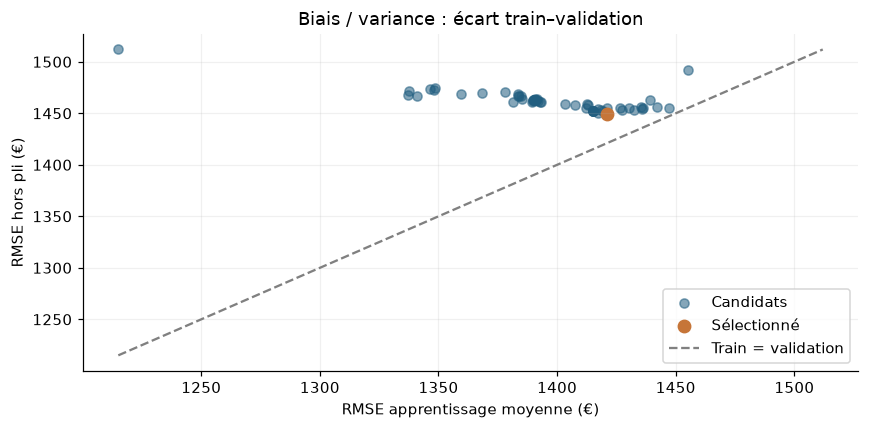

In [12]:
ablation_names=[]
for group in ['identite_auto','geographie','gestion','conducteurs','technique_auto','couverture','bonus','usage','redondantes_auto']:
    name='sans_bloc_'+group
    ablation_names.append(name)
    drop=tuple(dict.fromkeys(tuple(pre_cfg.get('drop',()))+(group,)))
    evaluate(name,{**pre_cfg,'drop':drop},'ablation',f'Retrait {group} et dérivées, parent {PRESELECTED}.')
parent_rmse=float(pd.DataFrame(trial_rows).set_index('name').loc[PRESELECTED,'rmse'])
a=pd.DataFrame(trial_rows).set_index('name').loc[ablation_names].copy()
a['delta_rmse_vs_parent']=a.rmse-parent_rmse
base_columns=set(SeverityFeatures(**{k:pre_cfg[k] for k in ['profile','clean','geography','cluster_k','drop'] if k in pre_cfg}).fit_transform(X).columns)
a['colonnes_retirees']=[len(base_columns-set(SeverityFeatures(**{k:registry[n]['config'][k] for k in ['profile','clean','geography','cluster_k','drop'] if k in registry[n]['config']}).fit_transform(X).columns)) for n in a.index]
display(a[['rmse','mae','train_rmse','delta_rmse_vs_parent','colonnes_retirees']].sort_values('rmse'))
useful_drops=[name.removeprefix('sans_bloc_') for name in a.index[a.delta_rmse_vs_parent.lt(0)]]
if len(useful_drops)>1:
    evaluate('ablation_combinee',{**pre_cfg,'drop':tuple(useful_drops)},'ablation',
             'Combinaison des retraits favorables individuellement, nouvelle mesure CV.')
ranking=pd.DataFrame(trial_rows).query("stage != 'baseline'").sort_values(['rmse','train_rmse'])
SELECTED=str(ranking.iloc[0]['name']); CONFIG=registry[SELECTED]['config']
SELECTED_OOF=oof_predictions[SELECTED]
LOCKED_CONFIG=json.loads(json.dumps(CONFIG))
selection={'name':SELECTED,'config':LOCKED_CONFIG,'criterion':'RMSE OOF euros, development only',
           'oof_scores':scores(y,SELECTED_OOF),'n_candidates':len(registry),'seed':SEED,
           'holdout_used_for_selection':False}
(REPORTS/'selection_gelee_avant_holdout.json').write_text(json.dumps(selection,indent=2,ensure_ascii=False))
(REPORTS/'configurations_essais.json').write_text(json.dumps(registry,indent=2,ensure_ascii=False))
pd.DataFrame(trial_rows).to_csv(REPORTS/'journal_essais.csv',index=False)
pd.DataFrame(fold_rows).to_csv(REPORTS/'scores_par_pli.csv',index=False)
display(ranking.head(15))
note(f'**Recette gelée :** `{SELECTED}` parmi {len(registry)} XGBoost évalués. '
     f'RMSE OOF {scores(y,SELECTED_OOF)["rmse"]:,.2f} €, MAE {scores(y,SELECTED_OOF)["mae"]:,.2f} €. '
     'Le score minimum de CV est optimiste après de nombreux essais : le holdout réservé donne la prochaine évaluation.')
fig,ax=plt.subplots(figsize=(8,4))
t=pd.DataFrame(trial_rows).query("stage != 'baseline'")
ax.scatter(t.train_rmse,t.rmse,alpha=.55,label='Candidats')
ax.scatter([ranking.iloc[0].train_rmse],[ranking.iloc[0].rmse],s=65,label='Sélectionné')
lo=min(t.train_rmse.min(),t.rmse.min()); hi=max(t.train_rmse.max(),t.rmse.max())
ax.plot([lo,hi],[lo,hi],linestyle='--',color='grey',label='Train = validation')
ax.set(xlabel='RMSE apprentissage moyenne (€)',ylabel='RMSE hors pli (€)',title='Biais / variance : écart train–validation'); ax.legend()
savefig('05_train_validation')

## 5. Validation du modèle

### 5.1 Validation du sens : importance et effets

L'importance par permutation est mesurée **hors pli sur le développement**, avec trois répétitions et les modèles déjà entraînés sur leurs sous-trains. Elle permute les variables brutes avant toutes les créations : changer `prix_vehicule` recalcule donc aussi ses ratios et segments. Une importance proche de zéro peut traduire une redondance ; une importance négative peut être du bruit. L'importance n'établit pas de causalité.

Les profils de prédiction maintiennent les autres caractéristiques observées et font varier prix, âge véhicule ou couverture sur un échantillon du développement. Ces profils peuvent créer des combinaisons peu réalistes ; ils servent à repérer des comportements absurdes, pas à recommander une modification individuelle du tarif. Aucune sélection ne sera refaite après le holdout.

,mean,std
variable,,
anciennete_vehicule,11.935,3.954
type_contrat,4.190,3.578
prix_vehicule,4.178,4.630
age_conducteur1,0.000,0.000
age_conducteur2,0.000,0.000
anciennete_permis2,0.000,0.000
bonus,0.000,0.000
anciennete_permis1,0.000,0.000
anciennete_info,0.000,0.000


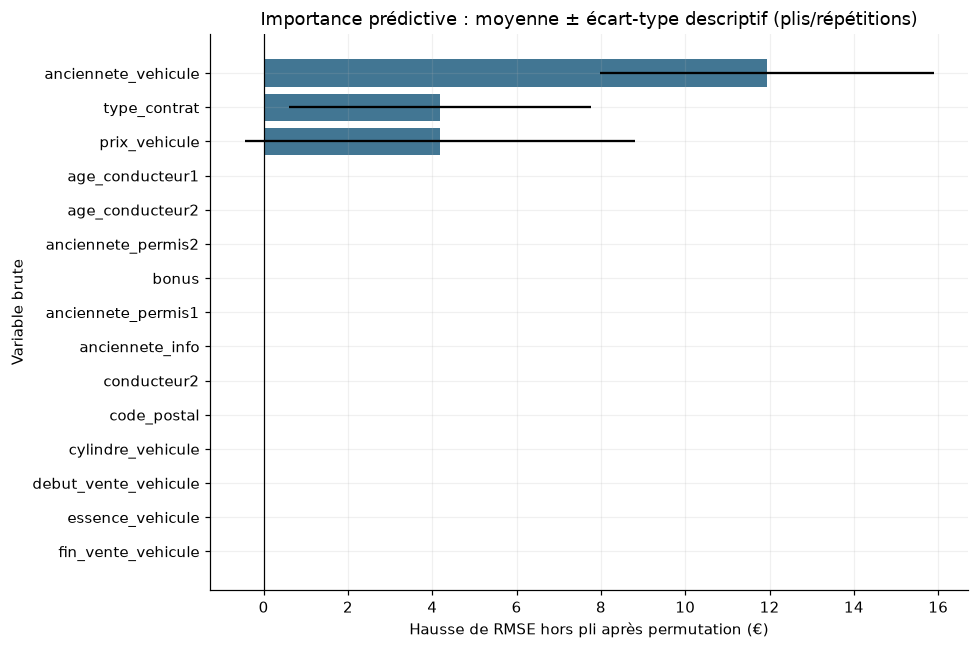

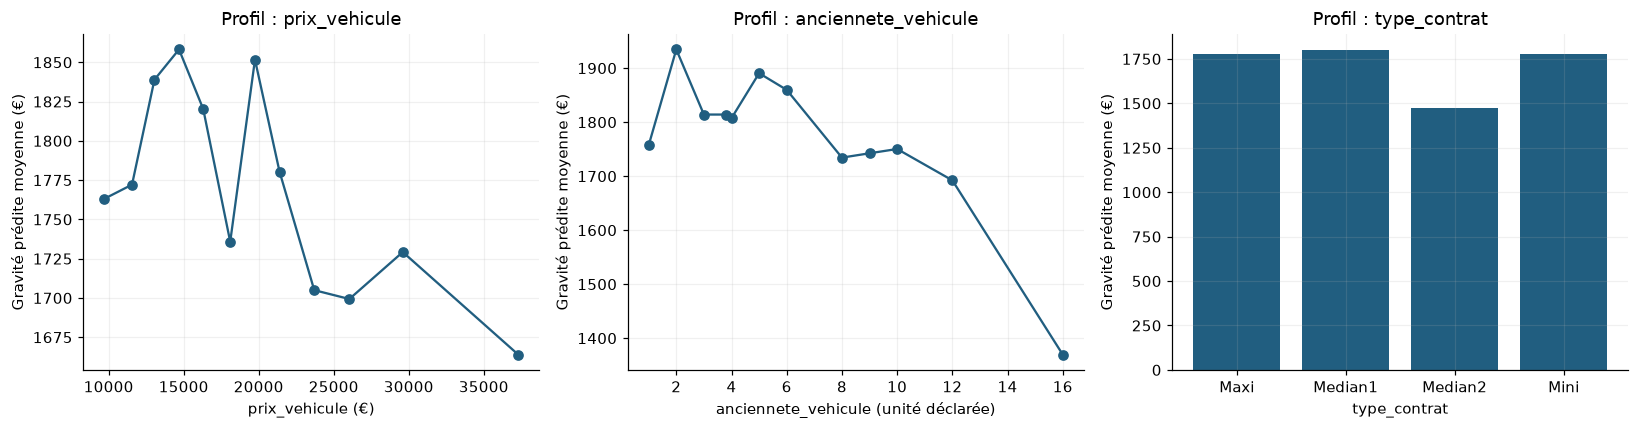

In [13]:
permutation_rows=[]
for k,(tr,va) in enumerate(FOLDS):
    m=cv_models[SELECTED][k]
    # RMSE negative dans sklearn : importance positive = hausse de RMSE après permutation.
    imp=permutation_importance(m,X.iloc[va],y[va],n_repeats=3,random_state=SEED+k,
                               scoring='neg_root_mean_squared_error',n_jobs=1)
    for j,c in enumerate(FEATURES):
        for rep,v in enumerate(imp.importances[j]):
            permutation_rows.append({'fold':k,'variable':c,'repeat':rep,'hausse_rmse':float(v)})
permutations=pd.DataFrame(permutation_rows)
importance=permutations.groupby('variable').hausse_rmse.agg(['mean','std']).sort_values('mean',ascending=False)
permutations.to_csv(REPORTS/'permutation_repetitions_developpement.csv',index=False)
importance.to_csv(REPORTS/'importance_permutation_developpement.csv')
display(importance)
fig,ax=plt.subplots(figsize=(9,6))
t=importance.head(15).iloc[::-1]; ax.barh(t.index,t['mean'],xerr=t['std'],alpha=.85)
ax.axvline(0,color='black',linewidth=.8)
ax.set(xlabel='Hausse de RMSE hors pli après permutation (€)',ylabel='Variable brute',title='Importance prédictive : moyenne ± écart-type descriptif (plis/répétitions)')
savefig('06_importances')
with threadpool_limits(limits=2):
    development_model=SeverityEstimator(CONFIG).fit(X,y,groups)
sample=X.sample(min(400,len(X)),random_state=SEED)
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,col in zip(axes,['prix_vehicule','anciennete_vehicule','type_contrat']):
    values=np.quantile(X[col].dropna(),np.linspace(.05,.95,12)) if pd.api.types.is_numeric_dtype(X[col]) else sorted(X[col].dropna().unique())
    means=[]
    for val in values:
        v=sample.copy(); v[col]=val; means.append(development_model.predict(v).mean())
    if pd.api.types.is_numeric_dtype(X[col]): ax.plot(values,means,marker='o')
    else: ax.bar(values,means)
    ax.set(xlabel=col+(' (€)' if col=='prix_vehicule' else ' (unité déclarée)' if col=='anciennete_vehicule' else ''),
           ylabel='Gravité prédite moyenne (€)',title='Profil : '+col)
savefig('07_profils_predictions')
if CONFIG.get('cluster_k',0) and 'technique_auto' not in CONFIG.get('drop',[]):
    f=development_model.pipeline_.named_steps['features']
    z=f.transform(X)
    cluster_table=X.copy(); cluster_table['cluster']=z.groupe_auto_cluster
    cluster_summary=cluster_table.groupby('cluster').agg(n=('prix_vehicule','size'),prix_median=('prix_vehicule','median'),
                  puissance_mediane=('din_vehicule','median'),poids_median=('poids_vehicule','median'))
    display(cluster_summary); cluster_summary.to_csv(REPORTS/'clusters_retenus_profils.csv')

### 5.2 Évaluation unique du holdout réservé

La configuration est maintenant figée et enregistrée. On entraîne cette recette sur tous les sinistrés du développement, puis on évalue le holdout **une seule fois**. Les références moyenne, médiane et Gamma métier sont également recalculées sur le développement pour comparaison. Les sous-groupes et gros sinistres sont ensuite examinés à titre de diagnostic ; ils ne changent pas la recette.

L'intervalle du gain de RMSE utilise 1 000 rééchantillonnages **de clients**, en gardant ensemble leurs contrats. Il décrit l'incertitude d'échantillonnage du holdout pour cette recette figée ; il ne couvre pas tout le processus de recherche ni un changement de portefeuille.

In [14]:
hold=hold_portfolio.loc[hold_portfolio.nombre_sinistres.gt(0)].copy().reset_index(drop=True)
Xh,yh,gh=hold[FEATURES],hold[TARGET].to_numpy(),hold.id_client.to_numpy()
assert len(yh)>0 and not set(groups)&set(gh)
assert CONFIG==registry[SELECTED]['config']
ph=development_model.predict(Xh)
pmean=np.repeat(y.mean(),len(yh)); pmedian=np.repeat(np.median(y),len(yh))
gamma_hold=Pipeline([('features',SeverityFeatures(profile='core')),
    ('encoding',ColumnTransformer([
      ('num',Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]),make_column_selector(dtype_include=np.number)),
      ('cat',OneHotEncoder(handle_unknown='ignore'),make_column_selector(dtype_exclude=np.number))])),
    ('gamma',GammaRegressor(alpha=.1,max_iter=2000))]).fit(X,y)
pgamma=gamma_hold.predict(Xh)
hold_results=pd.DataFrame([{'modele':name,**scores(yh,p)} for name,p in
    [('moyenne_dev',pmean),('mediane_dev',pmedian),('Gamma_metier',pgamma),('XGBoost_gelee',ph)]])
hold_results.to_csv(REPORTS/'holdout_metriques.csv',index=False)
display(hold_results)
held_predictions=hold[['index','id_client',TARGET]+[c for c in ['type_contrat','prix_vehicule','modele_vehicule']]].copy()
held_predictions['gravite_predite']=ph; held_predictions['baseline_moyenne']=pmean
held_predictions['erreur']=ph-yh; held_predictions['erreur_absolue']=abs(ph-yh)
held_predictions.to_csv(REPORTS/'holdout_predictions.csv',index=False)
unique_g=np.unique(gh); group_rows=[np.flatnonzero(gh==g) for g in unique_g]
rng=np.random.default_rng(SEED)
bootstrap=[]
for _ in range(1000):
    ii=np.concatenate([group_rows[j] for j in rng.integers(0,len(unique_g),len(unique_g))])
    bootstrap.append(rmse(yh[ii],pmean[ii])-rmse(yh[ii],ph[ii]))
ci=np.quantile(bootstrap,[.025,.5,.975])
bootstrap_summary={'gain_rmse_vs_mean':rmse(yh,pmean)-rmse(yh,ph),'ci_95_low':float(ci[0]),
                   'ci_95_high':float(ci[2]),'replicates':1000,'unit':'client','n_clients':len(unique_g)}
(REPORTS/'holdout_bootstrap_clients.json').write_text(json.dumps(bootstrap_summary,indent=2))
note(f'**Holdout :** {len(hold)} contrats sinistrés, {len(unique_g)} clients. '
     f'RMSE XGBoost {rmse(yh,ph):,.2f} € ; référence moyenne {rmse(yh,pmean):,.2f} €. '
     f'Gain {bootstrap_summary["gain_rmse_vs_mean"]:+,.2f} €, intervalle bootstrap 95 % [{ci[0]:+,.2f} ; {ci[2]:+,.2f}] €. '
     + ('Le gain est positif sur cet intervalle.' if ci[0]>0 else 'Cet intervalle ne démontre pas un gain positif stable face à la moyenne.'))

,modele,rmse,mae,gamma_deviance,r2,ratio_predit_observe,moyenne_predite
0,moyenne_dev,"1,473.698",951.956,0.406,-0.000,0.987,"1,767.305"
1,mediane_dev,"1,574.530",838.119,0.563,-0.142,0.690,"1,236.000"
2,Gamma_metier,"1,457.208",930.397,0.390,0.022,0.993,"1,777.586"
3,XGBoost_gelee,"1,465.774",936.837,0.398,0.010,0.991,"1,775.510"


**Holdout :** 561 contrats sinistrés, 558 clients. RMSE XGBoost 1,465.77 € ; référence moyenne 1,473.70 €. Gain +7.92 €, intervalle bootstrap 95 % [-4.85 ; +22.38] €. Cet intervalle ne démontre pas un gain positif stable face à la moyenne.

### 5.3 Analyse des erreurs, calibration et sinistres coûteux

Les seuils P90/P95/P99 des montants proviennent du développement. On mesure la fiabilité sur la queue du holdout et la part d'erreur quadratique qu'elle explique. Une bonne moyenne globale peut masquer une sous-estimation des gros sinistres.

La calibration est montrée par déciles de prédiction, avec montants moyens observés et prédits. Le diagnostic par couverture, usage, tranche de prix, âge et marque conserve les effectifs ; les petits groupes sont explicitement marqués. Ces mesures restent conditionnelles au fait d'être sinistré.

,segment_cout,n,observe_moyen,predit_moyen,part_erreur_carree,rmse,mae,gamma_deviance,r2,ratio_predit_observe,moyenne_predite
0,tous,561,"1,790.903","1,775.510",1.000,"1,465.774",936.837,0.398,0.010,0.991,"1,775.510"
1,>= P90 dev,56,"5,097.725","1,840.981",0.743,"3,999.690","3,256.745",1.675,-2.005,0.361,"1,840.981"
2,>= P95 dev,29,"6,295.183","1,818.932",0.657,"5,223.998","4,476.251",2.606,-2.777,0.289,"1,818.932"
3,>= P99 dev,4,"12,316.087","1,867.426",0.392,"10,868.357","10,448.662",7.676,-13.019,0.152,"1,867.426"


,variable,groupe,n,petit_groupe,rmse,mae,gamma_deviance,r2,ratio_predit_observe,moyenne_predite
42,anciennete_vehicule,"(-inf, 3.0]",178,False,"1,856.909","1,092.606",0.476,-0.009,0.940,"1,865.342"
48,prix_vehicule,"(18750.0, 25100.0]",138,False,"1,746.982","1,017.246",0.456,-0.012,0.968,"1,793.669"
7,utilisation,WorkPrivate,346,False,"1,617.505",972.986,0.430,0.001,0.948,"1,763.679"
30,marque_vehicule,PEUGEOT,113,False,"1,570.943","1,020.369",0.454,-0.002,0.986,"1,783.185"
0,type_contrat,Maxi,473,False,"1,554.627","1,008.877",0.428,-0.003,0.972,"1,829.326"
45,anciennete_vehicule,"(6.0, 10.0]",129,False,"1,526.934",991.175,0.434,0.003,0.919,"1,746.067"
40,marque_vehicule,VOLKSWAGEN,34,False,"1,409.760",970.177,0.421,-0.006,1.071,"1,779.824"
49,prix_vehicule,"(25100.0, inf]",153,False,"1,408.682",990.026,0.430,0.012,1.017,"1,794.049"
47,prix_vehicule,"(13753.0, 18750.0]",130,False,"1,401.602",914.076,0.378,0.016,1.023,"1,808.344"
5,utilisation,Professional,56,False,"1,335.732","1,000.246",0.415,-0.013,0.985,"1,841.588"


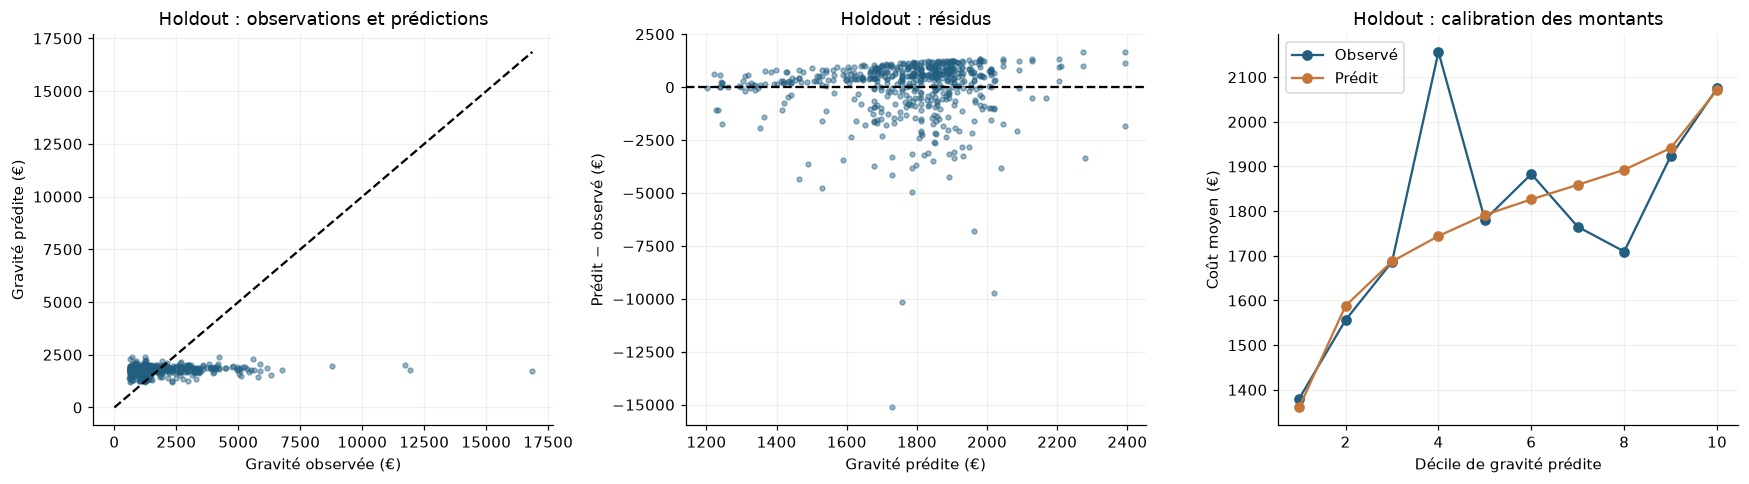

,index,id_client,montant_sinistre,type_contrat,prix_vehicule,modele_vehicule,gravite_predite,baseline_moyenne,erreur,erreur_absolue
312,27721,A00025406,"16,859.400",Maxi,24450,ASTRA,"1,728.845","1,767.305","-15,130.555","15,130.555"
307,27492,A00025192,"11,906.240",Maxi,18450,307,"1,758.175","1,767.305","-10,148.065","10,148.065"
314,27763,A00025444,"11,724.250",Maxi,30700,116,"2,020.859","1,767.305","-9,703.391","9,703.391"
76,6148,A00005613,"8,774.460",Maxi,10998,MODUS,"1,961.823","1,767.305","-6,812.637","6,812.637"
113,9407,A00008612,"6,756.670",Maxi,10245,POLO,"1,785.403","1,767.305","-4,971.267","4,971.267"
219,18857,A00017261,"6,314.390",Maxi,23310,PASSAT,"1,530.555","1,767.305","-4,783.835","4,783.835"
404,36664,A00033603,"5,791.360",Median2,11327,FIESTA,"1,464.608","1,767.305","-4,326.752","4,326.752"
297,26531,A00024317,"6,153.390",Maxi,20000,307,"1,890.880","1,767.305","-4,262.510","4,262.510"
158,13369,A00012240,"5,862.360",Maxi,26250,A200,"1,728.845","1,767.305","-4,133.515","4,133.515"
136,11328,A00010361,"5,881.250",Maxi,19200,MITO,"2,038.845","1,767.305","-3,842.405","3,842.405"


**Calibration globale :** le modèle prédit 996,061 € pour 1,004,696 € observés, soit un ratio 0.991. On ne corrige pas ce ratio à partir du holdout : il est un résultat de validation. Ces sommes portent seulement sur les contrats sinistrés et ne permettent pas de conclure à la rentabilité d’un assureur.

In [15]:
error_rows=[]
for label,mask in [('tous',np.ones(len(yh),dtype=bool))]+[(f'>= P{int(100*q)} dev',yh>=np.quantile(y,q)) for q in [.9,.95,.99]]:
    if mask.sum():
        error_rows.append({'segment_cout':label,'n':int(mask.sum()),'observe_moyen':yh[mask].mean(),
            'predit_moyen':ph[mask].mean(),'part_erreur_carree':((ph[mask]-yh[mask])**2).sum()/((ph-yh)**2).sum(),
            **scores(yh[mask],ph[mask])})
tail_errors=pd.DataFrame(error_rows); display(tail_errors)
tail_errors.to_csv(REPORTS/'holdout_erreurs_queue.csv',index=False)
cal=pd.DataFrame({'observe':yh,'predit':ph})
cal['decile']=pd.qcut(cal.predit.rank(method='first'),10,labels=False)+1
calibration=cal.groupby('decile').agg(n=('observe','size'),observe=('observe','mean'),predit=('predit','mean'))
calibration.to_csv(REPORTS/'holdout_calibration.csv')
segments=[]
for col in ['type_contrat','utilisation','marque_vehicule','anciennete_vehicule','prix_vehicule']:
    if pd.api.types.is_numeric_dtype(Xh[col]):
        bounds=np.unique(np.quantile(X[col].dropna(),[0,.25,.5,.75,1])); bounds[0]=-np.inf; bounds[-1]=np.inf
        lab=pd.cut(Xh[col],bounds,include_lowest=True).astype(str)
    else: lab=Xh[col].fillna('__MANQUANT__').astype(str)
    for value in sorted(lab.unique()):
        mask=lab.eq(value).to_numpy()
        segments.append({'variable':col,'groupe':value,'n':int(mask.sum()),'petit_groupe':bool(mask.sum()<30),
                         **scores(yh[mask],ph[mask])})
segments=pd.DataFrame(segments); segments.to_csv(REPORTS/'holdout_erreurs_segments.csv',index=False)
display(segments.loc[~segments.petit_groupe].sort_values('rmse',ascending=False).head(20))
fig,axes=plt.subplots(1,3,figsize=(16,4.5))
axes[0].scatter(yh,ph,s=10,alpha=.45); maxval=max(yh.max(),ph.max())
axes[0].plot([0,maxval],[0,maxval],linestyle='--',color='black')
axes[0].set(xlabel='Gravité observée (€)',ylabel='Gravité prédite (€)',title='Holdout : observations et prédictions')
axes[1].scatter(ph,ph-yh,s=10,alpha=.45); axes[1].axhline(0,color='black',linestyle='--')
axes[1].set(xlabel='Gravité prédite (€)',ylabel='Prédit − observé (€)',title='Holdout : résidus')
axes[2].plot(calibration.index,calibration.observe,marker='o',label='Observé')
axes[2].plot(calibration.index,calibration.predit,marker='o',label='Prédit')
axes[2].set(xlabel='Décile de gravité prédite',ylabel='Coût moyen (€)',title='Holdout : calibration des montants'); axes[2].legend()
savefig('08_holdout_diagnostics')
display(held_predictions.sort_values('erreur_absolue',ascending=False).head(12))
ratio=ph.sum()/yh.sum()
note(f'**Calibration globale :** le modèle prédit {ph.sum():,.0f} € pour {yh.sum():,.0f} € observés, soit un ratio {ratio:.3f}. '
     'On ne corrige pas ce ratio à partir du holdout : il est un résultat de validation. '
     'Ces sommes portent seulement sur les contrats sinistrés et ne permettent pas de conclure à la rentabilité d’un assureur.')

## 6. Sauvegarde, test et articulation avec la prime

### 6.1 Réentraînement sans nouvelle sélection

Après l'évaluation, la recette **inchangée** est réentraînée sur tous les sinistrés du train. Les prétraitements sont alors appris sur ce train complet, jamais sur le test. Le score holdout reste celui du modèle entraîné sur le développement ; il ne devient pas un score du modèle réentraîné.

On conserve la pipeline complète dans `models/gravite_pipeline.joblib`, le booster XGBoost en JSON et un manifeste avec configuration, versions, empreintes des données et scores. Le JSON seul ne suffit pas à reproduire les transformations ; le module et la pipeline font partie du livrable. On teste le rechargement, les valeurs manquantes et les catégories inconnues.

### 6.2 Sortie de gravité

`reports/gravite_test.csv` contient `index,gravite_predite` pour tous les contrats de test. Ce n'est **pas une soumission de prime**. Pour former ultérieurement une prime : joindre une probabilité de fréquence par `index`, vérifier la correspondance 1:1 puis calculer `prime_predite = probabilite_sinistre * gravite_predite`. Ne pas seuiller la probabilité. La validation de ce produit doit utiliser des prédictions des deux composantes obtenues hors apprentissage sur les mêmes contrats.

La case « soumission » de la roadmap est donc traitée au niveau de cette composante : sauvegarde et prédictions prêtes à être combinées. Une soumission Kaggle serait prématurée sans la composante fréquence validée.

In [16]:
retained_columns=development_model.pipeline_.named_steps['features'].transform(X).columns.tolist()
print('Variables effectivement présentées au modèle retenu :', retained_columns)
positive=train.loc[train.nombre_sinistres.gt(0)].copy()
with threadpool_limits(limits=2):
    final_model=SeverityEstimator(CONFIG).fit(positive[FEATURES],positive[TARGET].to_numpy(),positive.id_client.to_numpy())
ptest=final_model.predict(test[FEATURES])
assert len(ptest)==len(test) and np.isfinite(ptest).all() and (ptest>0).all()
output=pd.DataFrame({'index':test['index'].to_numpy(),'gravite_predite':ptest})
assert output['index'].equals(test['index']) and output['index'].is_unique
output.to_csv(REPORTS/'gravite_test.csv',index=False)
joblib.dump(final_model,MODELS/'gravite_pipeline.joblib')
final_model.pipeline_.named_steps['xgb'].get_booster().save_model(MODELS/'gravite_xgboost.json')
reloaded=joblib.load(MODELS/'gravite_pipeline.joblib')
np.testing.assert_allclose(reloaded.predict(test[FEATURES].iloc[:100]),ptest[:100],rtol=1e-10,atol=1e-8)
probe=test[FEATURES].head(5).copy()
for col in ['type_contrat','marque_vehicule','modele_vehicule','code_postal']:
    probe[col]='__CATEGORIE_INCONNUE__'
for col in probe.select_dtypes(include='number'):
    probe[col]=np.nan
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    probe_pred=reloaded.predict(probe)
assert np.isfinite(probe_pred).all() and (probe_pred>0).all()
assert not set(final_model.pipeline_.named_steps['features'].transform(positive[FEATURES]).columns)&FORBIDDEN
fingerprints={p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in [DATA/'train.csv',DATA/'test.csv']}
manifest={'selected':selection,'versions':VERSIONS,'data_sha256':fingerprints,'features':FEATURES,'retained_transformed_columns':retained_columns,
          'training_positive_rows':len(positive),'test_rows':len(output),
          'holdout_scores':hold_results.to_dict(orient='records'),'holdout_bootstrap':bootstrap_summary,
          'test_prediction_summary':output.gravite_predite.describe().to_dict(),
          'elapsed_seconds':time.time()-START,'reload_equal':True,'missing_unknown_categories_finite':True,
          'output_kind':'conditional severity; not premium; no Kaggle submission',
          'historical_data_previously_explored':True}
(REPORTS/'manifest.json').write_text(json.dumps(manifest,indent=2,ensure_ascii=False))
display(output.head())
display(output.gravite_predite.describe().to_frame('gravité test (€)'))
print('Contrôles réussis : séparation clients, cibles interdites, prédictions positives finies, rechargement, NaN et catégories inconnues.')

Variables effectivement présentées au modèle retenu : ['type_contrat', 'prix_vehicule', 'anciennete_vehicule']


,index,gravite_predite
0,50000,"1,410.725"
1,50001,"1,234.329"
2,50002,"2,023.161"
3,50003,"1,863.273"
4,50004,"1,253.796"


,gravité test (€)
count,"50,000.000"
mean,"1,672.779"
std,243.937
min,"1,159.157"
25%,"1,428.653"
50%,"1,752.829"
75%,"1,865.985"
max,"2,308.568"


Contrôles réussis : séparation clients, cibles interdites, prédictions positives finies, rechargement, NaN et catégories inconnues.


### 6.3 Représentativité et limites de généralisation

On examine **après le gel du modèle** la différence de structure entre développement sinistré, train complet et test. Les sinistrés peuvent avoir une distribution de variables différente de celle de tous les contrats : c'est lié au conditionnement de la cible. Le test n'a pas de cible ; ce contrôle ne mesure pas sa performance.

Les fréquences de catégories inconnues sont des signaux de fragilité. Les différences de médianes standardisées sont descriptives ; elles ne servent pas à recalibrer le modèle sur le test.

In [17]:
drift=[]
for c in FEATURES:
    a=positive[c]; b=test[c]
    if pd.api.types.is_numeric_dtype(a):
        scale=a.std()
        drift.append({'variable':c,'type':'numérique','taux_nouveaux_test':np.nan,
                      'ecart_medianes_sur_sd':float((b.median()-a.median())/scale) if scale>0 else 0.,
                      'na_train':a.isna().mean(),'na_test':b.isna().mean()})
    else:
        known=set(a.dropna().astype(str))
        drift.append({'variable':c,'type':'catégorielle','taux_nouveaux_test':float((~b.fillna('__NA__').astype(str).isin(known)).mean()),
                      'ecart_medianes_sur_sd':np.nan,'na_train':a.isna().mean(),'na_test':b.isna().mean()})
drift=pd.DataFrame(drift); drift.to_csv(REPORTS/'derive_structure_test.csv',index=False)
display(drift.sort_values('taux_nouveaux_test',ascending=False).head(12))

,variable,type,taux_nouveaux_test,ecart_medianes_sur_sd,na_train,na_test
7,code_postal,catégorielle,0.551,NaN,0.000,0.000
18,modele_vehicule,catégorielle,0.068,NaN,0.000,0.000
17,marque_vehicule,catégorielle,0.005,NaN,0.000,0.000
1,type_contrat,catégorielle,0.000,NaN,0.000,0.000
4,freq_paiement,catégorielle,0.000,NaN,0.000,0.000
5,paiement,catégorielle,0.000,NaN,0.000,0.000
8,conducteur2,catégorielle,0.000,NaN,0.000,0.000
6,utilisation,catégorielle,0.000,NaN,0.000,0.000
16,essence_vehicule,catégorielle,0.000,NaN,0.000,0.000
22,type_vehicule,catégorielle,0.000,NaN,0.000,0.000


## 7. Journal des choix, conclusion et pistes

Les essais de retrait d'un bloc déjà absent sont marqués par zéro colonne retirée : ils ne représentent pas des modèles prédictifs différents. Le fichier `journal_essais.csv` consigne chaque hypothèse, le score hors pli, le score train et le temps ; `scores_par_pli.csv` montre la stabilité ; `configurations_essais.json` donne toutes les configurations exactes. Les choix ne sont pas justifiés seulement par « XGBoost est performant » : l'apport de chaque transformation est mis à l'épreuve.

Le plan constitue une recherche bornée et reproductible, pas une preuve d'optimalité. Une mesure sur trois plis reste variable, et le minimum parmi beaucoup de candidats est optimiste. Les catégories rares, la queue de coûts, les unités non documentées et les corrélations limitent l'interprétation. Les clusters et familles ne doivent pas être présentés comme des classes métier certifiées.

La roadmap prévoit des retours à l'analyse, au traitement et au modèle : ils ont eu lieu **dans le développement** via les comparaisons et ablations. Les problèmes vus ensuite sur le holdout deviennent des hypothèses pour une prochaine cohorte ; ils ne justifient pas de recycler ce holdout en nouvelle sélection.

### Lecture de la décision finale

La recette choisie sur le développement conserve **la couverture, le prix et l’âge du véhicule**. Les blocs de noms de modèles, géographie, conducteurs et gestion n'étaient déjà plus présents dans le profil métier retenu : leurs ablations sans effet ne prouvent pas une absence universelle de signal. Retirer le bonus et l'usage a amélioré la RMSE de ce profil dans les plis de développement ; leur retrait combiné a été remesuré.

Les familles de modèles, regroupements rares, clusters, ratios et interactions restent des **hypothèses testées et non retenues** dans cette recherche. Les résultats ne démontrent pas que ces idées ne peuvent jamais servir, ni que chaque variable du modèle minimal est indispensable isolément.

Sur le holdout réservé, la référence Gamma métier atteint **1 457,21 €** de RMSE, contre **1 465,77 €** pour le XGBoost. Le XGBoost améliore légèrement la moyenne constante (**1 473,70 €**), mais son intervalle de gain inclut zéro et son R² est d'environ **1 %** : sa capacité à expliquer les différences individuelles reste faible. Le choix XGBoost respecte le périmètre demandé ; on ne le présente pas comme supérieur à toutes les références.

Les identifiants clients manquent dans le test fourni : le chevauchement éventuel de clients entre train et test ne peut pas être vérifié. La séparation par client est garantie seulement pour les jeux de validation construits dans le train.


In [18]:
selected_row=ranking.set_index('name').loc[SELECTED]
reference_row=ranking_design.set_index('name').loc['xgb_reference']
kept_profile=CONFIG.get('profile','raw')
cv_gain=rmse(y,oof_predictions['baseline_mean'])-rmse(y,SELECTED_OOF)
hold_gain=rmse(yh,pmean)-rmse(yh,ph)
steps=pd.DataFrame([
    ['Cadrage','Cible conditionnelle, RMSE €, limites et taille des jeux','§1'],
    ['Analyse','Audit de toutes les colonnes, deux cibles, rareté, anomalies, corrélations','§2'],
    ['Découpage','Client étanche, holdout 20 %, CV interne 3 plis','§1 et rapports/decoupage_clients.csv'],
    ['Traitement NaN','Médiane / moyenne / natif comparés, anomalies tracées','§3–4'],
    ['Création et encodage','Ratios, familles, segments, clusters, interactions, rareté','§3–4'],
    ['Sélection a priori','Exclusion identifiants, cibles, ordre et sexes','§2–3'],
    ['Modélisation','Références, pertes XGBoost, 24 essais de réglages','§4'],
    ['Sélection a posteriori','9 ablations et combinaison si pertinente','§4.4'],
    ['Validation métriques','Train/CV/holdout, bootstrap client, calibration et queue','§4.4–5'],
    ['Validation du sens','Permutation hors pli, profils et diagnostics segments','§5'],
    ['Sauvegarde / sortie','Pipeline + JSON + manifeste + 50 000 gravités, intégration prime expliquée','§6'],
    ['Reproductibilité','Graines, versions, empreintes, journal et script exécutable','§0 et fichiers locaux'],
],columns=['case_roadmap','preuve','emplacement'])
steps.to_csv(REPORTS/'couverture_roadmap.csv',index=False)
display(steps)
note(f"""**Conclusion calculée.** {len(registry)} essais XGBoost ont été comparés. La recette retenue est `{SELECTED}`, profil `{kept_profile}`, objectif `{CONFIG.get('objective')}` et cible `{CONFIG.get('target')}`.

- Développement : RMSE {scores(y,SELECTED_OOF)['rmse']:,.2f} €, gain de {cv_gain:+,.2f} € par rapport à la moyenne hors pli.
- Holdout réservé : RMSE {rmse(yh,ph):,.2f} €, MAE {mean_absolute_error(yh,ph):,.2f} €, gain de {hold_gain:+,.2f} € par rapport à la moyenne de développement.
- Calibration du holdout : ratio prédit/observé {ph.sum()/yh.sum():.3f} ; incertitude du gain : [{ci[0]:+,.2f} ; {ci[2]:+,.2f}] €.
- Configuration finale : `{json.dumps(CONFIG,ensure_ascii=False)}`.

**Décision :** conserver cette recette XGBoost conformément au périmètre, en présentant aussi les références et les limites observées. {'Elle améliore la moyenne sur ce holdout.' if hold_gain>0 else 'Elle ne dépasse pas la moyenne sur ce holdout ; le gain de développement ne se confirme pas.'} Une amélioration commerciale ou Kaggle n'est pas établie.

**Étape suivante :** valider la combinaison avec des probabilités de fréquence hors apprentissage sur les mêmes contrats, documenter les codes et unités, puis évaluer sur une nouvelle cohorte. Les défauts de queue et les groupes peu représentés doivent guider cette prochaine collecte.""")

,case_roadmap,preuve,emplacement
0,Cadrage,"Cible conditionnelle, RMSE €, limites et taill...",§1
1,Analyse,"Audit de toutes les colonnes, deux cibles, rar...",§2
2,Découpage,"Client étanche, holdout 20 %, CV interne 3 plis",§1 et rapports/decoupage_clients.csv
3,Traitement NaN,"Médiane / moyenne / natif comparés, anomalies ...",§3–4
4,Création et encodage,"Ratios, familles, segments, clusters, interact...",§3–4
5,Sélection a priori,"Exclusion identifiants, cibles, ordre et sexes",§2–3
6,Modélisation,"Références, pertes XGBoost, 24 essais de réglages",§4
7,Sélection a posteriori,9 ablations et combinaison si pertinente,§4.4
8,Validation métriques,"Train/CV/holdout, bootstrap client, calibratio...",§4.4–5
9,Validation du sens,"Permutation hors pli, profils et diagnostics s...",§5


**Conclusion calculée.** 58 essais XGBoost ont été comparés. La recette retenue est `ablation_combinee`, profil `core`, objectif `reg:squarederror` et cible `identity`.

- Développement : RMSE 1,449.73 €, gain de +11.77 € par rapport à la moyenne hors pli.
- Holdout réservé : RMSE 1,465.77 €, MAE 936.84 €, gain de +7.92 € par rapport à la moyenne de développement.
- Calibration du holdout : ratio prédit/observé 0.991 ; incertitude du gain : [-4.85 ; +22.38] €.
- Configuration finale : `{"profile": "core", "clean": true, "geography": "prefix", "min_frequency": 10, "objective": "reg:squarederror", "target": "identity", "n_estimators": 180, "max_depth": 3, "learning_rate": 0.02, "min_child_weight": 20, "reg_lambda": 5, "subsample": 1.0, "colsample_bytree": 0.7, "cluster_k": 0, "imputation": "median", "drop": ["bonus", "usage"], "reg_alpha": 5}`.

**Décision :** conserver cette recette XGBoost conformément au périmètre, en présentant aussi les références et les limites observées. Elle améliore la moyenne sur ce holdout. Une amélioration commerciale ou Kaggle n'est pas établie.

**Étape suivante :** valider la combinaison avec des probabilités de fréquence hors apprentissage sur les mêmes contrats, documenter les codes et unités, puis évaluer sur une nouvelle cohorte. Les défauts de queue et les groupes peu représentés doivent guider cette prochaine collecte.

## 8. Extension métier : villes, campagne, profils performants et véhicules anciens

Cette extension teste des hypothèses **plus précises** que les préfixes géographiques et les clusters techniques de la première recherche. Les premiers essais ne permettaient pas de conclure sur des catégories urbain/rural ou des profils de véhicules sportifs/anciens. On examine ici leur apport au modèle minimal et à un modèle utilisant toutes les variables admissibles.

**Règle de validation :** le holdout initial a déjà été consulté. Il n'est pas réutilisé pour sélectionner ni mesurer cette extension, et n'est pas présenté comme un nouveau test aveugle. Les comparaisons ci-dessous utilisent seulement le développement initial, avec une boucle imbriquée pour mesurer la sélection des nouveaux blocs. Les hyperparamètres de base viennent de la recherche initiale sur ce développement : cette validation est conditionnelle à ces paramètres et ne constitue pas une évaluation indépendante de toute l'histoire du projet. La pipeline initiale est conservée ; un éventuel candidat enrichi est sauvegardé séparément avec un statut exploratoire.

### 8.1 Géographie : distinguer une commune dense, intermédiaire ou rurale

Le référentiel est la [grille communale de densité de l'Insee](https://www.insee.fr/fr/information/6439600), **géographie au 1er janvier 2021, population municipale 2018**, mise en ligne en 2023 selon le fichier. On conserve la source originale, une table normalisée et leurs empreintes.

On teste la classification à **3 niveaux** (urbain dense / urbain intermédiaire / rural), celle à **7 niveaux** (grands centres urbains, centres intermédiaires, ceintures urbaines, petites villes, bourgs ruraux, rural dispersé, très dispersé), et la **taille de la commune** en habitants. Densité et population communale ne sont pas la même information : une commune de banlieue peut appartenir à un grand centre urbain.

Malgré son nom, `code_postal` correspond très majoritairement à des **codes communaux Insee** dans ces fichiers : on mesure le taux de correspondance, sans l'affirmer comme une vérité documentée par le producteur. Les arrondissements de Paris, Lyon et Marseille sont rattachés à leur commune conformément aux [codes décrits par l'Insee](https://www.insee.fr/fr/metadonnees/source/fichier/contenu_bpe20_ensemble.pdf). Les codes sans correspondance restent `inconnu`, sans attribution rurale par défaut.

**Limite temporelle :** la date d'observation des contrats n'est pas donnée. Ce référentiel apporte une information externe mesurable, mais sa disponibilité à la date réelle de tarification n'est pas garantie. La source 2021 est fixée pour la reproductibilité ; elle n'est pas présentée comme un référentiel historique nécessairement compatible avec ces contrats.

In [19]:
from prepare_geography import prepare_geography
from metier_features import BusinessFeatures, BusinessSeverityEstimator, commune_codes
MR=REPORTS/'metier'; MR.mkdir(exist_ok=True)
geo_reference=prepare_geography(HERE)
source_geo=json.loads((HERE/'assets/source_geographie.json').read_text())
coverage=[]
for label,frame in [('developpement_tous',dev_portfolio),('developpement_sinistres',dev),('test_sans_cible',test)]:
    before=frame.code_postal.astype(str).str.upper().str.zfill(5)
    after=commune_codes(frame.code_postal)
    coverage.append({'jeu':label,'n':len(frame),'correspondance_directe':before.isin(geo_reference.code_commune).mean(),
                     'correspondance_apres_rattachement_PLM':after.isin(geo_reference.code_commune).mean()})
coverage=pd.DataFrame(coverage); display(coverage)
coverage.to_csv(MR/'couverture_geographique.csv',index=False)
examples=['31555','67482','06088','75115','69381','13201']
example_codes=commune_codes(pd.Series(examples))
lookup=geo_reference.set_index('code_commune')
display(pd.DataFrame({'code_fichier':examples,'commune_rattachee':example_codes,
                     'nom':example_codes.map(lookup.nom_commune),
                     'categorie':example_codes.map(lookup.libelle_densite7)}))
display(Code((HERE/'prepare_geography.py').read_text(),language='python'))

,jeu,n,correspondance_directe,correspondance_apres_rattachement_PLM
0,developpement_tous,39964,0.938,0.978
1,developpement_sinistres,2356,0.932,0.984
2,test_sans_cible,50000,0.936,0.978


,code_fichier,commune_rattachee,nom,categorie
0,31555,31555,Toulouse,Grands centres urbains
1,67482,67482,Strasbourg,Grands centres urbains
2,06088,06088,Nice,Grands centres urbains
3,75115,75056,Paris,Grands centres urbains
4,69381,69123,Lyon,Grands centres urbains
5,13201,13055,Marseille,Grands centres urbains


"""Préparation déterministe du référentiel Insee public, sans dépendance Excel.
Source : grille densité 2022, géographie 2021, population municipale 2018.
"""
from pathlib import Path
import json
import hashlib
import re
import zipfile
import xml.etree.ElementTree as ET
import pandas as pd

ROOT = Path(__file__).resolve().parent
SOURCE_URL = 'https://www.insee.fr/fr/statistiques/fichier/6439600/grille_densite_7_niveaux_2021.xlsx'
PAGE_URL = 'https://www.insee.fr/fr/information/6439600'

def prepare_geography(root=ROOT):
    source = root / 'assets/grille_densite_7_niveaux_2021.xlsx'
    ns = {'m': 'http://schemas.openxmlformats.org/spreadsheetml/2006/main'}
    with zipfile.ZipFile(source) as z:
        strings = [''.join(v.itertext()) for v in ET.fromstring(z.read('xl/sharedStrings.xml'))]
        rows = []
        for row in ET.fromstring(z.read('xl/worksheets/sheet1.xml')).findall('.//m:row', ns):
            values = {}
            for cell in row:
                column = re.sub(r'\d', '', cell.get('r', ''))
                value = cell.find('m:v', ns)
                value = value.text if value is not None else ''
                values[column] = strings[int(value)] if cell.get('t') == 's' and value else value
            if re.fullmatch(r'[0-9A-Z]{5}', values.get('A','')) and values.get('C','') in set('1234567'):
                rows.append({'code_commune':values['A'],'nom_commune':values['B'],
                             'densite7':int(values['C']), 'libelle_densite7':values['D'],
                             'population_2018':float(values['E'])})
    ref = pd.DataFrame(rows)
    assert ref.code_commune.is_unique and len(ref)>34000
    ref['densite3'] = ref.densite7.map({1:'urbain_dense',2:'urbain_intermediaire',
                         3:'urbain_intermediaire',4:'urbain_intermediaire',5:'rural',6:'rural',7:'rural'})
    path = root / 'assets/referentiel_communes_insee_2021.csv'
    ref.to_csv(path, index=False)
    meta = {'url':SOURCE_URL,'page':PAGE_URL,'source_sha256':hashlib.sha256(source.read_bytes()).hexdigest(),
            'normalized_sha256':hashlib.sha256(path.read_bytes()).hexdigest(),
            'geography_year':2021,'population_year':2018,'published_in_file':'2023-05-17',
            'n_communes':len(ref),'claim_dates_unknown':True,
            'temporal_caveat':'Date des contrats inconnue; compatibilité temporelle du référentiel non garantie.'}
    (root/'assets/source_geographie.json').write_text(json.dumps(meta,indent=2,ensure_ascii=False))
    return ref

if __name__ == '__main__':
    print(prepare_geography().head().to_string(index=False))

### 8.2 Profils automobiles : formuler des indicateurs sans inventer les statuts

Il n'existe pas de variable certifiant « sportive » ou « collection », ni de finition détaillée. `prix_vehicule` est une valeur déclarée/catalogue et ne renseigne pas la valeur actuelle d'un véhicule de collection. On ne crée donc pas une fausse étiquette certifiée à partir de l'âge ou du nom d'une marque.

Trois règles de **profil performant** sont comparées, avant observation de leurs résultats : puissance DIN ≥120/150/180 ET rapport puissance/poids ≥90/110/130, OU puissance ≥120/150/180 ET vitesse maximale ≥210/230/250 respectivement. Ces seuils sont des hypothèses de proxy, pas une nomenclature constructeur. Leur sens suppose les unités usuelles des champs, à confirmer auprès du producteur. Le ratio continu est aussi présenté au modèle. Les poids invalides ne produisent pas de division par zéro.

L'ancienneté est regroupée en `<5`, `5–9`, `10–19`, `20–29`, `≥30`, avec un indicateur `véhicule ≥30`. Ce dernier décrit **seulement l'ancienneté**, sans attester un statut collection. Un second regroupement porte sur le prix : `<15 k€`, `15–30 k€`, `30–50 k€`, `≥50 k€`. On teste les croisements avec la couverture.

**Hypothèse à examiner :** ces catégories peuvent avoir un coût plus élevé. On ne force pas un surcoût : la cible est l'indemnité du sinistre observé, pas le prix d'achat du véhicule. On compare les effectifs, coûts moyens, distributions et performances hors pli. Un petit nombre de sinistres ne permet pas une conclusion fiable, même si le montant moyen semble élevé.

,groupe,n_contrats,n_sinistres,taux_sinistre,gravite_moyenne,gravite_mediane,variable,erreur_standard,effectif_faible
0,inconnu,873,38,0.044,"1,439.144","1,236.000",geo_densite3,122.101,False
1,rural,13360,648,0.049,"1,624.355","1,236.000",geo_densite3,49.426,False
2,urbain_dense,13564,939,0.069,"1,827.348","1,238.030",geo_densite3,49.261,False
3,urbain_intermediaire,12167,731,0.060,"1,833.955","1,236.660",geo_densite3,58.476,False
4,Bourgs ruraux,6325,315,0.050,"1,656.617","1,236.000",geo_densite7,78.527,False
5,Ceintures urbaines,4693,281,0.060,"1,782.967","1,236.000",geo_densite7,90.888,False
6,Centres urbains intermédiaires,5129,307,0.060,"1,843.135","1,266.140",geo_densite7,74.413,False
7,Grands centres urbains,13564,939,0.069,"1,827.348","1,238.030",geo_densite7,49.261,False
8,Petites villes,2345,143,0.061,"1,914.443","1,236.000",geo_densite7,179.312,False
9,Rural à habitat dispersé,6136,288,0.047,"1,619.906","1,236.000",geo_densite7,67.462,False


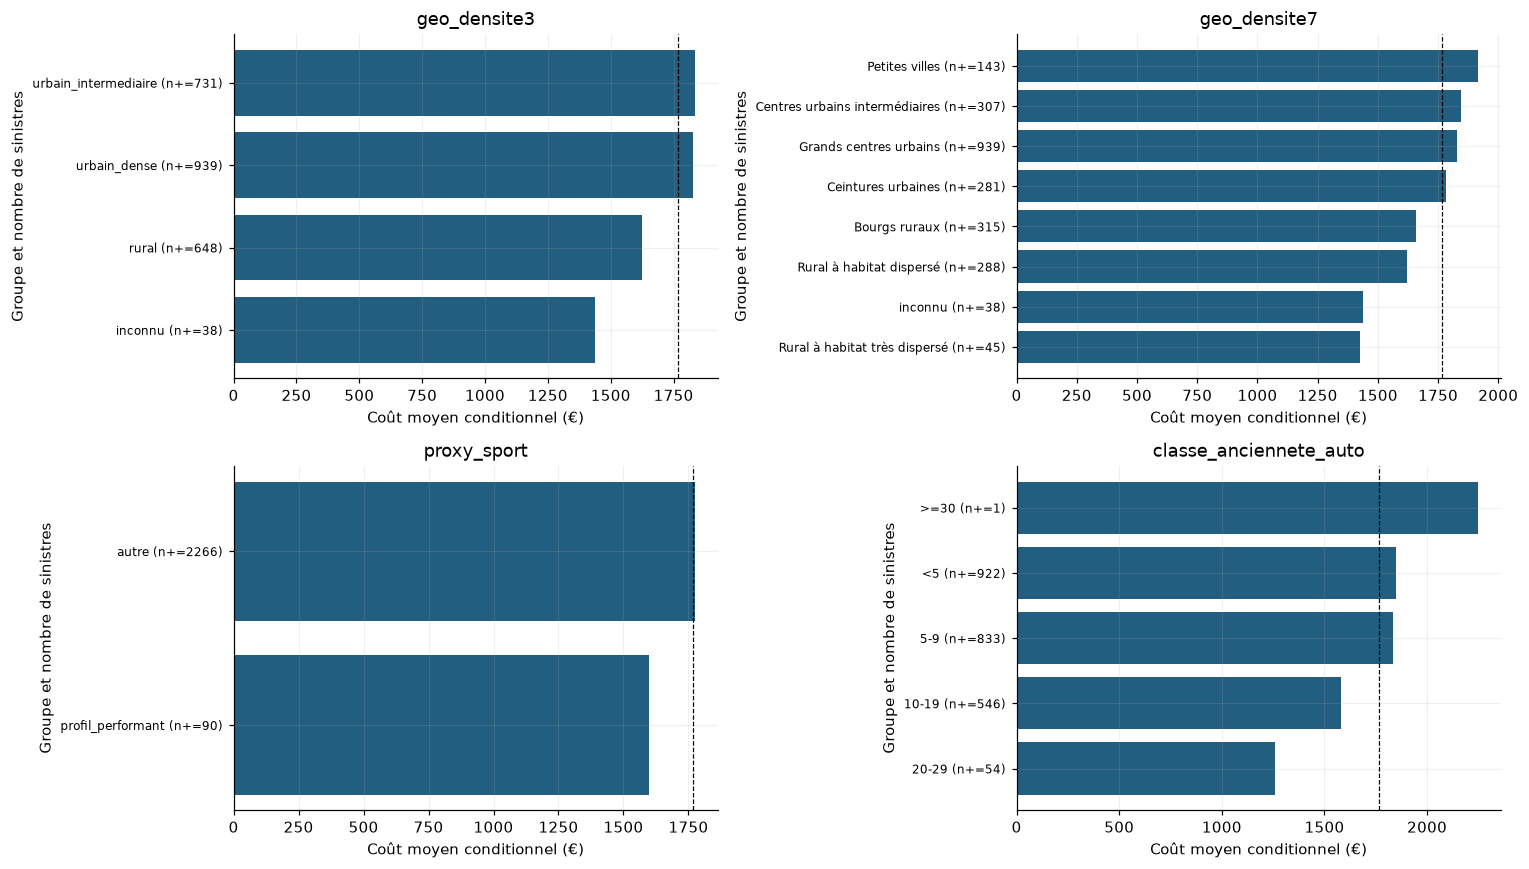

**Ancienneté élevée :** 1 sinistre(s) seulement pour les véhicules ≥30 dans le développement. Cela ne permet pas de valider un surcoût de « collection ». Le statut et la valeur assurée correspondante manquent.

"""Extension métier exploratoire : Insee, puissance et ancienneté.
Les règles n'utilisent aucun montant de sinistre. Le référentiel est embarqué au fit.
"""
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin, RegressorMixin
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBRegressor
from gravite_pipeline import SeverityFeatures

ROOT = Path(__file__).resolve().parent

def commune_codes(s):
    """Codes communaux présumés; rattachement documenté des arrondissements PLM."""
    out = s.astype(str).str.upper().str.strip().str.zfill(5)
    mapping = {str(n):'75056' for n in range(75101,75121)}
    mapping.update({str(n):'69123' for n in range(69381,69390)})
    mapping.update({str(n):'13055' for n in range(13201,13217)})
    return out.replace(mapping)

class BusinessFeatures(TransformerMixin, BaseEstimator):
    def __init__(self, source='minimal', geo='none', vehicle='none', interactions=False,
                 reference_path=None):
        self.source = source
        self.geo = geo
        self.vehicle = vehicle
        self.interactions = interactions
        self.reference_path = reference_path

    def fit(self, X, y=None):
        self.n_features_in_ = X.shape[1]
        path = Path(self.reference_path) if self.reference_path else ROOT/'assets/referentiel_communes_insee_2021.csv'
        self.reference_ = pd.read_csv(path,dtype={'code_commune':str}).set_index('code_commune')
        return self

    def transform(self, X):
        full = SeverityFeatures(profile='raw',clean=True,geography='none').fit_transform(X)
        if self.source == 'minimal':
            z = full[['type_contrat','prix_vehicule','anciennete_vehicule']].copy()
        else:
            z = full.copy()
        if self.geo != 'none':
            codes = commune_codes(X['code_postal'])
            ref = self.reference_
            d3 = codes.map(ref['densite3']).fillna('inconnu')
            d7 = codes.map(ref['libelle_densite7']).fillna('inconnu')
            pop = codes.map(ref['population_2018'])
            if self.geo in ('g3','all'):
                z['geo_densite3'] = d3
            if self.geo in ('g7','all'):
                z['geo_densite7'] = d7
            if self.geo in ('population','all'):
                z['geo_population_log'] = np.log1p(pop)
                z['geo_taille_commune'] = pd.cut(pop,[-np.inf,2000,10000,50000,200000,np.inf],
                  labels=['<2k','2-10k','10-50k','50-200k','>=200k'],right=False).astype(object).fillna('inconnu')
            if self.interactions:
                z['couverture_densite'] = full.type_contrat.astype(str)+'::'+d3.astype(str)
        if self.vehicle != 'none':
            ratio = 1000*full.din_vehicule/full.poids_vehicule.where(full.poids_vehicule.gt(0))
            power = full.din_vehicule
            speed = full.vitesse_vehicule
            age = full.anciennete_vehicule
            mode = self.vehicle
            if mode in ('sport','sport_loose','sport_strict','all'):
                thresholds = {'sport_loose':(120,90,210),'sport':(150,110,230),'sport_strict':(180,130,250)}
                p,r,v = thresholds.get(mode,(150,110,230))
                flag = (power.ge(p)&ratio.ge(r)) | (power.ge(p)&speed.ge(v))
                known = (power.notna()&ratio.notna()) | (power.notna()&speed.notna())
                z['proxy_sport'] = pd.Series(np.where(flag,'profil_performant','autre'),index=X.index).where(known,'inconnu')
                z['puissance_par_tonne_metier'] = ratio
            if mode in ('age','all'):
                z['classe_anciennete_auto'] = pd.cut(age,[-np.inf,5,10,20,30,np.inf],
                       labels=['<5','5-9','10-19','20-29','>=30'],right=False).astype(object).fillna('inconnu')
                z['vehicule_30plus'] = np.where(ag

In [20]:
business_view=BusinessFeatures(geo='all',vehicle='all',interactions=True).fit_transform(dev_portfolio[FEATURES])
analysis_columns=['geo_densite3','geo_densite7','geo_taille_commune','proxy_sport',
                  'classe_anciennete_auto','vehicule_30plus','segment_valeur_declaree']
segment_business=[]
for col in analysis_columns:
    frame=pd.DataFrame({'groupe':business_view[col].to_numpy(),
                        'sinistre':dev_portfolio.nombre_sinistres.gt(0).to_numpy(),
                        'cout':dev_portfolio[TARGET].where(dev_portfolio.nombre_sinistres.gt(0)).to_numpy()})
    t=frame.groupby('groupe',observed=True,dropna=False).agg(n_contrats=('sinistre','size'),n_sinistres=('cout','count'),
             taux_sinistre=('sinistre','mean'),gravite_moyenne=('cout','mean'),gravite_mediane=('cout','median'),
             ecart_type=('cout','std')).reset_index()
    t['variable']=col; t['erreur_standard']=t.ecart_type/np.sqrt(t.n_sinistres.clip(lower=1))
    t['effectif_faible']=t.n_sinistres.lt(30)
    segment_business.append(t)
segment_business=pd.concat(segment_business,ignore_index=True)
segment_business.to_csv(MR/'descriptif_groupes_metier.csv',index=False)
display(segment_business.drop(columns=['ecart_type']))
# Le ratio avec la moyenne est descriptif et ne sera pas imposé aux prédictions.
fig,axes=plt.subplots(2,2,figsize=(14,8))
for ax,col in zip(axes.flat,['geo_densite3','geo_densite7','proxy_sport','classe_anciennete_auto']):
    t=segment_business.loc[segment_business.variable.eq(col)].dropna(subset=['gravite_moyenne'])
    t=t.sort_values('gravite_moyenne')
    ax.barh(range(len(t)),t.gravite_moyenne)
    ax.set_yticks(range(len(t)),[str(g)+f' (n+={v})' for g,v in zip(t.groupe,t.n_sinistres)],fontsize=8)
    ax.axvline(y.mean(),color='black',linestyle='--',linewidth=.8)
    ax.set(xlabel='Coût moyen conditionnel (€)',ylabel='Groupe et nombre de sinistres',title=col)
savefig('09_groupes_metier_developpement')
old=segment_business.loc[segment_business.variable.eq('vehicule_30plus')&segment_business.groupe.eq('>=30')]
note('**Ancienneté élevée :** '+(f'{int(old.iloc[0].n_sinistres)} sinistre(s) seulement pour les véhicules ≥30 dans le développement. '
    if len(old) else 'Aucun groupe ≥30 observé. ')+
    'Cela ne permet pas de valider un surcoût de « collection ». Le statut et la valeur assurée correspondante manquent.')
display(Code((HERE/'metier_features.py').read_text(),language='python'))

### 8.3 Comparaisons sur les mêmes plis : hypothèses et ablations

Les hyperparamètres sont ceux du XGBoost minimal initial. **20 configurations annoncées** comparent la référence, chaque géographie, chaque proxy de véhicule, leur combinaison, les interactions et une source complète incluant marque/modèle. Les indicateurs géographiques proviennent d'un référentiel externe fixe, sans utilisation des cibles ; imputations et catégories restent apprises dans chaque sous-train.

Les regroupements sont ajoutés au modèle minimal pour mesurer leur apport direct. Les variantes complètes permettent de vérifier si marque, modèle et caractéristiques d'origine changent le résultat. On ne remplace pas la pipeline initiale à partir d'une simple meilleure moyenne de CV.

minimal_reference 1449.729


geo_3 1449.283


geo_7 1452.548


geo_population 1452.748


geo_complet 1455.952


sport_modere 1453.584


... (11 outputs left out)

toutes_variables_geo 1457.871


toutes_variables_auto 1460.733


toutes_variables_metier 1459.923


,name,rmse,mae,train_rmse,delta_rmse_vs_minimal
1,geo_3,"1,449.283",927.489,"1,416.805",-0.446
0,minimal_reference,"1,449.729",929.352,"1,421.135",0.000
8,anciennete_groupes,"1,449.749",928.550,"1,421.722",0.020
9,valeur_groupes,"1,451.183",929.649,"1,419.899",1.454
13,geo3_auto,"1,451.405",932.417,"1,405.004",1.676
11,geo3_sport,"1,451.451",931.434,"1,406.501",1.722
10,auto_complet,"1,452.154",931.814,"1,406.426",2.425
2,geo_7,"1,452.548",930.104,"1,416.903",2.819
3,geo_population,"1,452.748",929.528,"1,403.786",3.019
6,sport_central,"1,453.438",933.290,"1,405.579",3.709


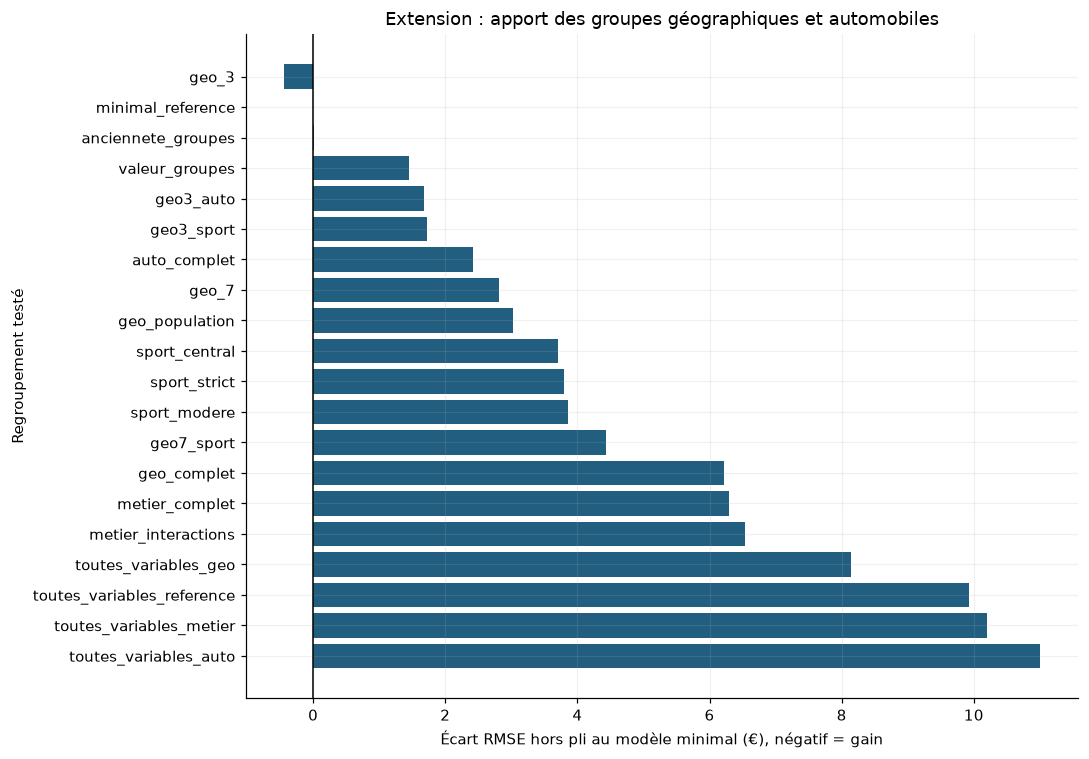

In [21]:
BUSINESS_PLAN=[
 ('minimal_reference',dict(source='minimal',geo='none',vehicle='none'),'Reproduire exactement les trois variables initiales.'),
 ('geo_3',dict(geo='g3'),'Urbain dense / intermédiaire / rural.'),
 ('geo_7',dict(geo='g7'),'Sept niveaux de densité communale.'),
 ('geo_population',dict(geo='population'),'Population log et taille de commune.'),
 ('geo_complet',dict(geo='all'),'Densité 3/7 et taille de commune.'),
 ('sport_modere',dict(vehicle='sport_loose'),'Seuils 120 / 90 / 210.'),
 ('sport_central',dict(vehicle='sport'),'Seuils 150 / 110 / 230.'),
 ('sport_strict',dict(vehicle='sport_strict'),'Seuils 180 / 130 / 250.'),
 ('anciennete_groupes',dict(vehicle='age'),'Âge regroupé et indicateur ≥30, sans statut collection.'),
 ('valeur_groupes',dict(vehicle='price'),'Regrouper le prix déclaré.'),
 ('auto_complet',dict(vehicle='all'),'Profils performants, âge et valeur déclarée.'),
 ('geo3_sport',dict(geo='g3',vehicle='sport'),'Densité 3 et profil performant central.'),
 ('geo7_sport',dict(geo='g7',vehicle='sport'),'Densité 7 et profil performant central.'),
 ('geo3_auto',dict(geo='g3',vehicle='all'),'Densité 3 et ensemble des profils auto.'),
 ('metier_complet',dict(geo='all',vehicle='all'),'Tous les regroupements métier.'),
 ('metier_interactions',dict(geo='all',vehicle='all',interactions=True),'Croiser les groupes avec la couverture.'),
 ('toutes_variables_reference',dict(source='complete'),'Toutes variables admissibles, sans code géographique.'),
 ('toutes_variables_geo',dict(source='complete',geo='all'),'Toutes variables, avec géographie métier.'),
 ('toutes_variables_auto',dict(source='complete',vehicle='all'),'Toutes variables, avec profils auto.'),
 ('toutes_variables_metier',dict(source='complete',geo='all',vehicle='all',interactions=True),'Marque/modèle, géographie et profils auto.'),
]
business_specs={name:spec for name,spec,reason in BUSINESS_PLAN}
business_reasons={name:reason for name,spec,reason in BUSINESS_PLAN}
business_rows=[]; business_fold_rows=[]; business_oof={}
for name,spec,reason in BUSINESS_PLAN:
    pp=np.empty(len(y)); train_errors=[]
    for k,(tr,va) in enumerate(FOLDS):
        with threadpool_limits(limits=2):
            m=BusinessSeverityEstimator(spec,CONFIG).fit(X.iloc[tr],y[tr])
        pp[va]=m.predict(X.iloc[va]); train_errors.append(rmse(y[tr],m.predict(X.iloc[tr])))
        business_fold_rows.append({'name':name,'fold':k,**scores(y[va],pp[va])})
    business_oof[name]=pp
    business_rows.append({'name':name,'hypothese':reason,'train_rmse':np.mean(train_errors),**scores(y,pp)})
    print(name,round(rmse(y,pp),3),flush=True)
business_ranking=pd.DataFrame(business_rows).sort_values('rmse')
business_ranking['delta_rmse_vs_minimal']=business_ranking.rmse-float(business_ranking.set_index('name').loc['minimal_reference','rmse'])
np.testing.assert_allclose(business_oof['minimal_reference'],SELECTED_OOF,rtol=0,atol=1e-6)
business_ranking.to_csv(MR/'comparaison_20_groupements.csv',index=False)
pd.DataFrame(business_fold_rows).to_csv(MR/'scores_par_pli.csv',index=False)
(MR/'plan_experiences.json').write_text(json.dumps([{'name':name,'business':spec,'raison':reason} for name,spec,reason in BUSINESS_PLAN],indent=2,ensure_ascii=False))
display(business_ranking[['name','rmse','mae','train_rmse','delta_rmse_vs_minimal']])
fig,ax=plt.subplots(figsize=(10,7))
t=business_ranking.iloc[::-1]
ax.barh(t.name,t.delta_rmse_vs_minimal); ax.axvline(0,color='black',linewidth=1)
ax.set(xlabel='Écart RMSE hors pli au modèle minimal (€), négatif = gain',ylabel='Regroupement testé',title='Extension : apport des groupes géographiques et automobiles')
savefig('10_comparaison_groupes_metier')

### 8.4 Validation imbriquée de la sélection des nouveaux blocs

Dans chaque pli externe du développement, on sélectionne parmi **le même plan de 20 configurations** avec trois plis internes séparés par client, puis on réentraîne le choix sur le sous-train externe et prédit son pli externe. La référence minimale est entraînée sur les mêmes contrats.

Cette boucle empêche le score du pli externe de choisir les **nouveaux regroupements**. Elle reste conditionnelle aux hyperparamètres préexistants, et les données ont déjà été explorées : on ne la présente pas comme une nouvelle cohorte indépendante. On conserve la référence dans la liste pour permettre de rejeter tous les nouveaux blocs. Le holdout initial n'est pas consulté.

In [22]:
nested_p=np.empty(len(y)); nested_ref=np.empty(len(y)); nested_selection=[]
for outer,(tr,va) in enumerate(FOLDS):
    inner=GroupKFold(n_splits=3,shuffle=True,random_state=SEED+outer)
    inner_folds=list(inner.split(X.iloc[tr],groups=groups[tr]))
    candidates=[]
    for name,spec,_ in BUSINESS_PLAN:
        ip=np.empty(len(tr))
        for it,iv in inner_folds:
            with threadpool_limits(limits=2):
                m=BusinessSeverityEstimator(spec,CONFIG).fit(X.iloc[tr[it]],y[tr[it]])
            ip[iv]=m.predict(X.iloc[tr[iv]])
        candidates.append((rmse(y[tr],ip),name))
    value,name=min(candidates)
    with threadpool_limits(limits=2):
        chosen=BusinessSeverityEstimator(business_specs[name],CONFIG).fit(X.iloc[tr],y[tr])
        ref=BusinessSeverityEstimator(business_specs['minimal_reference'],CONFIG).fit(X.iloc[tr],y[tr])
    nested_p[va]=chosen.predict(X.iloc[va]); nested_ref[va]=ref.predict(X.iloc[va])
    nested_selection.append({'outer_fold':outer,'selected':name,'inner_rmse':value,
                              'outer_rmse':rmse(y[va],nested_p[va]),'reference_rmse':rmse(y[va],nested_ref[va])})
    print('Pli externe',outer,'choix interne',name,'RMSE',round(rmse(y[va],nested_p[va]),2),flush=True)
nested_table=pd.DataFrame(nested_selection); display(nested_table)
nested_table.to_csv(MR/'selection_imbriquee_par_pli.csv',index=False)
comparison_nested=pd.DataFrame([{'procedure':'minimal_fixe',**scores(y,nested_ref)},
                                {'procedure':'selection_groupements_interne',**scores(y,nested_p)}])
display(comparison_nested)
comparison_nested.to_csv(MR/'validation_imbriquee.csv',index=False)
cluster_ids=np.unique(groups); idx_by_client=[np.flatnonzero(groups==g) for g in cluster_ids]
rng=np.random.default_rng(SEED+100)
gains=[]
for _ in range(1000):
    ii=np.concatenate([idx_by_client[j] for j in rng.integers(0,len(cluster_ids),len(cluster_ids))])
    gains.append(rmse(y[ii],nested_ref[ii])-rmse(y[ii],nested_p[ii]))
ci_metier=np.quantile(gains,[.025,.975])
nested_summary={'reference_rmse':rmse(y,nested_ref),'selection_rmse':rmse(y,nested_p),
                'gain_rmse':rmse(y,nested_ref)-rmse(y,nested_p),'ci95_low':float(ci_metier[0]),'ci95_high':float(ci_metier[1]),
                'bootstrap_unit':'client','bootstrap_replicates':1000,'conditional_on_initial_hyperparameters':True,
                'initial_holdout_reused':False}
(MR/'incertitude_selection_imbriquee.json').write_text(json.dumps(nested_summary,indent=2,ensure_ascii=False))
note(f'**Sélection des nouveaux blocs :** gain de RMSE imbriquée {nested_summary["gain_rmse"]:+,.2f} €, '
     f'intervalle descriptif 95 % [{ci_metier[0]:+,.2f} ; {ci_metier[1]:+,.2f}] €. '
     + ('Le gain est positif dans cet intervalle, sous les limites de validation précisées.' if ci_metier[0]>0 else
        'La recherche de regroupements ne démontre pas ici une amélioration stable du modèle minimal.'))

Pli externe 0 choix interne geo_population RMSE 1329.05


Pli externe 1 choix interne geo_complet RMSE 1591.23


Pli externe 2 choix interne anciennete_groupes RMSE 1429.49


,outer_fold,selected,inner_rmse,outer_rmse,reference_rmse
0,0,geo_population,"1,517.191","1,329.047","1,317.678"
1,1,geo_complet,"1,380.994","1,591.233","1,589.805"
2,2,anciennete_groupes,"1,465.818","1,429.485","1,428.581"


,procedure,rmse,mae,gamma_deviance,r2,ratio_predit_observe,moyenne_predite
0,minimal_fixe,"1,449.729",929.352,0.397,0.016,0.999,"1,766.294"
1,selection_groupements_interne,"1,454.000",930.903,0.400,0.010,1.001,"1,769.146"


**Sélection des nouveaux blocs :** gain de RMSE imbriquée -4.27 €, intervalle descriptif 95 % [-8.04 ; -0.56] €. La recherche de regroupements ne démontre pas ici une amélioration stable du modèle minimal.

### 8.5 Candidat exploratoire, décisions et limites métier

Le meilleur candidat de CV de développement est sauvegardé séparément, avec le tableau des effectifs et les résultats de la procédure imbriquée. La pipeline initiale et son fichier de gravité restent conservés. Une vraie amélioration devra être confirmée sur une nouvelle cohorte, avec la bonne géographie historique et, pour les véhicules de collection, la valeur assurée et le statut réellement souscrit.

Il faut distinguer **prix élevé d'un bien**, **gravité conditionnelle d'un sinistre**, **probabilité de sinistre** et **prime pure**. Les catégories métier peuvent agir différemment sur ces quantités. On ne transforme pas une intuition de prix en coefficient multiplicateur de gravité sans mesure.

In [23]:
BEST_BUSINESS=str(business_ranking.iloc[0]['name'])
with threadpool_limits(limits=2):
    candidate_metier=BusinessSeverityEstimator(business_specs[BEST_BUSINESS],CONFIG).fit(positive[FEATURES],positive[TARGET].to_numpy())
p_candidate=candidate_metier.predict(test[FEATURES])
assert np.isfinite(p_candidate).all() and (p_candidate>0).all()
joblib.dump(candidate_metier,MODELS/'gravite_metier_candidat.joblib')
pd.DataFrame({'index':test['index'].to_numpy(),'gravite_predite':p_candidate}).to_csv(MR/'gravite_test_candidat.csv',index=False)
reloaded_metier=joblib.load(MODELS/'gravite_metier_candidat.joblib')
np.testing.assert_allclose(reloaded_metier.predict(test[FEATURES].head(50)),p_candidate[:50],rtol=0,atol=1e-6)
probe=test[FEATURES].head(4).copy(); probe['code_postal']='99999'; probe['modele_vehicule']='NOUVEAU_MODELE'
probe['poids_vehicule']=0.; probe['anciennete_vehicule']=np.nan
assert np.isfinite(reloaded_metier.predict(probe)).all()
retained_metier=candidate_metier.pipeline_.named_steps['business'].transform(test[FEATURES].head()).columns.tolist()
metier_manifest={'best_development_candidate':BEST_BUSINESS,'business':business_specs[BEST_BUSINESS],
                 'retained_features':retained_metier,'base_hyperparameters':CONFIG,
                 'development_cv_scores':scores(y,business_oof[BEST_BUSINESS]),'nested_selection':nested_summary,
                 'external_reference':source_geo,'original_model_preserved':True,'status':'exploratory_not_fresh_holdout_validated',
                 'n_business_trials':len(BUSINESS_PLAN),'n_test_predictions':len(p_candidate),'reload_equal':True}
(MR/'manifest_metier.json').write_text(json.dumps(metier_manifest,indent=2,ensure_ascii=False))
geo_best=business_ranking[business_ranking.name.isin(['geo_3','geo_7','geo_population','geo_complet'])].iloc[0]
car_best=business_ranking[business_ranking.name.isin(['sport_modere','sport_central','sport_strict','anciennete_groupes','valeur_groupes','auto_complet'])].iloc[0]
note(f'**Géographie :** meilleur ajout isolé `{geo_best["name"]}`, écart de RMSE {geo_best.delta_rmse_vs_minimal:+,.2f} € au modèle minimal. '
     f'**Automobile :** meilleur ajout isolé `{car_best["name"]}`, écart {car_best.delta_rmse_vs_minimal:+,.2f} €. '
     f'**Meilleur candidat de développement :** `{BEST_BUSINESS}`, RMSE {business_ranking.iloc[0].rmse:,.2f} €. '
     f'La sélection imbriquée donne un gain {nested_summary["gain_rmse"]:+,.2f} €. '
     'Ces nombres permettent de distinguer les idées testées des effets confirmés. Aucun surcoût automatique « sport » ou « collection » n’est imposé.')
print('Variables du candidat exploratoire :',retained_metier)
print('Pipeline initiale conservée ; candidat et prédictions séparés dans reports/metier et models.')

**Géographie :** meilleur ajout isolé `geo_3`, écart de RMSE -0.45 € au modèle minimal. **Automobile :** meilleur ajout isolé `anciennete_groupes`, écart +0.02 €. **Meilleur candidat de développement :** `geo_3`, RMSE 1,449.28 €. La sélection imbriquée donne un gain -4.27 €. Ces nombres permettent de distinguer les idées testées des effets confirmés. Aucun surcoût automatique « sport » ou « collection » n’est imposé.

Variables du candidat exploratoire : ['type_contrat', 'prix_vehicule', 'anciennete_vehicule', 'geo_densite3']
Pipeline initiale conservée ; candidat et prédictions séparés dans reports/metier et models.


## 9. Variables élargies : nouvelles idées et blocs précédemment écartés

**Lecture actuelle du projet :** cette section réintroduit les variables du tableau proposé et les blocs qui n'avaient pas été retenus. Elle compare les objectifs XGBoost **quadratique et Gamma avec le même budget**, ainsi qu'un modèle complet et des versions simplifiées. Les fichiers de cette recherche sont dans `reports/variables_elargies/` ; ils sont distincts des recherches initiales.

Le tableau fourni contient des écarts dont la métrique n'est pas précisée : ils motivent des hypothèses, sans servir à déclarer une variable indispensable pour la gravité. Ici, la sélection porte sur la **RMSE des coûts positifs en euros**, avec MAE, déviance Gamma, calibration et dispersion entre plis en diagnostics.

Le holdout initial a déjà été examiné : il ne sert ni à choisir ni à évaluer cette recherche. On utilise le développement initial avec une **validation imbriquée de toute la nouvelle procédure** : choix des variables, de l'objectif, du réglage et des retraits. Les données restent historiquement explorées ; les intervalles ne sont pas une validation externe neuve.

### 9.1 Analyse et définition des variables avant la recherche

Les variables brutes de gestion, conducteurs, bonus, marque/modèle, motorisation, poids, puissance, cylindrée, vitesse et anciennetés de vente sont remises en concurrence. Les dates de vente ne sont pas supprimées sur une simple supposition de redondance.

Créations retenues pour les essais :

- `vehicule_recent` : âge ≤2, inconnu si âge manquant.
- `prix_relatif` : prix / médiane du prix au même âge, avec ramené vers la médiane globale quand cet âge est rare. Les prix de **tous les contrats du sous-train courant** sont utilisés, pas ceux de validation ou de test. Aucun montant de sinistre n'intervient.
- `puissance_poids`, puissance/cylindrée et prix/poids : dénominateurs non positifs mis à NaN.
- `jeune_conducteur1/2` : moins de 25 ans pour les deux, avec présence du second conducteur requise ; `novice1/2` : permis depuis moins de 3 ans. Une absence secondaire donne 0 pour les indicateurs, un âge/permis inconnu chez un conducteur présent reste NaN.
- `age_permis1/2` : âge − ancienneté de permis après nettoyage des valeurs suspectes ; écart d'âge entre conducteurs.
- `bonus_minimal` : coefficient =0,5 ; `coefficient_superieur_1` : coefficient >1. On n'ajoute pas en même temps l'exact complément de `bonus_minimal`. Le coefficient minimal ne signifie pas « aucun sinistre récent ».
- jeune×puissance et les trois produits du tableau : les centrages/échelles des produits continus sont appris dans le sous-train. Il n'y a pas de standardisation globale inutile aux arbres.
- Classes géographiques Insee 3/7, population, familles de modèles, groupes d'ancienneté/prix et profil performant, plus les six clusters techniques précédemment non retenus.

**Encodages supervisés :** moyennes de gravité lissées modèle→marque et commune→département→global, apprises sur les sinistrés. Une autre branche utilise les taux de sinistres du portefeuille de sous-train comme information auxiliaire ; elle ne confond pas taux et coût conditionnel. Chaque ligne d'apprentissage est encodée avec les autres clients dans trois plis internes, à l'intérieur de chaque apprentissage de validation principal. Les clients de validation sont exclus de tous les contrats du portefeuille auxiliaire.

Référence : [cross-fitting des encodages supervisés](https://scikit-learn.org/stable/auto_examples/preprocessing/plot_target_encoder_cross_val.html). Le lissage est fixé à 50 ; le prix par âge est stabilisé avec un poids `n/(n+30)`. Ce sont des choix bornés de régularisation, pas une preuve d'optimalité.

In [3]:
from enriched_features import EnrichedFeatures, EnrichedSeverityEstimator, BLOCKS, grouped_encodings
import copy
ER=REPORTS/'variables_elargies'; ER.mkdir(exist_ok=True)
INITIAL=json.loads((REPORTS/'selection_gelee_avant_holdout.json').read_text())
REFERENCE_PARAMS=INITIAL['config']
for fn,digest in json.loads((REPORTS/'manifest.json').read_text())['data_sha256'].items():
    assert hashlib.sha256((DATA/fn).read_bytes()).hexdigest()==digest, 'Données modifiées : revoir le découpage et les comparaisons.'
preview_builder=EnrichedFeatures(source='complete',blocks=BLOCKS,encoding='both').fit(X,price_reference=dev_portfolio)
preview_expanded=preview_builder.transform(X)
preview_enc,_,encoding_audit=grouped_encodings(X,y,groups,'both',dev_portfolio)
preview_expanded=pd.concat([preview_expanded,preview_enc],axis=1)
assert not set(preview_expanded)&FORBIDDEN
feature_audit=pd.DataFrame({'variable':preview_expanded.columns,'type':[str(preview_expanded[k].dtype) for k in preview_expanded],
    'manquants':[preview_expanded[k].isna().sum() for k in preview_expanded],
    'modalites':[preview_expanded[k].nunique() for k in preview_expanded]})
feature_audit.to_csv(ER/'audit_62_variables.csv',index=False)
display(feature_audit)
print('Version complète :',preview_expanded.shape[1],'variables avant encodage one-hot.')
print('Référence prix :',preview_builder.price_reference_rows_,'contrats du développement seulement.')
for col in ['vehicule_recent','jeune_conducteur1','novice1','jeune_conducteur2','novice2','bonus_minimal']:
    frame=pd.DataFrame({'groupe':preview_expanded[col].fillna(-1),'montant':y})
    display(frame.groupby('groupe').montant.agg(['count','mean','median']).rename_axis(col))
relative=pd.DataFrame({'prix_relatif':preview_expanded.prix_relatif,'montant':y})
relative['tranche']=pd.qcut(relative.prix_relatif,5,duplicates='drop')
display(relative.groupby('tranche',observed=True).agg(n=('montant','size'),prix_relatif_median=('prix_relatif','median'),gravite=('montant','mean')))
price_table=preview_builder.age_prices_.to_frame('mediane_stabilisee_prix')
price_table.to_csv(ER/'prix_reference_par_age_developpement.csv')
display(Code((HERE/'enriched_features.py').read_text(),language='python'))

,variable,type,manquants,modalites
0,bonus,float64,0,41
1,type_contrat,object,0,4
2,duree_contrat,int64,0,33
3,anciennete_info,int64,0,15
4,freq_paiement,object,0,4
...,...,...,...,...
57,gravite_commune,float64,0,843
58,frequence_marque,float64,0,108
59,frequence_departement,float64,0,272
60,frequence_modele,float64,0,593


Version complète : 62 variables avant encodage one-hot.
Référence prix : 39964 contrats du développement seulement.


,count,mean,median
vehicule_recent,,,
0.000,1892,"1,732.186","1,236.000"
1.000,464,"1,910.506","1,291.800"


,count,mean,median
jeune_conducteur1,,,
0.000,2322,"1,772.599","1,236.000"
1.000,34,"1,405.736","1,231.050"


,count,mean,median
novice1,,,
0.000,2346,"1,768.499","1,236.000"
1.000,10,"1,487.282","1,080.635"


,count,mean,median
jeune_conducteur2,,,
0.000,2238,"1,758.095","1,236.000"
1.000,118,"1,941.980","1,302.840"


,count,mean,median
novice2,,,
-1.000,34,"2,438.819","1,604.920"
0.000,2270,"1,760.095","1,236.000"
1.000,52,"1,642.987","1,253.010"


,count,mean,median
bonus_minimal,,,
0.000,581,"1,809.157","1,236.000"
1.000,1775,"1,753.606","1,236.000"


,n,prix_relatif_median,gravite
tranche,,,
"(0.158, 0.751]",472,0.650,"1,737.423"
"(0.751, 0.97]",471,0.864,"1,788.814"
"(0.97, 1.215]",471,1.090,"1,919.584"
"(1.215, 1.518]",471,1.346,"1,674.531"
"(1.518, 5.006]",471,1.842,"1,716.238"


"""Recherche élargie de gravité : variables du tableau et anciens blocs réintroduits.
Tous les apprentissages, y compris les encodages hiérarchiques, restent dans fit.
"""
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin, RegressorMixin
from sklearn.model_selection import GroupKFold
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor
from gravite_pipeline import SeverityFeatures, FORBIDDEN
from metier_features import BusinessFeatures, commune_codes

BLOCKS = ('recent','relative_price','technical','drivers','bonus','interactions',
          'geography','vehicle_groups','clusters','sales')
CORE = ['type_contrat','prix_vehicule','anciennete_vehicule']
ROOT = Path(__file__).resolve().parent


def category_keys(X):
    brand = X.marque_vehicule.fillna('__INCONNU__').astype(str).str.upper().str.strip()
    model = brand+'::'+X.modele_vehicule.fillna('__INCONNU__').astype(str).str.upper().str.strip()
    commune = commune_codes(X.code_postal)
    dept = commune.str[:2].where(~commune.str.startswith(('97','98')),commune.str[:3])
    return pd.DataFrame({'marque':brand,'modele':model,'departement':dept,'commune':commune},index=X.index)


class HierarchicalMeanEncoder(BaseEstimator):
    """Moyennes lissées modèle→marque et commune→département, sans données externes."""
    def __init__(self, smoothing=50.0):
        self.smoothing = smoothing

    def fit(self,X,y):
        keys=category_keys(X).reset_index(drop=True)
        y=np.asarray(y,dtype=float)
        if not np.isfinite(y).all():
            raise ValueError('Cible non finie dans un encodage.')
        self.global_mean_=float(y.mean())
        self.maps_={}
        for col,parent in [('marque',None),('departement',None),('modele','marque'),('commune','departement')]:
            f=keys.copy(); f['y']=y
            t=f.groupby(col,observed=True).y.agg(['sum','count'])
            if parent:
                parents=f.groupby(col,observed=True)[parent].first()
                prior=parents.map(self.maps_[parent]).fillna(self.global_mean_)
            else:
                prior=pd.Series(self.global_mean_,index=t.index)
            self.maps_[col]=(t['sum']+self.smoothing*prior)/(t['count']+self.smoothing)
        return self

    def transform(self,X,prefix='gravite'):
        keys=category_keys(X)
        out=pd.DataFrame(index=X.index)
        for col,parent in [('marque',None),('departement',None),('modele','marque'),('commune','departement')]:
            prior=out[prefix+'_'+parent] if parent else self.global_mean_
            out[prefix+'_'+col]=keys[col].map(self.maps_[col]).fillna(prior)
        return out


def grouped_encodings(X,y,groups,mode,portfolio=None,smoothing=50.0):
    """Encodages d'apprentissage hors client + dictionnaires pour les futurs clients.
    Le portefeuille auxiliaire doit appartenir au seul sous-train externe courant.
    """
    groups=np.asarray(groups)
    modes=['gravite','frequence'] if mode=='both' else [mode]
    output=pd.DataFrame(index=X.index)
    encoders={}; audit=[]
    for label in modes:
        out=pd.DataFrame(index=X.index,columns=[label+'_'+c for c in ['marque','departement','modele','commune']],dtype=float)
        splitter=GroupKFold(n_splits=3,shuffle=True,random_state=412)
        for tr,va in splitter.split(X,groups=groups):
            excluded=set(groups[va])
            assert not excluded.intersection(groups[tr])
            if label=='frequence':
                if portfolio is None:
                    raise ValueError('Le taux de sinistres nécessite le portefeuille du sous-train courant.')
                fit_portfolio=portfolio.loc[~portfolio.id_client.isin(excluded)]
                fit_X=fit_portfolio
                fit_y=fit_portfolio.nombre_sinistres.gt(0).to_numpy

### 9.2 Plan de comparaison annoncé : 16 ensembles × 2 objectifs × 2 réglages

Les 16 ensembles couvrent : référence trois variables ; récent/prix relatif ; ratios ; conducteurs/bonus ; interactions ; anciennetés de vente ; créations ensemble ; toutes variables brutes ; toutes créations en one-hot ; encodages de gravité, fréquence auxiliaire ou les deux ; variante logarithmique ; versions compactes avec encodages supervisés.

Deux réglages sont mis en concurrence pour **chaque ensemble et chaque objectif** : le XGBoost initial de profondeur 3 et un modèle de profondeur 1, davantage régularisé, qui permet aux nouveaux signaux de s'exprimer avec moins d'interactions et de variance. Cela fait 64 candidats de départ. Aucun réglage n'est choisi sur le holdout. Les objectifs partagent le budget de recherche ; l'intérêt théorique de Gamma ne le rend pas automatiquement meilleur en RMSE.

Les catégories rares sont regroupées dans chaque sous-train (seuil 10), les NaN numériques sont imputés avec indicateurs. Les arbres n'ont pas besoin de standardisation générale ; une variante log transforme les entrées techniques et garde les scores en euros. La cible n'est pas plafonnée dans cette recherche.

In [4]:
FEATURE_PLAN=[
 ('reference_3',dict(source='minimal',blocks=(),encoding='onehot')),
 ('recent_prix_relatif',dict(source='minimal',blocks=('recent','relative_price'),encoding='onehot')),
 ('ratios_techniques',dict(source='minimal',blocks=('technical',),encoding='onehot')),
 ('conducteurs_bonus',dict(source='minimal',blocks=('drivers','bonus'),encoding='onehot')),
 ('interactions',dict(source='minimal',blocks=('interactions',),encoding='onehot')),
 ('anciennetes_vente',dict(source='minimal',blocks=('sales',),encoding='onehot')),
 ('creations_ensemble',dict(source='minimal',blocks=BLOCKS,encoding='onehot')),
 ('toutes_brutes',dict(source='complete',blocks=(),encoding='onehot')),
 ('complet_onehot',dict(source='complete',blocks=BLOCKS,encoding='onehot')),
 ('complet_gravite',dict(source='complete',blocks=BLOCKS,encoding='gravite')),
 ('complet_frequence',dict(source='complete',blocks=BLOCKS,encoding='frequence')),
 ('complet_double',dict(source='complete',blocks=BLOCKS,encoding='both')),
 ('complet_double_log',dict(source='complete',blocks=BLOCKS,encoding='both',log_inputs=True)),
 ('compact_gravite',dict(source='minimal',blocks=('recent','relative_price'),encoding='gravite')),
 ('compact_frequence',dict(source='minimal',blocks=('recent','relative_price'),encoding='frequence')),
 ('compact_double',dict(source='minimal',blocks=('recent','relative_price'),encoding='both')),
]
HYPERS={
 'profondeur3':{k:REFERENCE_PARAMS[k] for k in ['n_estimators','max_depth','learning_rate','min_child_weight','reg_lambda','reg_alpha','subsample','colsample_bytree']},
 'regulier_profondeur1':dict(n_estimators=400,max_depth=1,learning_rate=.03,min_child_weight=40,reg_lambda=20,reg_alpha=0,subsample=.9,colsample_bytree=1.),
}
ENRICHED_PLAN=[]
for family,spec in FEATURE_PLAN:
    for loss in ['reg:squarederror','reg:gamma']:
        for h,params in HYPERS.items():
            ENRICHED_PLAN.append({'name':family+'__'+loss.split(':')[1]+'__'+h,'family':family,
                                 'spec':copy.deepcopy(spec),'objective':loss,'params':params})
assert len(ENRICHED_PLAN)==64
(ER/'plan_64_candidats.json').write_text(json.dumps(ENRICHED_PLAN,indent=2,ensure_ascii=False))
# Ablations de sources : retirer aussi les créations et encodages de ces sources.
REMOVE_GROUPS={
 'identite_auto':['marque_vehicule','modele_vehicule','famille_modele','gravite_marque','gravite_modele','frequence_marque','frequence_modele'],
 'geographie':['departement','geo_densite3','geo_densite7','geo_population_log','geo_taille_commune','gravite_departement','gravite_commune','frequence_departement','frequence_commune'],
 'gestion':['duree_contrat','anciennete_info','freq_paiement','paiement'],
 'bonus':['bonus','bonus_minimal','coefficient_superieur_1'],
 'conducteurs':['conducteur2','age_conducteur1','age_conducteur2','anciennete_permis1','anciennete_permis2',
                 'anciennete_permis1_invalide','anciennete_permis2_invalide','jeune_conducteur1','jeune_conducteur2',
                 'novice1','novice2','age_permis1','age_permis2','ecart_age_conducteurs','jeune_x_puissance',
                 'age1_x_puissance','age1_x_age_vehicule'],
 'couverture':['type_contrat'],
 'usage':['utilisation'],
 'physique_auto':['prix_vehicule','anciennete_vehicule','din_vehicule','poids_vehicule','cylindre_vehicule','vitesse_vehicule',
                  'essence_vehicule','type_vehicule','debut_vente_vehicule','fin_vente_vehicule','poids_vehicule_invalide',
                  'cylindre_vehicule_invalide','vehicule_recent','prix_relatif','puissance_poids','puissance_litre','prix_par_kg',
                  'jeune_x_puissance','age1_x_puissance','age_vehicule_x_puissance','age1_x_age_vehicule',
                  'proxy_sport','classe_anciennete_auto','vehicule_30plus','segment_valeur_declaree','groupe_auto_cluster'],
}
ALL_SEARCH_ROWS=[]; ALL_FOLD_ROWS=[]; ALL_CONFIGS={}; RUN_RESULTS={}
GLOBAL_EVALUATIONS=0

def evaluate_enriched(cfg,Xpart,ypart,gpart,contexts,splits,run_id,stage):
    global GLOBAL_EVALUATIONS
    pp=np.empty(len(ypart)); train_errors=[]; names=None; raw_negative=0; encoding_checks=0
    fold_metrics=[]
    started=time.time()
    for k,(tr,va) in enumerate(splits):
        context=contexts[k]
        assert not set(context.id_client)&set(gpart[va])
        with threadpool_limits(limits=2):
            m=EnrichedSeverityEstimator(cfg['spec'],cfg['params'],cfg['objective']).fit(
                Xpart.iloc[tr],ypart[tr],gpart[tr],context)
        pv=m.predict(Xpart.iloc[va]); pp[va]=pv
        raw_negative+=int((m.predict_raw(Xpart.iloc[va])<0).sum())
        train_errors.append(rmse(ypart[tr],m.training_predictions_))
        assert all(a['client_overlap']==0 for a in m.encoding_audit_)
        encoding_checks+=len(m.encoding_audit_)
        names=m.feature_columns_
        fold_metrics.append({'run':run_id,'name':cfg['name'],'stage':stage,'fold':k,
                             'n':len(va),'train_rmse':train_errors[-1],**scores(ypart[va],pv)})
    GLOBAL_EVALUATIONS+=1
    row={'run':run_id,'name':cfg['name'],'family':cfg['family'],'stage':stage,'objective':cfg['objective'],
         'variables':len(names),'train_rmse':float(np.mean(train_errors)),
         'fold_rmse_std':float(np.std([v['rmse'] for v in fold_metrics],ddof=1)),
         'raw_negative_predictions':raw_negative,'encoding_split_checks':encoding_checks,
         'seconds':time.time()-started,**scores(ypart,pp)}
    ALL_SEARCH_ROWS.append(row); ALL_FOLD_ROWS.extend(fold_metrics)
    ALL_CONFIGS[run_id+'::'+cfg['name']]=copy.deepcopy(cfg)
    pd.DataFrame(ALL_SEARCH_ROWS).to_csv(ER/'journal_tous_essais.csv',index=False)
    (ER/'progression.json').write_text(json.dumps({'run':run_id,'last_candidate':cfg['name'],
        'evaluations_finished':GLOBAL_EVALUATIONS,'last_rmse':row['rmse']},indent=2))
    return {'row':row,'config':copy.deepcopy(cfg),'oof':pp,'features':names}


def search_enriched(Xpart,ypart,gpart,portfolio_part,run_id,splits=None):
    if splits is None:
        splits=list(GroupKFold(n_splits=3,shuffle=True,random_state=173).split(Xpart,groups=gpart))
    contexts=[portfolio_part.loc[~portfolio_part.id_client.isin(set(gpart[va]))] for tr,va in splits]
    results=[]
    for cfg in ENRICHED_PLAN:
        results.append(evaluate_enriched(cfg,Xpart,ypart,gpart,contexts,splits,run_id,'plan_64'))
    # Même règle d'ablation pour les meilleurs représentants des deux objectifs.
    best_parents=[min([r for r in results if r['config']['objective']==obj],key=lambda r:r['row']['rmse'])
                  for obj in ['reg:squarederror','reg:gamma']]
    for parent in best_parents:
        parent_cfg=parent['config']; used=set(parent['features']); variants=[]
        for group,columns in REMOVE_GROUPS.items():
            if not used.intersection(columns):
                continue
            cfg=copy.deepcopy(parent_cfg)
            cfg['name']=parent_cfg['name']+'__sans_'+group
            cfg['spec']['exclude']=sorted(set(cfg['spec'].get('exclude',()))|set(columns))
            variants.append(cfg)
        for block in ['relative_price','technical','drivers','interactions','clusters']:
            if block in parent_cfg['spec'].get('blocks',()):
                cfg=copy.deepcopy(parent_cfg)
                cfg['name']=parent_cfg['name']+'__sans_creation_'+block
                cfg['spec']['blocks']=[b for b in cfg['spec']['blocks'] if b!=block]
                variants.append(cfg)
        favorable=[]
        for cfg in variants:
            r=evaluate_enriched(cfg,Xpart,ypart,gpart,contexts,splits,run_id,'ablation')
            results.append(r)
            if r['row']['rmse']<parent['row']['rmse']:
                favorable.append(cfg)
        if len(favorable)>1:
            cfg=copy.deepcopy(parent_cfg)
            cfg['name']=parent_cfg['name']+'__retraits_combines'
            excluded=set(cfg['spec'].get('exclude',()))
            allowed_blocks=set(cfg['spec'].get('blocks',()))
            for v in favorable:
                excluded.update(v['spec'].get('exclude',()))
                allowed_blocks.intersection_update(v['spec'].get('blocks',()))
            cfg['spec']['exclude']=sorted(excluded)
            cfg['spec']['blocks']=[b for b in parent_cfg['spec'].get('blocks',()) if b in allowed_blocks]
            creation_columns={
              'relative_price':{'prix_relatif'},
              'technical':{'puissance_poids','puissance_litre','prix_par_kg'},
              'drivers':{'jeune_conducteur1','jeune_conducteur2','novice1','novice2','age_permis1','age_permis2','ecart_age_conducteurs'},
              'interactions':{'jeune_x_puissance','age1_x_puissance','age_vehicule_x_puissance','age1_x_age_vehicule'},
              'clusters':{'groupe_auto_cluster'},
            }
            remaining=used-excluded
            for block in set(parent_cfg['spec'].get('blocks',()))-allowed_blocks:
                remaining.difference_update(creation_columns.get(block,set()))
            if remaining:
                results.append(evaluate_enriched(cfg,Xpart,ypart,gpart,contexts,splits,run_id,'ablation_combinee'))
    best=min(results,key=lambda r:r['row']['rmse'])
    RUN_RESULTS[run_id]=results
    pd.DataFrame(ALL_FOLD_ROWS).to_csv(ER/'scores_par_pli.csv',index=False)
    (ER/'configurations.json').write_text(json.dumps(ALL_CONFIGS,indent=2,ensure_ascii=False))
    return best,results

### 9.3 Comparaison de développement et sélection a posteriori

Les 64 candidats sont évalués sur les mêmes trois plis que les recherches précédentes. Pour le meilleur représentant de **chaque objectif**, on retire successivement des groupes de sources et certaines créations ; les retraits favorables sont combinés puis réévalués. Le retrait d'une source enlève également les interactions et encodages qui en dépendent. Les modèles de train sont évalués avec les encodages hors client utilisés à l'apprentissage, pas avec des moyennes réinjectant leur propre cible.

Cette sélection de développement fournit une recette candidate. Son score minimum est optimiste après de nombreux essais ; la section suivante évalue la procédure de sélection dans des plis externes.

,name,objective,variables,rmse,mae,train_rmse,fold_rmse_std
0,reference_3__squarederror__profondeur3,reg:squarederror,3,"1,449.729",929.352,"1,421.135",136.836
66,reference_3__gamma__profondeur3__sans_couverture,reg:gamma,2,"1,449.881",929.664,"1,435.169",135.401
2,reference_3__gamma__profondeur3,reg:gamma,3,"1,449.993",923.389,"1,429.434",137.201
3,reference_3__gamma__regulier_profondeur1,reg:gamma,3,"1,450.229",925.893,"1,437.233",136.941
1,reference_3__squarederror__regulier_profondeur1,reg:squarederror,3,"1,450.394",929.358,"1,437.580",137.223
64,reference_3__squarederror__profondeur3__sans_c...,reg:squarederror,2,"1,451.006",934.268,"1,429.169",136.235
5,recent_prix_relatif__squarederror__regulier_pr...,reg:squarederror,5,"1,451.510",929.308,"1,436.390",135.760
20,anciennetes_vente__squarederror__profondeur3,reg:squarederror,5,"1,451.667",929.446,"1,418.710",135.616
7,recent_prix_relatif__gamma__regulier_profondeur1,reg:gamma,5,"1,451.680",925.688,"1,436.220",134.935
22,anciennetes_vente__gamma__profondeur3,reg:gamma,5,"1,452.046",924.901,"1,426.581",135.399


,objective,variables,rmse,mae
family,,,,
reference_3,reg:squarederror,3,"1,449.729",929.352
recent_prix_relatif,reg:squarederror,5,"1,451.510",929.308
anciennetes_vente,reg:squarederror,5,"1,451.667",929.446
compact_gravite,reg:squarederror,9,"1,452.474",922.475
interactions,reg:gamma,7,"1,453.335",927.798
compact_frequence,reg:gamma,9,"1,453.513",939.495
compact_double,reg:gamma,13,"1,454.166",922.345
creations_ensemble,reg:gamma,34,"1,454.400",916.617
ratios_techniques,reg:gamma,6,"1,455.000",928.533


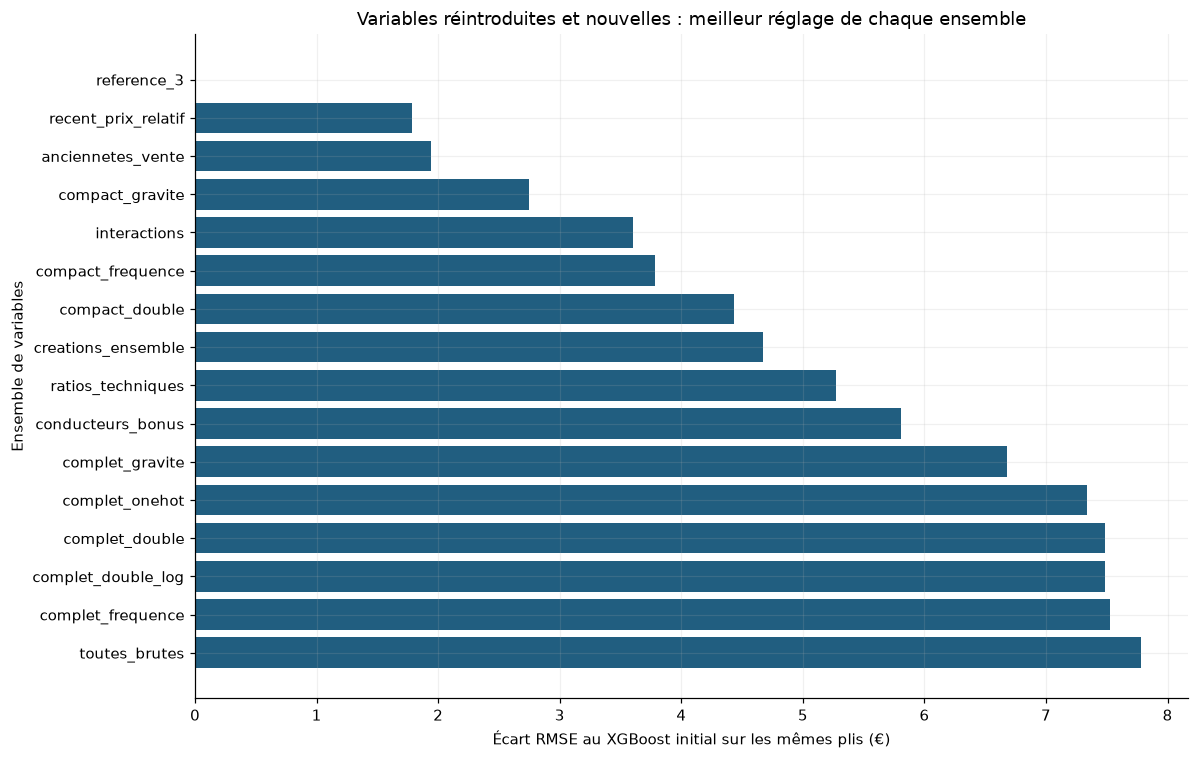

**Choix de développement :** `reference_3__squarederror__profondeur3`, objectif `reg:squarederror`, 3 variables avant one-hot, RMSE 1,449.73 €. Le XGBoost initial reproduit sa RMSE de 1,449.73 €. Le choix n’est pas fondé sur les anciens deltas de fréquence ni sur un surcoût imposé aux catégories.

In [5]:
BEST_ENRICHED,DEV_ENRICHED_RESULTS=search_enriched(X,y,groups,dev_portfolio,'developpement',FOLDS)
enriched_ranking=pd.DataFrame([r['row'] for r in DEV_ENRICHED_RESULTS]).sort_values('rmse')
enriched_ranking.to_csv(ER/'classement_developpement.csv',index=False)
display(enriched_ranking[['name','objective','variables','rmse','mae','train_rmse','fold_rmse_std']].head(20))
reference_result=next(r for r in DEV_ENRICHED_RESULTS if r['config']['name']=='reference_3__squarederror__profondeur3')
np.testing.assert_allclose(reference_result['row']['rmse'],INITIAL['oof_scores']['rmse'],rtol=0,atol=1e-6)
ENRICHED_CONFIG=BEST_ENRICHED['config']
(ER/'selection_developpement.json').write_text(json.dumps({'configuration':ENRICHED_CONFIG,
   'scores':BEST_ENRICHED['row'],'features':BEST_ENRICHED['features'],'holdout_used':False},indent=2,ensure_ascii=False))
by_family=enriched_ranking.groupby('family',sort=False).first().sort_values('rmse')
display(by_family[['objective','variables','rmse','mae']])
fig,ax=plt.subplots(figsize=(11,7))
t=by_family.iloc[::-1]
ax.barh(t.index,t.rmse-reference_result['row']['rmse']); ax.axvline(0,color='black',linewidth=1)
ax.set(xlabel='Écart RMSE au XGBoost initial sur les mêmes plis (€)',ylabel='Ensemble de variables',
       title='Variables réintroduites et nouvelles : meilleur réglage de chaque ensemble')
savefig('11_variables_elargies')
note(f'**Choix de développement :** `{ENRICHED_CONFIG["name"]}`, objectif `{ENRICHED_CONFIG["objective"]}`, '
     f'{len(BEST_ENRICHED["features"])} variables avant one-hot, RMSE {BEST_ENRICHED["row"]["rmse"]:,.2f} €. '
     f'Le XGBoost initial reproduit sa RMSE de {reference_result["row"]["rmse"]:,.2f} €. '
     'Le choix n’est pas fondé sur les anciens deltas de fréquence ni sur un surcoût imposé aux catégories.')

### 9.4 Validation imbriquée : variables, objectif, régularisation et ablations

Dans chacun des trois plis externes, **toute la procédure de la section 9.2–9.3** est rejouée dans le sous-train : les 64 candidats, puis les ablations des meilleurs représentants de chaque objectif, et leur combinaison éventuelle. Les encodages de ces candidats possèdent encore leur propre cross-fitting interne. Le pli externe n'intervient jamais dans ces décisions, ni dans les médianes de prix ou les taux de fréquence auxiliaires.

La référence initiale est entraînée sur les mêmes sous-trains. Les hyperparamètres de cette référence et le plan ont été élaborés sur des données historiquement explorées ; cette validation mesure la nouvelle procédure sous ce plan, sans constituer une nouvelle cohorte. L'intervalle bootstrap par client est descriptif des prédictions externes déjà obtenues, sans répéter toute la recherche à chaque tirage.

In [6]:
nested_enriched=np.empty(len(y)); nested_initial=np.empty(len(y)); outer_choices=[]
for outer,(tr,va) in enumerate(FOLDS):
    outer_context=dev_portfolio.loc[~dev_portfolio.id_client.isin(set(groups[va]))]
    assert not set(outer_context.id_client)&set(groups[va])
    chosen,inner_results=search_enriched(X.iloc[tr],y[tr],groups[tr],outer_context,'externe_'+str(outer))
    cfg=chosen['config']
    with threadpool_limits(limits=2):
        fitted=EnrichedSeverityEstimator(cfg['spec'],cfg['params'],cfg['objective']).fit(X.iloc[tr],y[tr],groups[tr],outer_context)
        baseline=EnrichedSeverityEstimator(ENRICHED_PLAN[0]['spec'],HYPERS['profondeur3'],'reg:squarederror').fit(
                  X.iloc[tr],y[tr],groups[tr],outer_context)
    nested_enriched[va]=fitted.predict(X.iloc[va]); nested_initial[va]=baseline.predict(X.iloc[va])
    outer_choices.append({'outer':outer,'selected':cfg['name'],'objective':cfg['objective'],'variables':len(fitted.feature_columns_),
          'inner_rmse':chosen['row']['rmse'],'external_rmse':rmse(y[va],nested_enriched[va]),'baseline_rmse':rmse(y[va],nested_initial[va])})
    pd.DataFrame(outer_choices).to_csv(ER/'selection_externe_par_pli.csv',index=False)
    print('Externe',outer,cfg['name'],'RMSE',round(rmse(y[va],nested_enriched[va]),2),flush=True)
np.testing.assert_allclose(nested_initial,reference_result['oof'],rtol=0,atol=1e-6)
nested_summary_table=pd.DataFrame([{'procedure':'XGBoost_initial_fixe',**scores(y,nested_initial)},
                                  {'procedure':'selection_variables_objectif_ablations',**scores(y,nested_enriched)}])
display(pd.DataFrame(outer_choices)); display(nested_summary_table)
nested_summary_table.to_csv(ER/'validation_imbriquee.csv',index=False)
pd.DataFrame({'index':dev['index'],'id_client':groups,'montant':y,'initial_oof':nested_initial,
              'nouvelle_selection_oof':nested_enriched}).to_csv(ER/'predictions_externes.csv',index=False)
ug=np.unique(groups); client_indices=[np.flatnonzero(groups==g) for g in ug]
rng=np.random.default_rng(987); enriched_gains=[]
for _ in range(1000):
    ii=np.concatenate([client_indices[j] for j in rng.integers(0,len(ug),len(ug))])
    enriched_gains.append(rmse(y[ii],nested_initial[ii])-rmse(y[ii],nested_enriched[ii]))
enriched_ci=np.quantile(enriched_gains,[.025,.975])
NESTED_ENRICHED={'baseline_rmse':rmse(y,nested_initial),'new_procedure_rmse':rmse(y,nested_enriched),
    'gain_rmse':rmse(y,nested_initial)-rmse(y,nested_enriched),'ci95_low':float(enriched_ci[0]),'ci95_high':float(enriched_ci[1]),
    'bootstrap_unit':'client','bootstrap_replicates':1000,'initial_holdout_used':False,'historically_explored_data':True,
    'base_candidates_per_search':64,'feature_selection_and_objective_reselected_in_each_outer_fold':True}
(ER/'incertitude_imbriquee.json').write_text(json.dumps(NESTED_ENRICHED,indent=2,ensure_ascii=False))
note(f'**Résultat de la procédure complète :** gain de RMSE {NESTED_ENRICHED["gain_rmse"]:+,.2f} €, '
     f'intervalle descriptif 95 % [{enriched_ci[0]:+,.2f} ; {enriched_ci[1]:+,.2f}] €. '
     + ('Le gain est positif dans cet intervalle, sous les limites historiques et de plan annoncées.' if enriched_ci[0]>0 else
        'La recherche élargie ne démontre pas un gain stable sur la référence initiale ; les variables ont été réintroduites et mesurées sans garantir leur utilité.'))

Externe 0 recent_prix_relatif__gamma__regulier_profondeur1__sans_couverture RMSE 1324.63


Externe 1 recent_prix_relatif__squarederror__profondeur3 RMSE 1593.1


Externe 2 recent_prix_relatif__gamma__regulier_profondeur1__sans_physique_auto RMSE 1432.87


,outer,selected,objective,variables,inner_rmse,external_rmse,baseline_rmse
0,0,recent_prix_relatif__gamma__regulier_profondeu...,reg:gamma,4,"1,513.869","1,324.629","1,317.678"
1,1,recent_prix_relatif__squarederror__profondeur3,reg:squarederror,5,"1,375.952","1,593.099","1,589.805"
2,2,recent_prix_relatif__gamma__regulier_profondeu...,reg:gamma,1,"1,464.839","1,432.869","1,428.581"


,procedure,rmse,mae,gamma_deviance,r2,ratio_predit_observe,moyenne_predite
0,XGBoost_initial_fixe,"1,449.729",929.352,0.397,0.016,0.999,"1,766.294"
1,selection_variables_objectif_ablations,"1,454.448",932.514,0.401,0.009,0.999,"1,765.663"


**Résultat de la procédure complète :** gain de RMSE -4.72 €, intervalle descriptif 95 % [-8.84 ; -0.55] €. La recherche élargie ne démontre pas un gain stable sur la référence initiale ; les variables ont été réintroduites et mesurées sans garantir leur utilité.

### 9.5 Modèles entraînés, variables utilisées et décisions traçables

La recette choisie sur le développement est réentraînée sur les **2 917 contrats sinistrés**, avec les prix et taux auxiliaires appris sur le train complet. Un second modèle conserve explicitement **toutes les 62 variables** (double encodage, sans logarithme des entrées), avec le meilleur objectif/réglage de cette version complète, même si la sélection préfère un modèle plus simple.

Les deux modèles sont sauvegardés et leurs gravités de test exportées séparément. Le modèle complet répond à la demande de réintroduire les anciennes variables ; le modèle sélectionné permet d'en mesurer le compromis. Aucun fichier de prime ni aucune soumission Kaggle n'est produit. Les métriques externes évaluent la procédure entraînée sur des sous-trains, pas les modèles finaux réentraînés sur toutes les données.

La liste de décisions indique les variables présentes, celles utilisées uniquement pour construire un indicateur et les exclusions. Le tableau source ne fournit pas la métrique de ses anciens deltas : ils ne remplacent pas ces nouvelles mesures en euros.

In [7]:
all_positive=train.loc[train.nombre_sinistres.gt(0)].copy()
full_candidates=[r for r in DEV_ENRICHED_RESULTS if r['config']['family']=='complet_double' and r['row']['stage']=='plan_64']
BEST_COMPLETE=min(full_candidates,key=lambda r:r['row']['rmse'])
trained_models={}; output_descriptions=[]
for label,result in [('selectionne',BEST_ENRICHED),('toutes_variables',BEST_COMPLETE)]:
    cfg=result['config']
    with threadpool_limits(limits=2):
        model=EnrichedSeverityEstimator(cfg['spec'],cfg['params'],cfg['objective']).fit(
            all_positive[FEATURES],all_positive[TARGET].to_numpy(),all_positive.id_client.to_numpy(),train)
    raw=model.predict_raw(test[FEATURES]); predictions=model.predict(test[FEATURES])
    assert len(predictions)==len(test) and np.isfinite(predictions).all() and (predictions>0).all()
    if cfg['objective']=='reg:gamma': assert (raw>0).all()
    output=pd.DataFrame({'index':test['index'].to_numpy(),'gravite_predite':predictions})
    assert output['index'].equals(test['index'])
    output.to_csv(ER/('gravite_test_'+label+'.csv'),index=False)
    model_path=MODELS/('gravite_variables_elargies_'+label+'.joblib')
    joblib.dump(model,model_path)
    model.pipeline_.named_steps['xgb'].get_booster().save_model(MODELS/('gravite_variables_elargies_'+label+'.json'))
    loaded=joblib.load(model_path)
    np.testing.assert_allclose(loaded.predict(test[FEATURES].head(100)),predictions[:100],rtol=0,atol=1e-6)
    probe=test[FEATURES].head(5).copy(); probe['code_postal']='99999'; probe['modele_vehicule']='NOUVEAU'; probe['marque_vehicule']='INCONNUE'
    probe['conducteur2']='No'; probe['age_conducteur2']=0; probe['anciennete_permis2']=0
    probe['poids_vehicule']=0; probe['cylindre_vehicule']=0; probe['anciennete_vehicule']=np.nan
    assert np.isfinite(loaded.predict(probe)).all()
    trained_models[label]=model
    columns=model.feature_columns_
    pd.DataFrame({'variable':columns}).to_csv(ER/('variables_'+label+'.csv'),index=False)
    output_descriptions.append({'label':label,'configuration':cfg,'features':columns,'n_features_before_encoding':len(columns),
         'n_columns_after_encoding':len(model.pipeline_.named_steps['encoding'].get_feature_names_out()),
         'development_scores':result['row'],'model_file':str(model_path.relative_to(HERE)),
         'prediction_file':str((ER/('gravite_test_'+label+'.csv')).relative_to(HERE)),
         'test_raw_min':float(raw.min()),'test_raw_negative_count':int((raw<0).sum()),'reload_equal':True,
         'training_rows':len(all_positive),'context_contracts':len(train)})
expanded_decisions=[]
selected_features=set(trained_models['selectionne'].feature_columns_)
complete_features=set(trained_models['toutes_variables'].feature_columns_)
for name in sorted(complete_features|selected_features):
    expanded_decisions.append({'variable':name,'utilisee_modele_complet':name in complete_features,
        'utilisee_modele_selectionne':name in selected_features,
        'famille':'encodage_gravite' if name.startswith('gravite_') else 'taux_auxiliaire' if name.startswith('frequence_') else
                 'brute' if name in FEATURES else 'creee'})
pd.DataFrame(expanded_decisions).to_csv(ER/'decisions_variables.csv',index=False)
manifest_expanded={'versions':VERSIONS,'models':output_descriptions,'nested_validation':NESTED_ENRICHED,
    'data_sha256':{f:hashlib.sha256((DATA/f).read_bytes()).hexdigest() for f in ['train.csv','test.csv']},
    'code_sha256':hashlib.sha256((HERE/'enriched_features.py').read_bytes()).hexdigest(),
    'n_development_candidates':len(DEV_ENRICHED_RESULTS),'n_base_candidates':64,
    'n_selection_runs':len(RUN_RESULTS),'total_cv_candidate_evaluations':GLOBAL_EVALUATIONS,
    'target':'E[montant_sinistre | sinistre positif, X]','output_kind':'conditional_severity_not_premium',
    'holdout_reused_for_selection_or_evaluation':False,'geography_temporal_compatibility_unknown':True,
    'selection_status':'exploratory_on_previously_explored_data'}
(ER/'manifest.json').write_text(json.dumps(manifest_expanded,indent=2,ensure_ascii=False))
display(pd.DataFrame([{'modele':d['label'],'objectif':d['configuration']['objective'],
    'variables_avant_encodage':d['n_features_before_encoding'],'colonnes_apres_encodage':d['n_columns_after_encoding'],
    'rmse_developpement':d['development_scores']['rmse']} for d in output_descriptions]))
print('Variables du modèle sélectionné :',trained_models['selectionne'].feature_columns_)
print('Variables du modèle complet :',trained_models['toutes_variables'].feature_columns_)
note(f'**Livrable élargi :** les deux pipelines sont entraînées et chacune produit {len(test):,} gravités de test. '
     f'La sélection utilise {len(selected_features)} variables avant encodage et le modèle complet {len(complete_features)}. '
     'Les résultats de validation imbriquée ci-dessus doivent accompagner toute affirmation de performance. '
     'L’absence d’une variable dans la version sélectionnée ne signifie pas qu’elle a été ignorée : le journal montre sa remise en concurrence.')

,modele,objectif,variables_avant_encodage,colonnes_apres_encodage,rmse_developpement
0,selectionne,reg:squarederror,3,6,"1,449.729"
1,toutes_variables,reg:gamma,62,178,"1,457.213"


Variables du modèle sélectionné : ['type_contrat', 'prix_vehicule', 'anciennete_vehicule']
Variables du modèle complet : ['bonus', 'type_contrat', 'duree_contrat', 'anciennete_info', 'freq_paiement', 'paiement', 'utilisation', 'conducteur2', 'age_conducteur1', 'age_conducteur2', 'anciennete_permis1', 'anciennete_permis2', 'anciennete_vehicule', 'cylindre_vehicule', 'din_vehicule', 'essence_vehicule', 'debut_vente_vehicule', 'fin_vente_vehicule', 'vitesse_vehicule', 'type_vehicule', 'prix_vehicule', 'poids_vehicule', 'poids_vehicule_invalide', 'cylindre_vehicule_invalide', 'anciennete_permis1_invalide', 'anciennete_permis2_invalide', 'vehicule_recent', 'prix_relatif', 'puissance_poids', 'puissance_litre', 'prix_par_kg', 'jeune_conducteur1', 'novice1', 'age_permis1', 'jeune_conducteur2', 'novice2', 'age_permis2', 'ecart_age_conducteurs', 'bonus_minimal', 'coefficient_superieur_1', 'jeune_x_puissance', 'age1_x_puissance', 'age_vehicule_x_puissance', 'age1_x_age_vehicule', 'geo_densite3', 

**Livrable élargi :** les deux pipelines sont entraînées et chacune produit 50,000 gravités de test. La sélection utilise 3 variables avant encodage et le modèle complet 62. Les résultats de validation imbriquée ci-dessus doivent accompagner toute affirmation de performance. L’absence d’une variable dans la version sélectionnée ne signifie pas qu’elle a été ignorée : le journal montre sa remise en concurrence.

## 10. Travail ciblé sur les variables qualitatives — gravité uniquement

**Périmètre confirmé :** prédire `montant_sinistre` chez les clients sinistrés. Aucun modèle de fréquence n'est entraîné. Dans cette section, on écarte également les encodages auxiliaires de taux présents dans certaines comparaisons du §9 : seules les caractéristiques disponibles et le coût positif servent à cette étude.

Le travail ne se limite pas au one-hot. Il porte sur la **définition, la granularité, la rareté, le choix et les croisements des catégories**, puis leur apport hors apprentissage. Toutes les règles apprises sur les données — bornes de quantiles, effectifs de modèles/marques, regroupement des croisements rares — sont ajustées uniquement dans le sous-train de chaque pli. Aucune moyenne de coût n'entre dans la création de ces catégories.

Les résultats sont dans `reports/variables_qualitatives/`. La version complète conserve toutes les catégories créées ; une autre version est choisie par validation. Les expériences anciennes restent dans le notebook pour retracer les choix, sans transformer leurs scores en preuve d'utilité.

### 10.1 Choix métier des catégories et alternatives à comparer

- **Ancienneté du véhicule :** 0–2, 3–5, 6–10, 11–20, 21–29 et ≥30. La dernière classe décrit un âge, pas un statut collection.
- **Valeur et gabarit :** prix <10 k€, 10–20, 20–35, 35–60 et ≥60 ; poids <1 000 kg, 1 000–1 400, 1 400–1 800 et ≥1 800. Une alternative découpe le prix en quartiles appris dans le sous-train. Le poids nul est inconnu ; aucun type SUV/coupé n'est inventé.
- **Performance technique :** puissance <75, 75–110, 110–150 et ≥150 DIN ; puissance/poids <70, 70–100, 100–130 et ≥130 DIN/t. Ces profils ne certifient pas une version sportive. Motorisation et tourisme/commercial sont conservés comme catégories observées.
- **Identité automobile :** marque et modèle complet si l'effectif de sinistrés est suffisant ; sinon repli modèle→marque→marques rares. Seuils comparés : 10 et 25 observations de sous-train. Une autre variante regroupe par premier token du modèle au sein de sa marque ; ce regroupement syntaxique peut mélanger des variantes et doit être validé.
- **Conducteurs :** classes d'âge <25, 25–39, 40–59, 60–74 et ≥75 ; permis <3, 3–9, 10–29 et ≥30 ; profils croisant âge et ancienneté du permis. Pour le second conducteur : **absent** est une catégorie explicite, distincte de **inconnu** et de **permis récent**.
- **Contrat :** coefficient minimal 0,5, coefficient entre 0,5 et 1, égal à 1 ou supérieur à 1 ; usage, rythme et indicateur de paiement. Le coefficient 0,5 ne signifie pas absence certaine de sinistre récent.
- **Géographie :** classes Insee à 3 ou 7 niveaux et taille communale ; le millésime 2021/population 2018 et l'incertitude sur les dates de contrats restent des limites.
- **Croisements qualitatifs :** couverture×classe d'âge du véhicule, couverture×puissance/poids, couverture×usage, couverture×classe géographique. Les cellules rares sont mutualisées **au sein de la couverture** : on limite la fragmentation sans supprimer la couverture.

Ces choix combinent une lecture métier et des contraintes d'effectif. Les coûts par modalité servent au diagnostic de gravité ; leurs différences ne sont pas interprétées comme causales. Les catégories de moins de 30 sinistres sont signalées comme fragiles.

,variable,modalites,modalites_moins_30
0,type_contrat,4,0
1,classe_age_auto,6,1
2,classe_prix_auto,5,1
3,classe_gabarit,5,0
4,classe_puissance,4,0
5,classe_puissance_poids,5,0
6,classe_motorisation,3,1
7,classe_type_vehicule,2,0
8,marque_regroupee,22,8
9,identite_auto_regroupee,76,51


,variable,modalite,count,mean,median,std,erreur_standard,petit_effectif
9,classe_age_auto,6-10,769,"1,778.113","1,236.000","1,536.875",55.421,False
7,classe_age_auto,3-5,650,"1,872.342","1,334.555","1,407.373",55.202,False
4,classe_age_auto,0-2,464,"1,910.506","1,291.800","1,725.940",80.125,False
5,classe_age_auto,11-20,436,"1,483.376","1,236.000","1,055.543",50.551,False
6,classe_age_auto,21-29,36,"1,219.634","1,236.000",371.919,61.986,False
8,classe_age_auto,30plus,1,"2,246.410","2,246.410",NaN,NaN,True


,variable,modalite,count,mean,median,std,erreur_standard,petit_effectif
109,identite_auto_regroupee,RENAULT::CLIO,155,"1,902.704","1,329.500","1,405.221",112.870,False
115,identite_auto_regroupee,RENAULT::SCENIC,106,"2,028.369","1,236.000","2,497.897",242.617,False
98,identite_auto_regroupee,PEUGEOT::206,103,"1,962.028","1,323.330","1,504.199",148.213,False
102,identite_auto_regroupee,PEUGEOT::307,86,"1,464.788","1,160.870",962.158,103.752,False
131,identite_auto_regroupee,marques_rares::autres_modeles,83,"1,591.697","1,236.000",934.574,102.583,False
117,identite_auto_regroupee,RENAULT::TWINGO,73,"1,877.368","1,236.000","1,344.282",157.336,False
63,identite_auto_regroupee,CITROEN::C3,70,"1,746.055","1,488.545",966.316,115.497,False
86,identite_auto_regroupee,MERCEDES BENZ::autres_modeles,69,"2,287.841","1,380.760","2,157.497",259.732,False
113,identite_auto_regroupee,RENAULT::MEGANE,68,"1,738.507","1,236.000","1,405.217",170.408,False
99,identite_auto_regroupee,PEUGEOT::207,63,"1,887.531","1,400.480","1,269.842",159.985,False


,variable,modalite,count,mean,median,std,erreur_standard,petit_effectif
142,profil_conducteur1,etabli_experimente,2040,"1,779.807","1,236.000","1,508.642",33.402,False
145,profil_conducteur1,senior_experimente,279,"1,727.593","1,241.040","1,136.834",68.060,False
143,profil_conducteur1,jeune_experimente,27,"1,336.811","1,226.100",810.659,156.011,True
144,profil_conducteur1,jeune_permis_recent,7,"1,671.591","1,236.000","1,054.033",398.387,True
141,profil_conducteur1,adulte_permis_recent,3,"1,057.227","1,010.410",81.089,46.817,True


,variable,modalite,count,mean,median,std,erreur_standard,petit_effectif
158,profil_conducteur2,absent,1493,"1,752.444","1,236.000","1,408.907",36.463,False
160,profil_conducteur2,etabli_experimente,680,"1,764.529","1,236.000","1,588.025",60.898,False
164,profil_conducteur2,senior_experimente,56,"1,781.544","1,445.435","1,209.234",161.591,False
163,profil_conducteur2,jeune_permis_recent,49,"1,676.357","1,298.790","1,300.116",185.731,False
162,profil_conducteur2,jeune_experimente,41,"1,935.878","1,306.890","1,455.350",227.288,False
161,profil_conducteur2,inconnu,34,"2,438.819","1,604.920","1,672.308",286.798,False
159,profil_conducteur2,adulte_permis_recent,3,"1,097.943","1,059.830",111.584,64.423,True


,variable,modalite,count,mean,median,std,erreur_standard,petit_effectif
181,classe_geographique,urbain_dense,939,"1,827.348","1,238.030","1,509.496",49.261,False
182,classe_geographique,urbain_intermediaire,731,"1,833.955","1,236.660","1,581.013",58.476,False
180,classe_geographique,rural,648,"1,624.355","1,236.000","1,258.178",49.426,False
179,classe_geographique,inconnu,38,"1,439.144","1,236.000",752.681,122.101,False


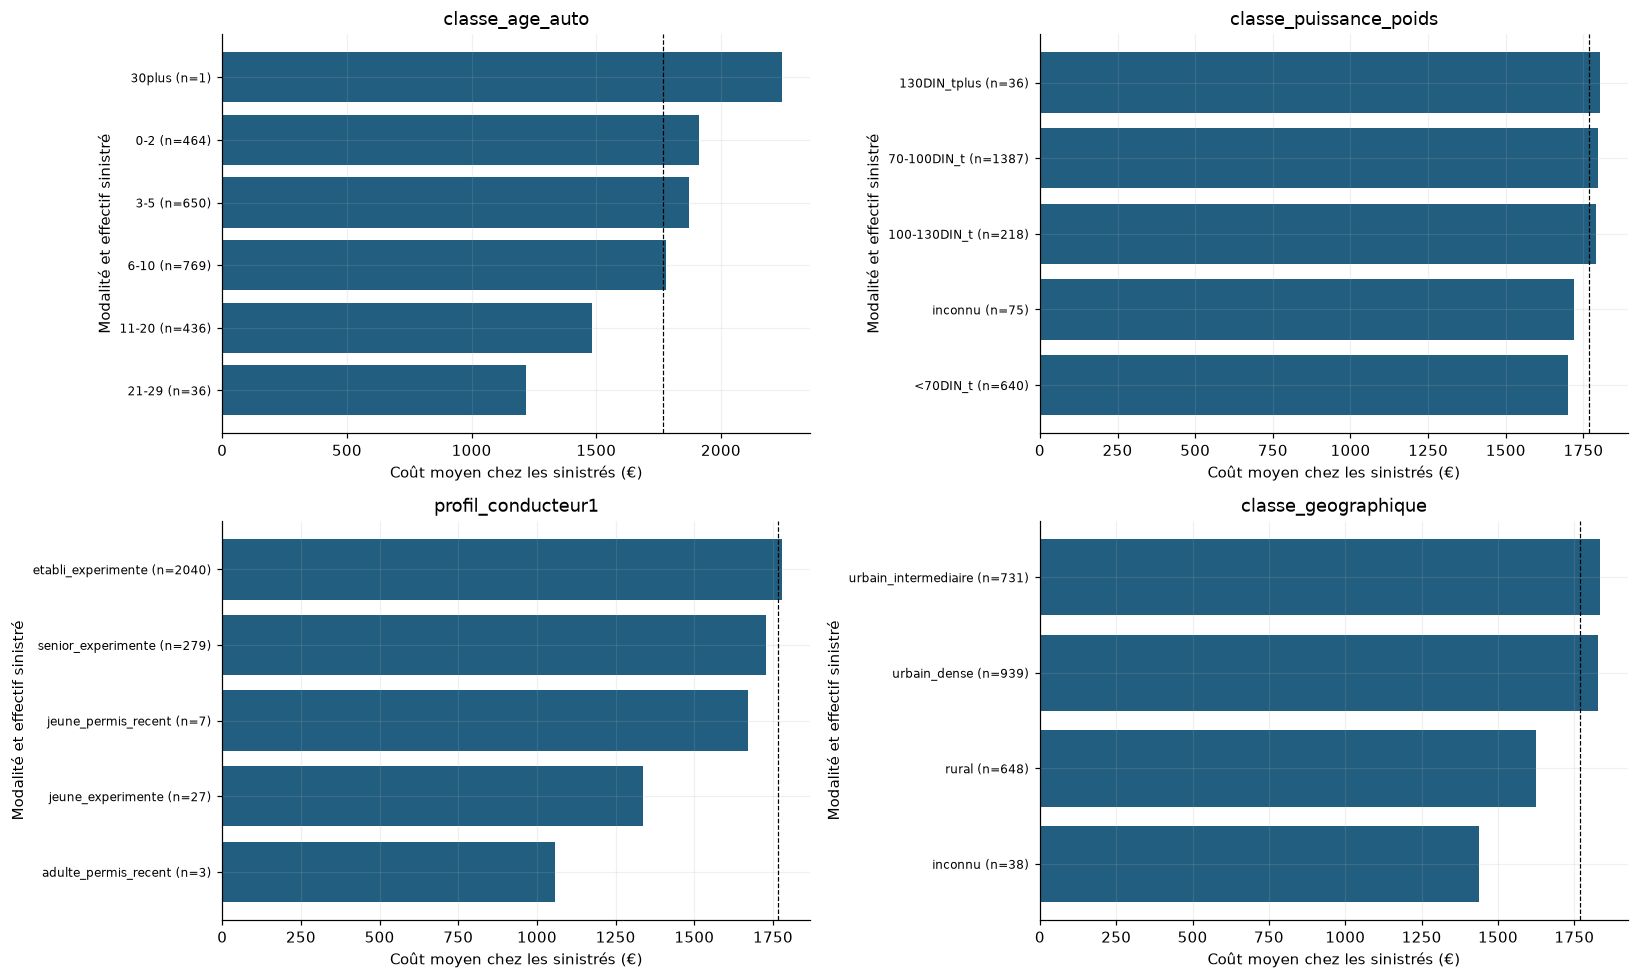

Version complète mixte : 28 variables, dont 26 qualitatives.


"""Création et sélection de variables qualitatives pour la GRAVITÉ uniquement.
Les regroupements ne consultent aucun résultat de sinistre, ni taux de sinistralité.
"""
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator,TransformerMixin,RegressorMixin
from sklearn.compose import ColumnTransformer,make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor
from gravite_pipeline import SeverityFeatures,FORBIDDEN
from metier_features import BusinessFeatures

QUAL_BLOCKS=('age_auto','valeur_gabarit','performance','identite_auto','conducteurs','contrat','geographie','croisements')

def cut_category(s,bounds,labels):
    return pd.cut(s,bounds,labels=labels,right=False).astype(object).fillna('inconnu')

class QualitativeFeatures(TransformerMixin,BaseEstimator):
    def __init__(self,blocks=(),representation='mixte',rare_threshold=10,model_level='modele',
                 price_method='metier',geo_level=3):
        self.blocks=blocks
        self.representation=representation
        self.rare_threshold=rare_threshold
        self.model_level=model_level
        self.price_method=price_method
        self.geo_level=geo_level

    def _clean(self,X):
        return SeverityFeatures(profile='raw',clean=True,geography='none').fit_transform(X)

    def _categories(self,X):
        f=self._clean(X); out=pd.DataFrame(index=X.index)
        a=f.anciennete_vehicule
        out['classe_age_auto']=cut_category(a,[-np.inf,3,6,11,21,30,np.inf],
            ['0-2','3-5','6-10','11-20','21-29','30plus'])
        if self.price_method=='quantiles':
            edges=self.price_edges_
            labels=['quantile_'+str(i+1) for i in range(len(edges)-1)]
        else:
            edges=[-np.inf,10000,20000,35000,60000,np.inf]
            labels=['<10k','10-20k','20-35k','35-60k','60kplus']
        out['classe_prix_auto']=cut_category(f.prix_vehicule,edges,labels)
        out['classe_gabarit']=cut_category(f.poids_vehicule,[-np.inf,1000,1400,1800,np.inf],
                         ['<1000kg','1000-1400kg','1400-1800kg','1800kgplus'])
        out['classe_puissance']=cut_category(f.din_vehicule,[-np.inf,75,110,150,np.inf],
                         ['<75DIN','75-110DIN','110-150DIN','150DINplus'])
        ratio=1000*f.din_vehicule/f.poids_vehicule.where(f.poids_vehicule.gt(0))
        out['classe_puissance_poids']=cut_category(ratio,[-np.inf,70,100,130,np.inf],
                         ['<70DIN_t','70-100DIN_t','100-130DIN_t','130DIN_tplus'])
        out['classe_motorisation']=f.essence_vehicule.astype(object)
        out['classe_type_vehicule']=f.type_vehicule.astype(object)
        for i in [1,2]:
            age=f[f'age_conducteur{i}']; exp=f[f'anciennete_permis{i}']
            ac=cut_category(age,[-np.inf,25,40,60,75,np.inf],['<25','25-39','40-59','60-74','75plus'])
            ec=cut_category(exp,[-np.inf,3,10,30,np.inf],['permis<3','permis3-9','permis10-29','permis30plus'])
            profile=pd.Series('etabli_experimente',index=X.index,dtype=object)
            profile.loc[age.lt(25)&exp.ge(3)]='jeune_experimente'
            profile.loc[age.lt(25)&exp.lt(3)]='jeune_permis_recent'
            profile.loc[age.ge(25)&exp.lt(3)]='adulte_permis_recent'
            profile.loc[age.ge(75)&exp.ge(3)]='senior_experimente'
            profile.loc[age.isna()|exp.isna()]='inconnu'
            if i==2:
                absent=f.conducteur2.eq('No')
                ac.loc[absent]='absent'; ec.loc[absent]='absent'; profile.loc[absent]='absent'
            out[f'classe_age_conducteur{i}']=ac
            out[f'classe_experience{i}']=ec
            out[f'profil_conducteur{i}']=profile
        b=f.bonus
        out['classe_bonus']=pd.Series(np.select([b.eq(.5),b.gt(.5)&b.lt(1),b.eq(1),b.gt(1)],
                   ['minimum_0.5','entre_0.5_et_1','egal_1','superieur_1'],default='inconnu'),index=X.i

In [3]:
from qualitative_features import QualitativeFeatures,QualitativeSeverityEstimator,QUAL_BLOCKS
import copy
QR=REPORTS/'variables_qualitatives'; QR.mkdir(exist_ok=True)
Q_REFERENCE=json.loads((REPORTS/'selection_gelee_avant_holdout.json').read_text())
Q_PARAMS0={k:Q_REFERENCE['config'][k] for k in ['n_estimators','max_depth','learning_rate','min_child_weight','reg_lambda','reg_alpha','subsample','colsample_bytree']}
qview=QualitativeFeatures(blocks=QUAL_BLOCKS).fit_transform(X)
qcolumns=qview.select_dtypes(exclude='number').columns.tolist()
assert not any(k.startswith('frequence_') for k in qview)
qualitative_descriptions=[]
for col in qcolumns:
    t=pd.DataFrame({'modalite':qview[col].astype(str),'montant':y}).groupby('modalite').montant.agg(['count','mean','median','std']).reset_index()
    t.insert(0,'variable',col); t['erreur_standard']=t['std']/np.sqrt(t['count']); t['petit_effectif']=t['count'].lt(30)
    qualitative_descriptions.append(t)
qualitative_descriptions=pd.concat(qualitative_descriptions,ignore_index=True)
qualitative_descriptions.to_csv(QR/'couts_et_effectifs_par_modalite.csv',index=False)
category_summary=pd.DataFrame([{'variable':col,'modalites':qview[col].nunique(),
       'modalites_moins_30':int(qualitative_descriptions.loc[qualitative_descriptions.variable.eq(col),'petit_effectif'].sum())} for col in qcolumns])
display(category_summary)
for col in ['classe_age_auto','identite_auto_regroupee','profil_conducteur1','profil_conducteur2','classe_geographique']:
    display(qualitative_descriptions.loc[qualitative_descriptions.variable.eq(col)].sort_values('count',ascending=False).head(15))
category_summary.to_csv(QR/'audit_granularite_categories.csv',index=False)
fig,axes=plt.subplots(2,2,figsize=(15,9))
for ax,col in zip(axes.flat,['classe_age_auto','classe_puissance_poids','profil_conducteur1','classe_geographique']):
    t=qualitative_descriptions.loc[qualitative_descriptions.variable.eq(col)].sort_values('mean')
    ax.barh(range(len(t)),t['mean']); ax.set_yticks(range(len(t)),[str(v)+f' (n={nn})' for v,nn in zip(t.modalite,t['count'])],fontsize=8)
    ax.axvline(y.mean(),color='black',linestyle='--',linewidth=.8)
    ax.set(title=col,xlabel='Coût moyen chez les sinistrés (€)',ylabel='Modalité et effectif sinistré')
savefig('12_qualitatives_modalites')
print('Version complète mixte :',qview.shape[1],'variables, dont',len(qcolumns),'qualitatives.')
display(Code((HERE/'qualitative_features.py').read_text(),language='python'))

### 10.2 Comparaison des représentations, des granularités et de la sélection

On compare 16 ensembles : référence ; sept ajouts de familles et le niveau géographique 7 ; croisements ; toutes les catégories en complément des deux montants/ancienneté bruts ; une version entièrement qualitative ; catégories ajoutées aux variables brutes étendues ; familles de modèles ; seuil de rareté 25 ; classes de prix en quartiles.

Chaque ensemble reçoit le **même budget** : deux objectifs (quadratique/Gamma) et deux régularisations. Les 64 candidats sont comparés sur les mêmes trois plis par client. Pour les meilleurs représentants de chaque objectif, on retire les blocs qualitatifs un à un et on remesure leur combinaison favorable. Les retraits portent sur les catégories créées ; quand les variables brutes sont conservées, leur information peut rester accessible au modèle.

Le notebook teste ainsi si une représentation regroupée est utile, et à quel niveau de détail, sans supposer que davantage de modalités améliore la prédiction. Les meilleures différences de CV doivent être confrontées à la validation imbriquée suivante.

Les retraits sont conditionnels aux autres blocs : un croisement encore présent peut conserver une partie de l’information du groupe retiré. Ils ne constituent pas une preuve de causalité ni d’indispensabilité individuelle.

,name,objective,variables,qualitatives,rmse,mae
31,geographie3__gamma__regulier_profondeur1,reg:gamma,5,3,"1,448.380",924.283
30,geographie3__gamma__profondeur3,reg:gamma,5,3,"1,448.691",919.875
29,geographie3__squarederror__regulier_profondeur1,reg:squarederror,5,3,"1,448.749",928.451
23,conducteurs__gamma__regulier_profondeur1,reg:gamma,9,7,"1,449.283",926.012
28,geographie3__squarederror__profondeur3,reg:squarederror,5,3,"1,449.349",927.969
0,reference__squarederror__profondeur3,reg:squarederror,3,1,"1,449.729",929.352
21,conducteurs__squarederror__regulier_profondeur1,reg:squarederror,9,7,"1,449.809",930.256
2,reference__gamma__profondeur3,reg:gamma,3,1,"1,449.993",923.389
10,valeur_gabarit__gamma__profondeur3,reg:gamma,5,3,"1,450.199",923.946
4,age_auto__squarederror__profondeur3,reg:squarederror,4,2,"1,450.207",929.489


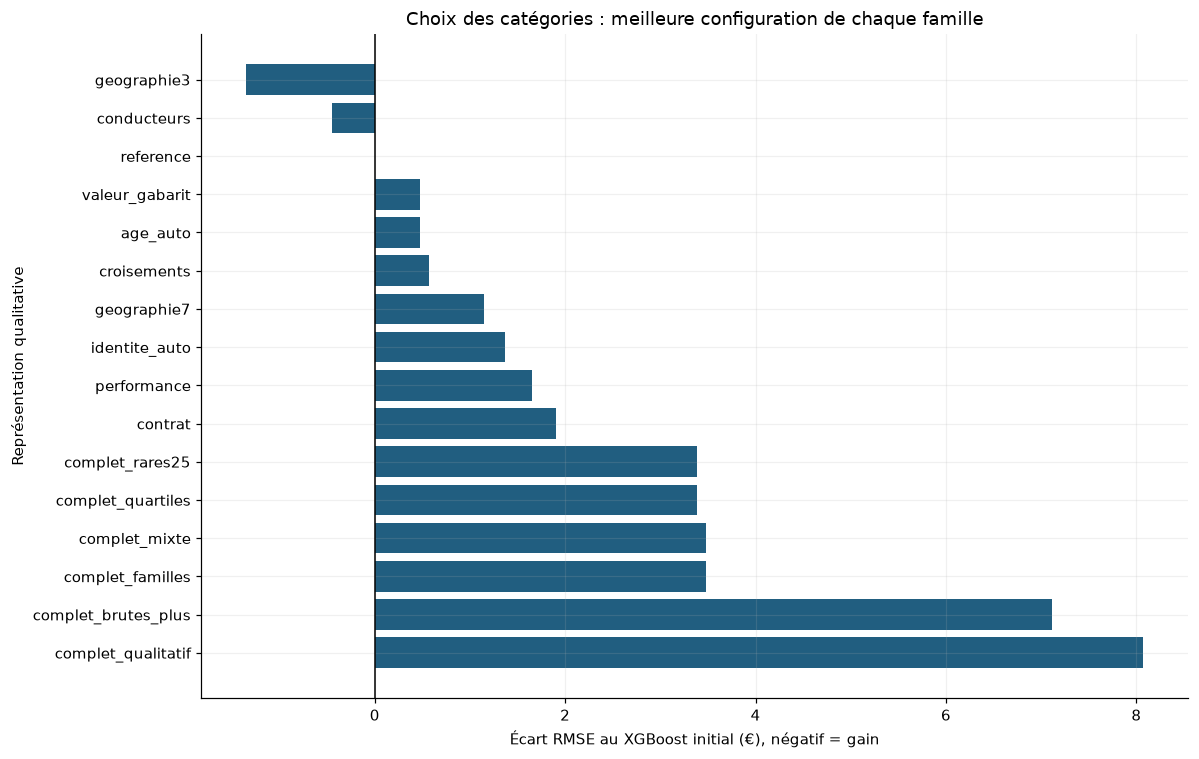

In [4]:
Q_FEATURES=[('reference',dict(blocks=()))]
for label,blocks in [('age_auto',('age_auto',)),('valeur_gabarit',('valeur_gabarit',)),('performance',('performance',)),
                     ('identite_auto',('identite_auto',)),('conducteurs',('conducteurs',)),('contrat',('contrat',)),
                     ('geographie3',('geographie',)),('croisements',('croisements',))]:
    Q_FEATURES.append((label,dict(blocks=blocks)))
Q_FEATURES += [
 ('geographie7',dict(blocks=('geographie',),geo_level=7)),
 ('complet_mixte',dict(blocks=QUAL_BLOCKS)),
 ('complet_qualitatif',dict(blocks=QUAL_BLOCKS,representation='qualitative')),
 ('complet_brutes_plus',dict(blocks=QUAL_BLOCKS,representation='brutes_plus')),
 ('complet_familles',dict(blocks=QUAL_BLOCKS,model_level='famille')),
 ('complet_rares25',dict(blocks=QUAL_BLOCKS,rare_threshold=25)),
 ('complet_quartiles',dict(blocks=QUAL_BLOCKS,price_method='quantiles')),
]
assert len(Q_FEATURES)==16
Q_HYPERS={'profondeur3':Q_PARAMS0,
          'regulier_profondeur1':dict(n_estimators=400,max_depth=1,learning_rate=.03,min_child_weight=40,reg_lambda=20,reg_alpha=0,subsample=.9,colsample_bytree=1.)}
Q_PLAN=[{'name':family+'__'+obj.split(':')[1]+'__'+h,'family':family,'spec':copy.deepcopy(spec),'objective':obj,'params':params}
        for family,spec in Q_FEATURES for obj in ['reg:squarederror','reg:gamma'] for h,params in Q_HYPERS.items()]
(QR/'plan_64_candidats.json').write_text(json.dumps(Q_PLAN,indent=2,ensure_ascii=False))
Q_ROWS=[]; Q_FOLDS=[]; Q_CONFIGS={}; Q_EVALUATIONS=0

def q_evaluate(cfg,xx,yy,gg,splits,run,stage):
    global Q_EVALUATIONS
    pp=np.empty(len(yy)); train_rmse=[]
    for k,(tr,va) in enumerate(splits):
        assert not set(gg[tr])&set(gg[va])
        with threadpool_limits(limits=2):
            m=QualitativeSeverityEstimator(cfg['spec'],cfg['params'],cfg['objective']).fit(xx.iloc[tr],yy[tr])
        pp[va]=m.predict(xx.iloc[va]); train_rmse.append(rmse(yy[tr],m.predict(xx.iloc[tr])))
        Q_FOLDS.append({'run':run,'name':cfg['name'],'fold':k,**scores(yy[va],pp[va])})
    row={'run':run,'name':cfg['name'],'family':cfg['family'],'stage':stage,'objective':cfg['objective'],
         'variables':len(m.feature_columns_),'qualitatives':len(m.qualitative_columns_),
         'train_rmse':np.mean(train_rmse),**scores(yy,pp)}
    Q_ROWS.append(row); Q_CONFIGS[run+'::'+cfg['name']]=copy.deepcopy(cfg); Q_EVALUATIONS+=1
    pd.DataFrame(Q_ROWS).to_csv(QR/'journal_essais.csv',index=False)
    (QR/'progression.json').write_text(json.dumps({'run':run,'candidate':cfg['name'],'evaluations':Q_EVALUATIONS}))
    return {'row':row,'cfg':copy.deepcopy(cfg),'oof':pp,'features':m.feature_columns_}

def q_search(xx,yy,gg,run,splits=None):
    if splits is None: splits=list(GroupKFold(n_splits=3,shuffle=True,random_state=173).split(xx,groups=gg))
    results=[q_evaluate(cfg,xx,yy,gg,splits,run,'plan_64') for cfg in Q_PLAN]
    for obj in ['reg:squarederror','reg:gamma']:
        parent=min([r for r in results if r['cfg']['objective']==obj],key=lambda r:r['row']['rmse'])
        favorable=[]
        for block in parent['cfg']['spec'].get('blocks',()):
            cfg=copy.deepcopy(parent['cfg']); cfg['name']+='__sans_'+block
            cfg['spec']['blocks']=[b for b in cfg['spec']['blocks'] if b!=block]
            r=q_evaluate(cfg,xx,yy,gg,splits,run,'ablation'); results.append(r)
            if r['row']['rmse']<parent['row']['rmse']: favorable.append(block)
        if len(favorable)>1:
            cfg=copy.deepcopy(parent['cfg']); cfg['name']+='__retraits_combines'
            cfg['spec']['blocks']=[b for b in cfg['spec']['blocks'] if b not in favorable]
            results.append(q_evaluate(cfg,xx,yy,gg,splits,run,'ablation_combinee'))
    pd.DataFrame(Q_FOLDS).to_csv(QR/'scores_par_pli.csv',index=False)
    (QR/'configurations.json').write_text(json.dumps(Q_CONFIGS,indent=2,ensure_ascii=False))
    return min(results,key=lambda r:r['row']['rmse']),results

Q_BEST,Q_DEV=q_search(X,y,groups,'developpement',FOLDS)
qranking=pd.DataFrame([r['row'] for r in Q_DEV]).sort_values('rmse')
qranking.to_csv(QR/'classement_developpement.csv',index=False)
qref=next(r for r in Q_DEV if r['cfg']['name']=='reference__squarederror__profondeur3')
np.testing.assert_allclose(qref['row']['rmse'],Q_REFERENCE['oof_scores']['rmse'],rtol=0,atol=1e-6)
display(qranking[['name','objective','variables','qualitatives','rmse','mae']].head(20))
byfamily=qranking.groupby('family',sort=False).first().sort_values('rmse')
fig,ax=plt.subplots(figsize=(11,7)); t=byfamily.iloc[::-1]
ax.barh(t.index,t.rmse-qref['row']['rmse']); ax.axvline(0,color='black',linewidth=1)
ax.set(xlabel='Écart RMSE au XGBoost initial (€), négatif = gain',ylabel='Représentation qualitative',title='Choix des catégories : meilleure configuration de chaque famille')
savefig('13_qualitatives_comparaison')

### 10.3 Validation imbriquée du choix des variables qualitatives

Dans chacun des trois sous-trains externes, on rejoue les 64 choix de catégories/objectifs/réglages et les ablations. Le pli externe n'est utilisé qu'après cette sélection. Les regroupements rares et les quartiles sont également réappris dans chaque apprentissage interne.

On compare les prédictions externes de cette procédure à celles de la référence initiale sur les mêmes contrats. Le holdout ancien n'est pas utilisé. Le bootstrap par client fournit un intervalle descriptif ; les limites liées aux données déjà explorées restent applicables.

In [5]:
q_nested=np.empty(len(y)); q_initial=np.empty(len(y)); q_choices=[]
for k,(tr,va) in enumerate(FOLDS):
    chosen,_=q_search(X.iloc[tr],y[tr],groups[tr],'externe_'+str(k))
    cfg=chosen['cfg']
    with threadpool_limits(limits=2):
        m=QualitativeSeverityEstimator(cfg['spec'],cfg['params'],cfg['objective']).fit(X.iloc[tr],y[tr])
        ref=QualitativeSeverityEstimator({},Q_PARAMS0).fit(X.iloc[tr],y[tr])
    q_nested[va]=m.predict(X.iloc[va]); q_initial[va]=ref.predict(X.iloc[va])
    q_choices.append({'fold':k,'selected':cfg['name'],'variables':len(m.feature_columns_),
                      'qualitatives':len(m.qualitative_columns_),'rmse_externe':rmse(y[va],q_nested[va]),
                      'rmse_initial':rmse(y[va],q_initial[va])})
    pd.DataFrame(q_choices).to_csv(QR/'choix_par_pli_externe.csv',index=False)
    print('Externe qualitatif',k,cfg['name'],flush=True)
np.testing.assert_allclose(q_initial,qref['oof'],rtol=0,atol=1e-6)
q_validation=pd.DataFrame([{'procedure':'reference_initiale',**scores(y,q_initial)},
                            {'procedure':'selection_qualitative',**scores(y,q_nested)}])
display(pd.DataFrame(q_choices)); display(q_validation)
q_validation.to_csv(QR/'validation_imbriquee.csv',index=False)
q_rng=np.random.default_rng(1234); q_ids=np.unique(groups); q_indices=[np.flatnonzero(groups==g) for g in q_ids]
q_gains=[]
for _ in range(1000):
    ii=np.concatenate([q_indices[j] for j in q_rng.integers(0,len(q_ids),len(q_ids))])
    q_gains.append(rmse(y[ii],q_initial[ii])-rmse(y[ii],q_nested[ii]))
q_ci=np.quantile(q_gains,[.025,.975])
Q_VALIDATION={'initial_rmse':rmse(y,q_initial),'selection_rmse':rmse(y,q_nested),
    'gain_rmse':rmse(y,q_initial)-rmse(y,q_nested),'ci95_low':float(q_ci[0]),'ci95_high':float(q_ci[1]),
    'bootstrap_unit':'client','replicates':1000,'old_holdout_used':False,'frequency_model_trained':False,
    'frequency_target_encoding_used':False,'historical_exploration_caveat':True}
(QR/'incertitude.json').write_text(json.dumps(Q_VALIDATION,indent=2,ensure_ascii=False))
note(f'**Validation de la sélection qualitative :** gain {Q_VALIDATION["gain_rmse"]:+,.2f} €, '
     f'intervalle descriptif 95 % [{q_ci[0]:+,.2f} ; {q_ci[1]:+,.2f}] €. '
     + ('Le gain est positif sous les limites annoncées.' if q_ci[0]>0 else
        'L’amélioration stable n’est pas démontrée : les regroupements ont été mesurés, sans être supposés efficaces.'))

Externe qualitatif 0 performance__squarederror__regulier_profondeur1


Externe qualitatif 1 geographie7__squarederror__profondeur3


Externe qualitatif 2 croisements__gamma__regulier_profondeur1


,fold,selected,variables,qualitatives,rmse_externe,rmse_initial
0,0,performance__squarederror__regulier_profondeur1,7,5,"1,323.341","1,317.678"
1,1,geographie7__squarederror__profondeur3,5,3,"1,591.543","1,589.805"
2,2,croisements__gamma__regulier_profondeur1,7,5,"1,428.994","1,428.581"


,procedure,rmse,mae,gamma_deviance,r2,ratio_predit_observe,moyenne_predite
0,reference_initiale,"1,449.729",929.352,0.397,0.016,0.999,"1,766.294"
1,selection_qualitative,"1,452.217",927.942,0.399,0.012,0.998,"1,763.199"


**Validation de la sélection qualitative :** gain -2.49 €, intervalle descriptif 95 % [-6.95 ; +1.77] €. L’amélioration stable n’est pas démontrée : les regroupements ont été mesurés, sans être supposés efficaces.

### 10.4 Modèle qualitatif complet, version sélectionnée et explication des choix

Les deux versions sont entraînées sur tous les coûts positifs : la meilleure recette de développement et la meilleure version **mixte complète**, qui conserve toutes les catégories définies. Les prédictions restent des coûts conditionnels. Les listes ci-dessous distinguent les variables qualitatives des deux variables numériques conservées dans la version mixte.

Les résultats ne permettent pas de présenter les voitures puissantes, anciennes ou certaines communes comme systématiquement plus coûteuses. Le livrable montre ce que ces définitions produisent dans les données, leur couverture et les raisons de leur maintien ou de leur retrait.

In [6]:
q_positive=train.loc[train.nombre_sinistres.gt(0)].copy()
q_full=min([r for r in Q_DEV if r['cfg']['family']=='complet_mixte' and r['row']['stage']=='plan_64'],key=lambda r:r['row']['rmse'])
q_outputs=[]; q_models={}
for label,result in [('selectionne',Q_BEST),('complet',q_full)]:
    cfg=result['cfg']
    with threadpool_limits(limits=2):
        m=QualitativeSeverityEstimator(cfg['spec'],cfg['params'],cfg['objective']).fit(q_positive[FEATURES],q_positive[TARGET])
    pp=m.predict(test[FEATURES]); assert np.isfinite(pp).all() and (pp>0).all() and len(pp)==len(test)
    pd.DataFrame({'index':test['index'].to_numpy(),'gravite_predite':pp}).to_csv(QR/('gravite_test_'+label+'.csv'),index=False)
    path=MODELS/('gravite_qualitative_'+label+'.joblib'); joblib.dump(m,path)
    np.testing.assert_allclose(joblib.load(path).predict(test[FEATURES].head(100)),pp[:100],rtol=0,atol=1e-6)
    assert not any(k.startswith('frequence_') for k in m.feature_columns_)
    q_models[label]=m
    q_outputs.append({'label':label,'configuration':cfg,'features':m.feature_columns_,'qualitative_features':m.qualitative_columns_,
       'n_variables':len(m.feature_columns_),'n_qualitative':len(m.qualitative_columns_),'development_metrics':result['row'],
       'model_path':str(path.relative_to(HERE)),'n_test_predictions':len(pp),'reload_equal':True})
q_decisions=pd.DataFrame([{'variable':col,'qualitative':col in q_models['complet'].qualitative_columns_,
    'version_complete':col in q_models['complet'].feature_columns_,
    'version_selectionnee':col in q_models['selectionne'].feature_columns_} for col in
    sorted(set(q_models['complet'].feature_columns_)|set(q_models['selectionne'].feature_columns_))])
q_decisions.to_csv(QR/'decisions_variables.csv',index=False); display(q_decisions)
(QR/'manifest.json').write_text(json.dumps({'models':q_outputs,'validation':Q_VALIDATION,'versions':VERSIONS,
    'target':'montant_sinistre conditionnellement positif','frequency_model_trained':False,'frequency_encodings_used':False,
    'development_candidates':len(Q_DEV),'total_cv_evaluations':Q_EVALUATIONS,
    'geography_temporal_compatibility_unknown':True},indent=2,ensure_ascii=False))
display(pd.DataFrame([{'version':d['label'],'objectif':d['configuration']['objective'],
 'variables':d['n_variables'],'qualitatives':d['n_qualitative'],'rmse_cv':d['development_metrics']['rmse']} for d in q_outputs]))
note(f'**Travail qualitatif livré :** {len(q_models["complet"].qualitative_columns_)} variables qualitatives dans la version mixte complète, '
     f'{len(q_models["selectionne"].qualitative_columns_)} dans la version sélectionnée. '
     'Le journal documente les granularités, la rareté, les croisements, les objectifs et les retraits. '
     'Aucun modèle de fréquence ni encodage par taux de sinistre n’entre dans ces deux pipelines.')

,variable,qualitative,version_complete,version_selectionnee
0,anciennete_vehicule,False,True,True
1,classe_age_auto,True,True,False
2,classe_age_conducteur1,True,True,False
3,classe_age_conducteur2,True,True,False
4,classe_bonus,True,True,False
5,classe_experience1,True,True,False
6,classe_experience2,True,True,False
7,classe_gabarit,True,True,False
8,classe_geographique,True,True,True
9,classe_motorisation,True,True,False


,version,objectif,variables,qualitatives,rmse_cv
0,selectionne,reg:gamma,5,3,"1,448.380"
1,complet,reg:gamma,28,26,"1,453.203"


**Travail qualitatif livré :** 26 variables qualitatives dans la version mixte complète, 3 dans la version sélectionnée. Le journal documente les granularités, la rareté, les croisements, les objectifs et les retraits. Aucun modèle de fréquence ni encodage par taux de sinistre n’entre dans ces deux pipelines.

### Contrôle du regroupement par famille

Le découpage en premier token s’applique au **nom du modèle**, puis la marque complète est conservée : `MERCEDES BENZ` + `C220 CDI` devient `MERCEDES BENZ::C220`, et reste distinct de `MERCEDES BENZ::E220`. Les comparaisons des variantes « familles » ont été recalculées dans les quatre recherches (développement et trois sous-trains externes), soit 48 ajustements concernés. Les meilleurs parents de chaque objectif et les choix finaux restent identiques ; les scores et la figure des familles sont mis à jour. Les preuves sont dans `verification_familles_corrigees.csv` et `verification_correction.json`.


## 11. Retrait individuel de la taille de commune

**Demande :** retirer uniquement `classe_taille_commune` du XGBoost Gamma retenu au §10 et mesurer le RMSE. On conserve `type_contrat`, `prix_vehicule`, `anciennete_vehicule` et `classe_geographique`.

**Comparaison contrôlée :** objectif Gamma, 400 arbres, profondeur 1 et tous les autres paramètres inchangés. Les deux versions sont réentraînées sur les mêmes trois plis par client, chez les 2 356 sinistrés du développement. Les médianes et encodages sont réappris dans chaque sous-train. Le RMSE global porte sur toutes les prédictions hors pli, et non sur les données ayant servi à ajuster le modèle. Le holdout historique n'est pas réutilisé. Aucun seuil de montant ni autre sélection de variables n'est ajouté.

Les résultats et les prédictions de cette comparaison sont conservés dans `reports/ablation_taille_commune/`. Le modèle à cinq variables du §10 reste archivé sous son nom historique. La nouvelle version à quatre variables est sauvegardée séparément dans `models/gravite_sans_taille_commune.joblib` et devient la version retenue selon cette demande.

In [3]:
from qualitative_features import QualitativeSeverityEstimator
import copy
AR=REPORTS/'ablation_taille_commune'; AR.mkdir(exist_ok=True)
a_parent_manifest=json.loads((REPORTS/'variables_qualitatives/manifest.json').read_text())
a_parent=next(d for d in a_parent_manifest['models'] if d['label']=='selectionne')
a_cfg=copy.deepcopy(a_parent['configuration'])
assert a_cfg['objective']=='reg:gamma'
a_without=copy.deepcopy(a_cfg['spec'])
a_without['drop']=['classe_taille_commune']
a_specs={'avec_taille_commune':a_cfg['spec'],'sans_taille_commune':a_without}
a_predictions={}; a_fold_rows=[]; a_rows=[]
for label,spec in a_specs.items():
    pp=np.empty(len(y))
    for fold,(tr,va) in enumerate(FOLDS):
        assert not set(groups[tr]) & set(groups[va])
        with threadpool_limits(limits=2):
            fitted=QualitativeSeverityEstimator(spec,a_cfg['params'],a_cfg['objective']).fit(X.iloc[tr],y[tr])
        pp[va]=fitted.predict(X.iloc[va])
        assert ('classe_taille_commune' in fitted.feature_columns_) == (label=='avec_taille_commune')
        a_fold_rows.append({'version':label,'pli':fold,'n_validation':len(va),**scores(y[va],pp[va])})
    a_predictions[label]=pp
    a_rows.append({'version':label,'n_variables':len(fitted.feature_columns_),
                   'n_evaluation':len(y),**scores(y,pp)})
a_comparison=pd.DataFrame(a_rows)
np.testing.assert_allclose(a_comparison.loc[0,'rmse'],a_parent['development_metrics']['rmse'],rtol=0,atol=1e-6)
a_comparison.to_csv(AR/'comparaison_rmse.csv',index=False)
pd.DataFrame(a_fold_rows).to_csv(AR/'scores_par_pli.csv',index=False)
pd.DataFrame({'index':dev['index'],'id_client':groups,'pli':fold_ids,'montant':y,
    **a_predictions}).to_csv(AR/'predictions_hors_pli.csv',index=False)
a_before=float(a_comparison.loc[0,'rmse']); a_after=float(a_comparison.loc[1,'rmse'])
a_difference=a_after-a_before
display(a_comparison[['version','n_variables','n_evaluation','rmse','mae']])
display(pd.DataFrame(a_fold_rows)[['version','pli','n_validation','rmse']])
print(f'RMSE sans taille de commune : {a_after:,.6f} euros ; avant : {a_before:,.6f} euros ; ecart apres - avant : {a_difference:+.6f} euros.',flush=True)


,version,n_variables,n_evaluation,rmse,mae
0,avec_taille_commune,5,2356,"1,448.380",924.283
1,sans_taille_commune,4,2356,"1,448.340",924.335


,version,pli,n_validation,rmse
0,avec_taille_commune,0,785,"1,316.400"
1,avec_taille_commune,1,786,"1,590.268"
2,avec_taille_commune,2,785,"1,425.131"
3,sans_taille_commune,0,785,"1,317.627"
4,sans_taille_commune,1,786,"1,590.679"
5,sans_taille_commune,2,785,"1,423.416"


RMSE sans taille de commune : 1,448.339904 euros ; avant : 1,448.379763 euros ; ecart apres - avant : -0.039859 euros.


In [4]:
a_positive=train.loc[train.nombre_sinistres.gt(0)].copy()
with threadpool_limits(limits=2):
    a_final=QualitativeSeverityEstimator(a_without,a_cfg['params'],a_cfg['objective']).fit(
        a_positive[FEATURES],a_positive[TARGET])
assert a_final.feature_columns_==['type_contrat','prix_vehicule','anciennete_vehicule','classe_geographique']
a_test=a_final.predict(test[FEATURES])
assert len(a_test)==len(test) and np.isfinite(a_test).all() and (a_test>0).all()
a_model_path=MODELS/'gravite_sans_taille_commune.joblib'
joblib.dump(a_final,a_model_path)
a_reloaded=joblib.load(a_model_path)
np.testing.assert_allclose(a_reloaded.predict(test[FEATURES]),a_test,rtol=0,atol=1e-8)
# Changer uniquement la population du référentiel ne doit plus changer les prédictions.
a_probe=copy.deepcopy(a_reloaded)
a_probe.pipeline_.named_steps['qualitative'].geo_.reference_['population_2018']=1.e9
np.testing.assert_allclose(a_probe.predict(test[FEATURES].head(1000)),a_test[:1000],rtol=0,atol=1e-8)
a_encoded=a_final.pipeline_.named_steps['encoding'].get_feature_names_out().tolist()
assert not any('taille_commune' in col for col in a_encoded)
pd.DataFrame({'index':test['index'].to_numpy(),'gravite_predite':a_test}).to_csv(AR/'gravite_test.csv',index=False)
a_manifest={'target':'montant_sinistre conditionnellement positif','requested_removal':'classe_taille_commune',
    'status':'version retenue apres retrait demande, sans nouvelle optimisation',
    'model_path':str(a_model_path.relative_to(HERE)),
    'parent_model_path':a_parent['model_path'],'parent_manifest':'reports/variables_qualitatives/manifest.json',
    'configuration':{'spec':a_without,'params':a_cfg['params'],'objective':a_cfg['objective']},
    'features':a_final.feature_columns_,'encoded_features':a_encoded,
    'validation':{'method':'predictions hors pli, 3 plis groupes par client identiques au chapitre 10',
        'n_evaluation':len(y),'n_clients':len(np.unique(groups)),
        'rmse_before':a_before,'rmse_after':a_after,'difference_after_minus_before':a_difference,
        'holdout_used':False,'new_hyperparameter_search':False,'already_explored_development':True},
    'training_rows':len(a_positive),'n_test_predictions':len(a_test),'reload_equal':True,
    'population_invariance_verified':True,'frequency_model_trained':False,'frequency_encodings_used':False,
    'qualitative_code_sha256':hashlib.sha256((HERE/'qualitative_features.py').read_bytes()).hexdigest(),
    'versions':VERSIONS}
(AR/'manifest.json').write_text(json.dumps(a_manifest,indent=2,ensure_ascii=False))
note(f'**Résultat demandé : RMSE = {a_after:,.2f} €**, contre {a_before:,.2f} € avec la taille communale '
     f'(écart après − avant : **{a_difference:+,.2f} €**). '
     'Les autres variables et réglages sont identiques. '
     'Ce score de développement reste descriptif sur des données déjà explorées ; il ne mesure pas une cohorte externe neuve. '
     f'La version sans taille communale est enregistrée avec **{len(a_final.feature_columns_)} variables**, '
     f'réentraînée sur {len(a_positive):,} sinistres positifs, et ses {len(a_test):,} prédictions ont été vérifiées après rechargement.')


**Résultat demandé : RMSE = 1,448.34 €**, contre 1,448.38 € avec la taille communale (écart après − avant : **-0.04 €**). Les autres variables et réglages sont identiques. Ce score de développement reste descriptif sur des données déjà explorées ; il ne mesure pas une cohorte externe neuve. La version sans taille communale est enregistrée avec **4 variables**, réentraînée sur 2,917 sinistres positifs, et ses 50,000 prédictions ont été vérifiées après rechargement.

**Conclusion du retrait demandé :** `classe_taille_commune` est supprimée. À objectif, paramètres et plis identiques, le RMSE hors pli est **1 448,34 €**, contre **1 448,38 €** auparavant. Le gain de **0,04 €** est négligeable. La nouvelle version enregistrée conserve quatre variables : `type_contrat`, `prix_vehicule`, `anciennete_vehicule`, `classe_geographique`. Les anciens essais restent archivés ; le modèle actuel est `models/gravite_sans_taille_commune.joblib`.

## 12. Répartition des montants de sinistre strictement positifs

**Demande actualisée :** exclure les montants nuls de la répartition. Le filtre appliqué est `montant_sinistre > 0` : les graphiques, les tranches et les quantiles décrivent uniquement les **2 917 montants positifs** de `train.csv`. Le fichier source reste intact.

Cette section est descriptive sur les montants positifs de tout le fichier, y compris les lignes historiquement réservées. Elle ne sert à aucune nouvelle sélection de variables ou de paramètres. Le modèle à quatre variables du §11 reste inchangé.

Le premier graphique affiche l'histogramme des seuls coûts positifs sur leur plage complète, jusqu'au maximum. Le second donne des tranches explicites ; tous les pourcentages ont pour dénominateur les sinistres positifs. Les bornes basses sont incluses et les bornes hautes exclues. Source : `../Data/train.csv`, millésime des contrats non renseigné.

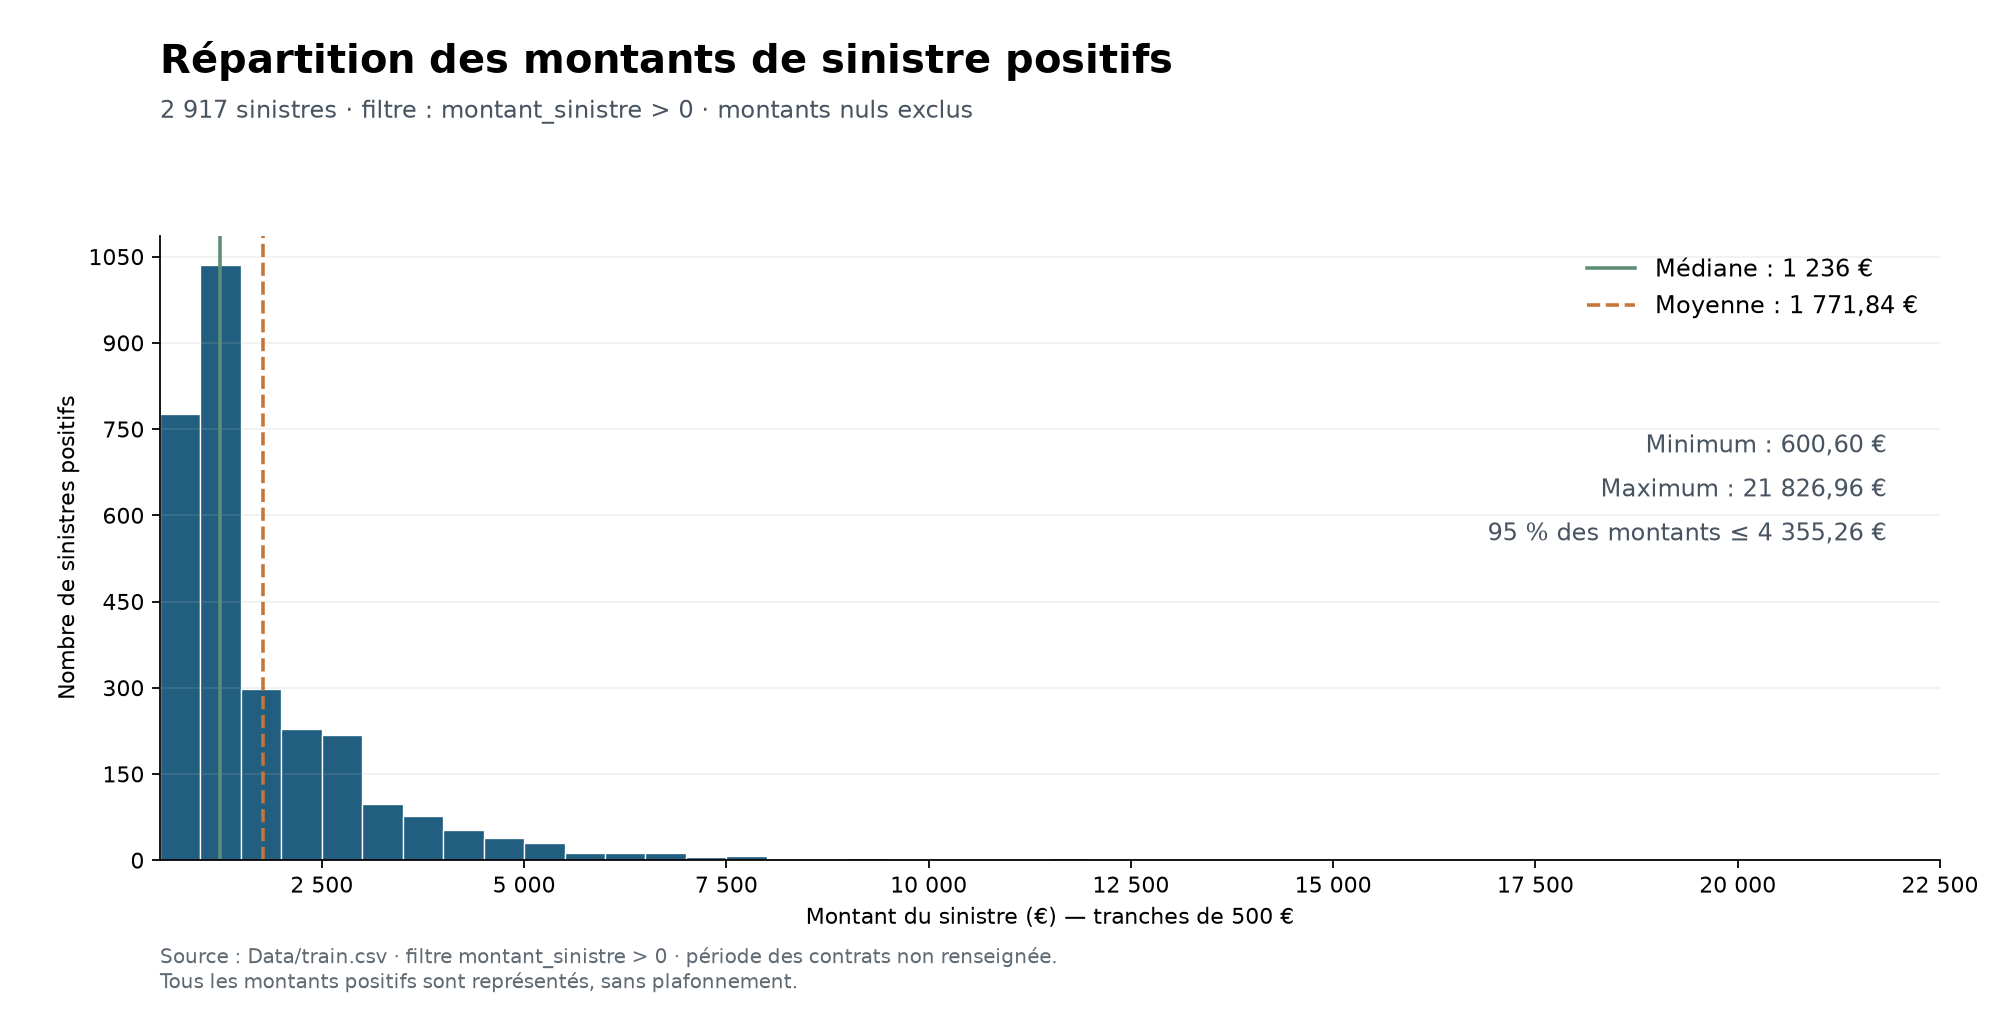

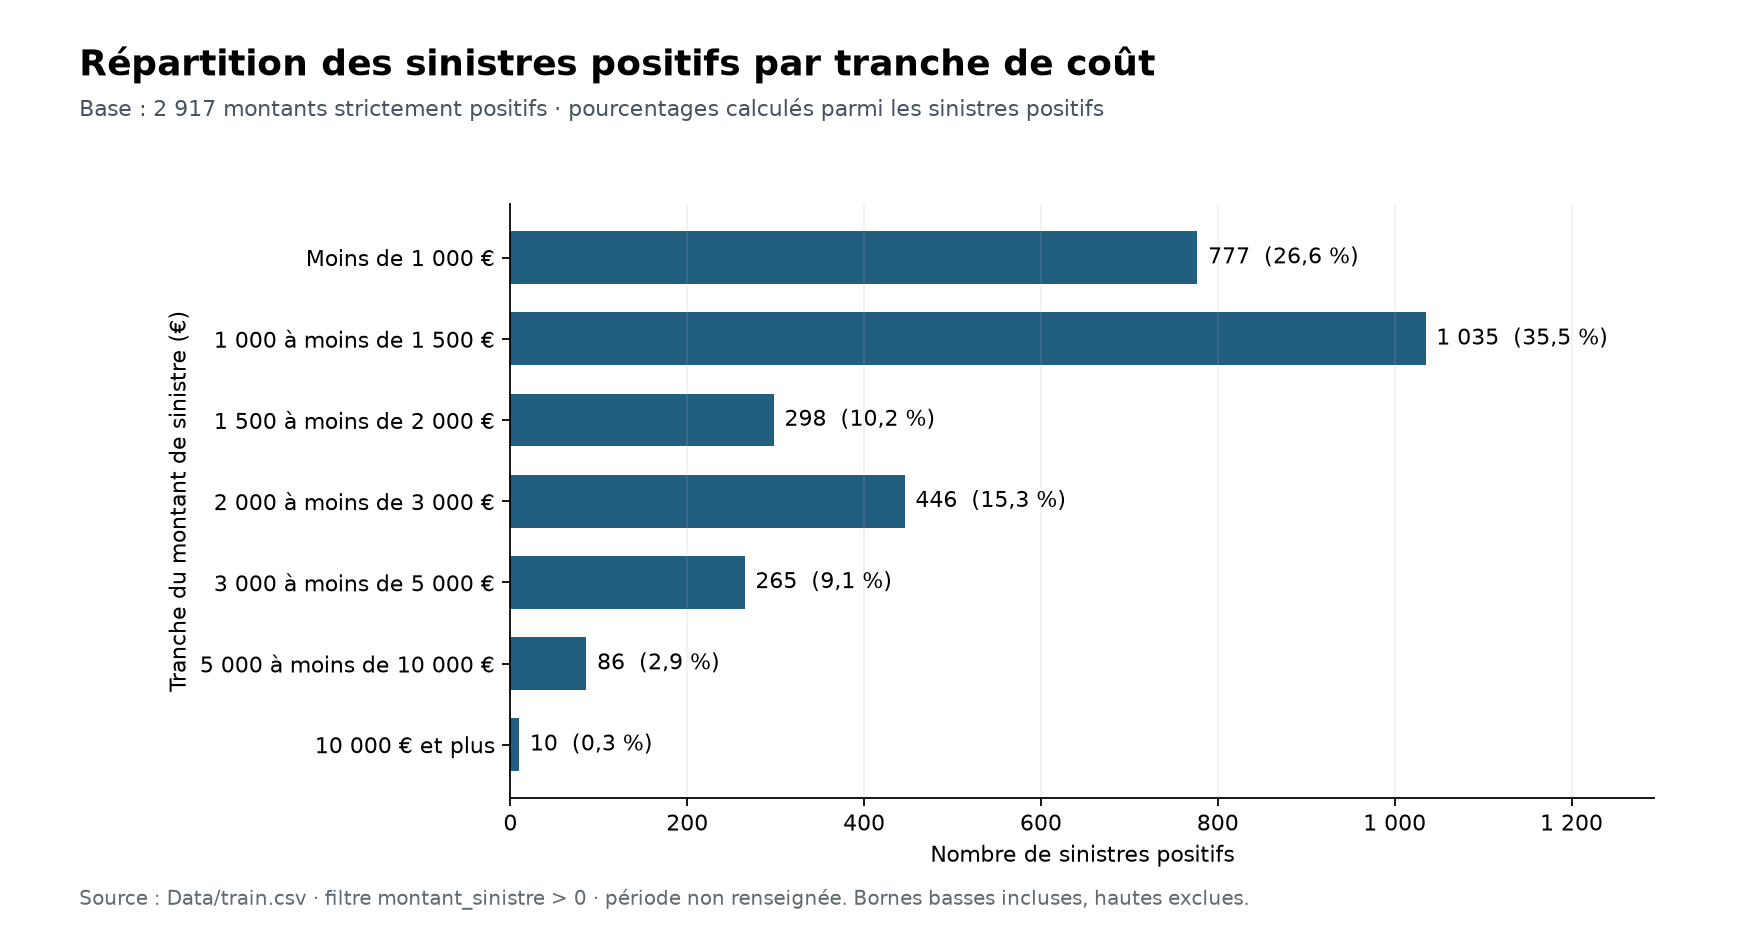

,tranche,effectif,pourcentage_sinistres_positifs
0,0 < montant < 1 000 €,777,26.637
1,1 000 ≤ montant < 1 500 €,1035,35.482
2,1 500 ≤ montant < 2 000 €,298,10.216
3,2 000 ≤ montant < 3 000 €,446,15.290
4,3 000 ≤ montant < 5 000 €,265,9.085
5,5 000 ≤ montant < 10 000 €,86,2.948
6,montant ≥ 10 000 €,10,0.343


,quantile,montant_euros
0,0.250,959.970
1,0.500,"1,236.000"
2,0.750,"2,169.100"
3,0.900,"3,336.740"
4,0.950,"4,355.258"
5,0.990,"6,963.119"


**Lecture — montants positifs uniquement :** chez les sinistrés, le coût médian est **1 236 €**, contre **1 771,84 €** en moyenne. La distribution présente une queue vers les gros montants : 90 % des coûts sont inférieurs ou égaux à 3 336,74 €, 95 % à 4 355,26 € et 99 % à 6 963,12 €. Le maximum atteint 21 826,96 €. Les montants nuls sont exclus de cette répartition ; tous les montants positifs sont conservés. Le fichier source et le modèle du §11 restent inchangés.

In [3]:
from matplotlib.ticker import FuncFormatter,MaxNLocator
DISTRIBUTION=REPORTS/'distribution_sinistres'; DISTRIBUTION.mkdir(exist_ok=True)
d_amount=train['montant_sinistre']
d_positive=d_amount.loc[d_amount.gt(0)]
assert d_amount.notna().all() and d_amount.ge(0).all()
assert d_positive.gt(0).all() and len(d_positive)==2917
d_n=len(d_amount); d_npositive=len(d_positive); d_nzero=int(d_amount.eq(0).sum())
def d_fr(v,decimals=0):
    return f'{v:,.{decimals}f}'.replace(',',' ').replace('.',',')
d_euros=FuncFormatter(lambda v,pos:d_fr(v))
d_metrics={'filtre_repartition':'montant_sinistre > 0','n_echantillon_repartition':len(d_positive),'n_lignes':d_n,'n_montants_nuls':d_nzero,'n_montants_positifs':d_npositive,
    'n_montants_negatifs':int(d_amount.lt(0).sum()),'n_montants_manquants':int(d_amount.isna().sum()),
    'pourcentage_nuls':100*d_nzero/d_n,'pourcentage_positifs':100*d_npositive/d_n,
    'moyenne_tous_contrats':float(d_amount.mean()),
    'montants_positifs':{'minimum':float(d_positive.min()),'maximum':float(d_positive.max()),
        'moyenne':float(d_positive.mean()),'mediane':float(d_positive.median()),
        'quantiles':{str(q):float(d_positive.quantile(q)) for q in [.01,.05,.10,.25,.50,.75,.90,.95,.99]}}}
(DISTRIBUTION/'statistiques.json').write_text(json.dumps(d_metrics,ensure_ascii=False,indent=2))
d_bins=[0,1000,1500,2000,3000,5000,10000,np.inf]
d_labels=['0 < montant < 1 000 €','1 000 ≤ montant < 1 500 €','1 500 ≤ montant < 2 000 €',
          '2 000 ≤ montant < 3 000 €','3 000 ≤ montant < 5 000 €','5 000 ≤ montant < 10 000 €','montant ≥ 10 000 €']
d_counts=pd.cut(d_positive,d_bins,labels=d_labels,right=False).value_counts(sort=False)
d_bands=pd.DataFrame({'tranche':d_labels,'effectif':d_counts.to_numpy()})
d_bands['pourcentage_sinistres_positifs']=100*d_bands.effectif/d_npositive
assert d_bands.effectif.sum()==d_npositive
d_bands.to_csv(DISTRIBUTION/'repartition_par_tranche.csv',index=False)
d_quantiles=pd.DataFrame({'quantile':[.25,.50,.75,.90,.95,.99],
    'montant_euros':[float(d_positive.quantile(q)) for q in [.25,.50,.75,.90,.95,.99]]})
d_quantiles.to_csv(DISTRIBUTION/'quantiles.csv',index=False)

with plt.rc_context({'font.family':'DejaVu Sans','font.size':10,'axes.titlesize':12,'axes.labelsize':10}):
    fig,ax=plt.subplots(figsize=(12.5,6.4))
    fig.subplots_adjust(top=.77,bottom=.16,left=.08,right=.97)
    fig.suptitle('Répartition des montants de sinistre positifs',x=.08,y=.96,ha='left',fontsize=18,fontweight='bold')
    fig.text(.08,.885,f'{d_fr(d_npositive)} sinistres · filtre : montant_sinistre > 0 · montants nuls exclus',fontsize=11,color='#485461')
    d_histbins=np.arange(500,23000,500)
    d_histcounts,_,_=ax.hist(d_positive,bins=d_histbins,color='#215e80',edgecolor='white',linewidth=.6)
    assert int(d_histcounts.sum())==len(d_positive)
    ax.axvline(d_positive.median(),color='#5e8e75',linewidth=1.6,label=f'Médiane : {d_fr(d_positive.median())} €')
    ax.axvline(d_positive.mean(),color='#c67538',linewidth=1.6,linestyle='--',label=f'Moyenne : {d_fr(d_positive.mean(),2)} €')
    ax.set(xlabel='Montant du sinistre (€) — tranches de 500 €',ylabel='Nombre de sinistres positifs',xlim=(500,22500))
    ax.xaxis.set_major_formatter(d_euros); ax.yaxis.set_major_locator(MaxNLocator(integer=True)); ax.xaxis.grid(False)
    ax.legend(loc='upper right',frameon=False,fontsize=11)
    ax.text(.97,.70,f'Minimum : {d_fr(d_positive.min(),2)} €\nMaximum : {d_fr(d_positive.max(),2)} €\n95 % des montants ≤ {d_fr(d_positive.quantile(.95),2)} €',
            transform=ax.transAxes,ha='right',va='top',fontsize=11,color='#485461',linespacing=1.8)
    fig.text(.08,.035,'Source : Data/train.csv · filtre montant_sinistre > 0 · période des contrats non renseignée.\nTous les montants positifs sont représentés, sans plafonnement.',fontsize=9,color='#606a73')
    fig.savefig(DISTRIBUTION/'repartition_montants_positifs.png',dpi=160,facecolor='white')
    display(Image(filename=str(DISTRIBUTION/'repartition_montants_positifs.png')))
    plt.close(fig)

with plt.rc_context({'font.family':'DejaVu Sans','font.size':10,'axes.titlesize':12}):
    fig,ax=plt.subplots(figsize=(11,5.8))
    fig.subplots_adjust(top=.78,bottom=.14,left=.29,right=.94)
    fig.suptitle('Répartition des sinistres positifs par tranche de coût',x=.045,y=.95,ha='left',fontsize=16,fontweight='bold')
    fig.text(.045,.875,f'Base : {d_fr(d_npositive)} montants strictement positifs · pourcentages calculés parmi les sinistres positifs',fontsize=10,color='#485461')
    d_shortlabels=['Moins de 1 000 €','1 000 à moins de 1 500 €','1 500 à moins de 2 000 €',
                  '2 000 à moins de 3 000 €','3 000 à moins de 5 000 €','5 000 à moins de 10 000 €','10 000 € et plus']
    yy=np.arange(len(d_bands)); ax.barh(yy,d_bands.effectif,color='#215e80',height=.65)
    ax.set_yticks(yy,d_shortlabels); ax.invert_yaxis(); ax.yaxis.grid(False)
    ax.set(xlabel='Nombre de sinistres positifs',ylabel='Tranche du montant de sinistre (€)',xlim=(0,float(d_bands.effectif.max())*1.25))
    ax.xaxis.set_major_formatter(d_euros)
    for i,row in d_bands.iterrows():
        ax.text(row.effectif+12,i,f'{d_fr(row.effectif)}  ({d_fr(row.pourcentage_sinistres_positifs,1)} %)',va='center',fontsize=10)
    fig.text(.045,.025,'Source : Data/train.csv · filtre montant_sinistre > 0 · période non renseignée. Bornes basses incluses, hautes exclues.',fontsize=9,color='#606a73')
    fig.savefig(DISTRIBUTION/'repartition_par_tranche.png',dpi=160,facecolor='white')
    display(Image(filename=str(DISTRIBUTION/'repartition_par_tranche.png')))
    plt.close(fig)
display(d_bands); display(d_quantiles)
note(f'**Lecture — montants positifs uniquement :** chez les sinistrés, le coût médian est **{d_fr(d_positive.median())} €**, contre **{d_fr(d_positive.mean(),2)} €** en moyenne. '
     f'La distribution présente une queue vers les gros montants : 90 % des coûts sont inférieurs ou égaux à {d_fr(d_positive.quantile(.90),2)} €, '
     f'95 % à {d_fr(d_positive.quantile(.95),2)} € et 99 % à {d_fr(d_positive.quantile(.99),2)} €. '
     f'Le maximum atteint {d_fr(d_positive.max(),2)} €. Les montants nuls sont exclus de cette répartition ; tous les montants positifs sont conservés. Le fichier source et le modèle du §11 restent inchangés.')


## 13. Deux modèles de gravité par tranche et orientation probabiliste

**Hypothèse à tester :** séparer les coûts inférieurs à 2 000 € des coûts supérieurs ou égaux à 2 000 € peut mieux représenter leur hétérogénéité. Dans tout `train.csv`, ces groupes comptent 2 110 et 807 sinistres. Il s'agit d'un essai complémentaire ; le modèle à quatre variables du §11 constitue la référence et reste sauvegardé.

**Protocole fixé avant le calcul :** un seul seuil, 2 000 €, et les quatre mêmes variables (`type_contrat`, `prix_vehicule`, `anciennete_vehicule`, `classe_geographique`). Chaque expert est un XGBoost Gamma avec exactement les réglages de la référence : 400 arbres, profondeur 1, régularisation et apprentissage inchangés. Le modèle d'orientation est un XGBoost de classification binaire avec les mêmes paramètres de complexité. Il est ajusté uniquement chez les sinistrés, sans rééquilibrage des classes pour ne pas modifier artificiellement leurs probabilités.

Dans chaque sous-train, la tranche est définie par le montant d'apprentissage. Un expert est appris dans chaque tranche, et un modèle d'orientation apprend la probabilité de la tranche haute à partir des seules caractéristiques. **Sur le pli de validation, le montant réel n'est jamais utilisé pour choisir ou pondérer les experts.** La prédiction est :

\[\widehat g(x) = (1-\widehat p_{\geq 2000}(x))\widehat\mu_{<2000}(x) + \widehat p_{\geq 2000}(x)\widehat\mu_{\geq 2000}(x).\]

Chaque moyenne conditionnelle est bornée à son intervalle de définition : l'expert petit reste inférieur à 2 000 € et l'expert grand au moins égal à 2 000 €. Ce n'est pas un plancher ajouté au coût global. Les médianes, modalités rares et encodages de chacun des trois modèles sont appris sur leurs seuls sous-trains respectifs.

On compare les **prédictions finales du système complet** à celles du XGBoost unique, sur les mêmes trois plis par client et les mêmes 2 356 sinistres du développement. Il n'y a aucune nouvelle recherche de seuil, de variables ou de paramètres. Le holdout historique n'est pas réévalué. Les scores restent descriptifs sur un développement déjà exploré, et le bootstrap par client ne remplace pas une cohorte externe neuve. Le modèle d'orientation prédit la taille conditionnelle du sinistre ; aucun modèle de fréquence de sinistres n'est entraîné.

In [3]:
from gravite_tranches import TwoBandSeverityEstimator
from qualitative_features import QualitativeSeverityEstimator
from sklearn.metrics import roc_auc_score,brier_score_loss,log_loss,accuracy_score
import copy
TR=REPORTS/'modele_tranches'; TR.mkdir(exist_ok=True)
t_parent=json.loads((REPORTS/'ablation_taille_commune/manifest.json').read_text())
t_cfg=copy.deepcopy(t_parent['configuration'])
t_threshold=2000.
t_baseline_path=HERE/t_parent['model_path']
t_baseline_sha=hashlib.sha256(t_baseline_path.read_bytes()).hexdigest()
t_baseline_oof=np.empty(len(y)); t_mixture_oof=np.empty(len(y))
t_probability=np.empty(len(y)); t_prior=np.empty(len(y)); t_small=np.empty(len(y)); t_large=np.empty(len(y))
t_small_bounded=np.empty(len(y),dtype=bool); t_large_bounded=np.empty(len(y),dtype=bool)
t_fold_rows=[]; t_training_rows=[]
for fold,(tr,va) in enumerate(FOLDS):
    assert not set(groups[tr]) & set(groups[va])
    with threadpool_limits(limits=2):
        ref=QualitativeSeverityEstimator(t_cfg['spec'],t_cfg['params'],t_cfg['objective']).fit(X.iloc[tr],y[tr])
        mix=TwoBandSeverityEstimator(t_threshold,t_cfg['spec'],t_cfg['params']).fit(X.iloc[tr],y[tr])
    assert mix.feature_columns_==t_parent['features']==ref.feature_columns_
    components=mix.predict_components(X.iloc[va])
    t_baseline_oof[va]=ref.predict(X.iloc[va])
    t_mixture_oof[va]=components.prediction_gravite.to_numpy()
    t_probability[va]=components.probabilite_grand.to_numpy()
    t_small[va]=components.cout_petit.to_numpy(); t_large[va]=components.cout_grand.to_numpy()
    t_small_bounded[va]=components.expert_petit_borne.to_numpy()
    t_large_bounded[va]=components.expert_grand_borne.to_numpy()
    t_prior[va]=mix.large_prior_
    for label,pred in [('XGBoost_unique_actuel',t_baseline_oof),('Deux_experts_orientation_probabiliste',t_mixture_oof)]:
        t_fold_rows.append({'modele':label,'pli':fold,'n_validation':len(va),**scores(y[va],pred[va])})
    t_training_rows.append({'pli':fold,'n_sous_train':len(tr),'petits_sous_train':mix.training_counts_[0],
        'grands_sous_train':mix.training_counts_[1],'petits_validation':int((y[va]<t_threshold).sum()),
        'grands_validation':int((y[va]>=t_threshold).sum())})
    print(f'Pli {fold} : RMSE actuel {rmse(y[va],t_baseline_oof[va]):.2f} ; deux experts {rmse(y[va],t_mixture_oof[va]):.2f}',flush=True)
np.testing.assert_allclose(rmse(y,t_baseline_oof),t_parent['validation']['rmse_after'],rtol=0,atol=1e-6)
t_previous=pd.read_csv(REPORTS/'ablation_taille_commune/predictions_hors_pli.csv')
np.testing.assert_array_equal(t_previous['index'],dev['index'])
np.testing.assert_allclose(t_baseline_oof,t_previous['sans_taille_commune'],rtol=0,atol=1e-6)
t_comparison=pd.DataFrame([
    {'modele':'XGBoost_unique_actuel',**scores(y,t_baseline_oof)},
    {'modele':'Deux_experts_orientation_probabiliste',**scores(y,t_mixture_oof)}])
t_comparison.to_csv(TR/'comparaison_globale.csv',index=False)
pd.DataFrame(t_fold_rows).to_csv(TR/'scores_par_pli.csv',index=False)
pd.DataFrame(t_training_rows).to_csv(TR/'effectifs_par_pli.csv',index=False)
t_oof=pd.DataFrame({'index':dev['index'],'id_client':groups,'pli':fold_ids,'montant':y,
    'prediction_actuelle':t_baseline_oof,'prediction_deux_experts':t_mixture_oof,
    'probabilite_grand':t_probability,'probabilite_grand_constante_sous_train':t_prior,
    'cout_expert_petit':t_small,'cout_expert_grand':t_large,
    'expert_petit_borne':t_small_bounded,'expert_grand_borne':t_large_bounded})
t_oof.to_csv(TR/'predictions_hors_pli.csv',index=False)
display(t_comparison); display(pd.DataFrame(t_fold_rows)); display(pd.DataFrame(t_training_rows))


Pli 0 : RMSE actuel 1317.63 ; deux experts 1317.98


Pli 1 : RMSE actuel 1590.68 ; deux experts 1593.09


Pli 2 : RMSE actuel 1423.42 ; deux experts 1425.45


,modele,rmse,mae,gamma_deviance,r2,ratio_predit_observe,moyenne_predite
0,XGBoost_unique_actuel,"1,448.340",924.335,0.396,0.018,0.995,"1,758.936"
1,Deux_experts_orientation_probabiliste,"1,449.999",927.123,0.397,0.015,0.998,"1,763.686"


,modele,pli,n_validation,rmse,mae,gamma_deviance,r2,ratio_predit_observe,moyenne_predite
0,XGBoost_unique_actuel,0,785,"1,317.627",898.709,0.375,0.021,1.018,"1,772.783"
1,Deux_experts_orientation_probabiliste,0,785,"1,317.984",904.159,0.375,0.021,1.023,"1,781.203"
2,XGBoost_unique_actuel,1,786,"1,590.679",941.728,0.416,0.011,0.975,"1,745.371"
3,Deux_experts_orientation_probabiliste,1,786,"1,593.094",942.830,0.417,0.008,0.974,"1,744.082"
4,XGBoost_unique_actuel,2,785,"1,423.416",932.547,0.397,0.022,0.993,"1,758.671"
5,Deux_experts_orientation_probabiliste,2,785,"1,425.449",934.361,0.398,0.020,0.997,"1,765.798"


,pli,n_sous_train,petits_sous_train,grands_sous_train,petits_validation,grands_validation
0,0,1571,1138,433,564,221
1,1,1570,1141,429,561,225
2,2,1571,1125,446,577,208


### 13.1 Stabilité et diagnostic de l'orientation

Le bootstrap apparié rééchantillonne les **clients**, avec toutes leurs lignes, et mesure `RMSE actuel − RMSE deux experts` : un gain positif favorise le nouveau système. Il décrit l'incertitude des prédictions hors pli obtenues, sans corriger l'historique des explorations.

On vérifie également si la probabilité de la tranche haute apporte de l'information : AUC (0,5 correspond à une orientation sans discrimination), score de Brier et perte logarithmique comparés à la proportion constante apprise sur chaque sous-train. Une mauvaise orientation peut annuler l'intérêt des experts.

Les RMSE par tranche réelle ci-dessous sont uniquement des **diagnostics des mêmes prédictions finales**. Ils ne servent jamais à orienter les contrats de validation, ni à présenter un score idéal supposant la tranche connue.

,rmse_current,rmse_two_experts,gain_rmse_current_minus_two_experts,ci95_low,ci95_high,bootstrap_replicates,bootstrap_unit,n_evaluation,n_clients,holdout_evaluated,development_previously_explored,threshold_searched,hyperparameters_searched
0,"1,448.340","1,449.999",-1.659,-4.494,1.204,1000,client,2356,2338,False,True,False,False


,auc,brier_orientation,brier_proportion_constante,logloss_orientation,logloss_proportion_constante,accuracy_seuil_0.5,accuracy_classe_majoritaire,moyenne_probabilite_grand,proportion_grands_observee,n_expert_petit_borne,n_expert_grand_borne
0,0.586,0.196,0.201,0.578,0.591,0.722,0.722,0.279,0.278,0,0


,tranche_reelle_diagnostic,modele,n_validation,rmse,mae,gamma_deviance,r2,ratio_predit_observe,moyenne_predite
0,cout_<2000,XGBoost_unique_actuel,1702,741.523,644.268,0.273,-3.550,1.559,"1,739.464"
1,cout_<2000,Deux_experts_orientation_probabiliste,1702,742.821,648.527,0.274,-3.566,1.564,"1,745.514"
2,cout_>=2000,XGBoost_unique_actuel,654,"2,475.043","1,653.195",0.716,-0.802,0.523,"1,809.609"
3,cout_>=2000,Deux_experts_orientation_probabiliste,654,"2,477.528","1,652.155",0.716,-0.806,0.523,"1,810.977"


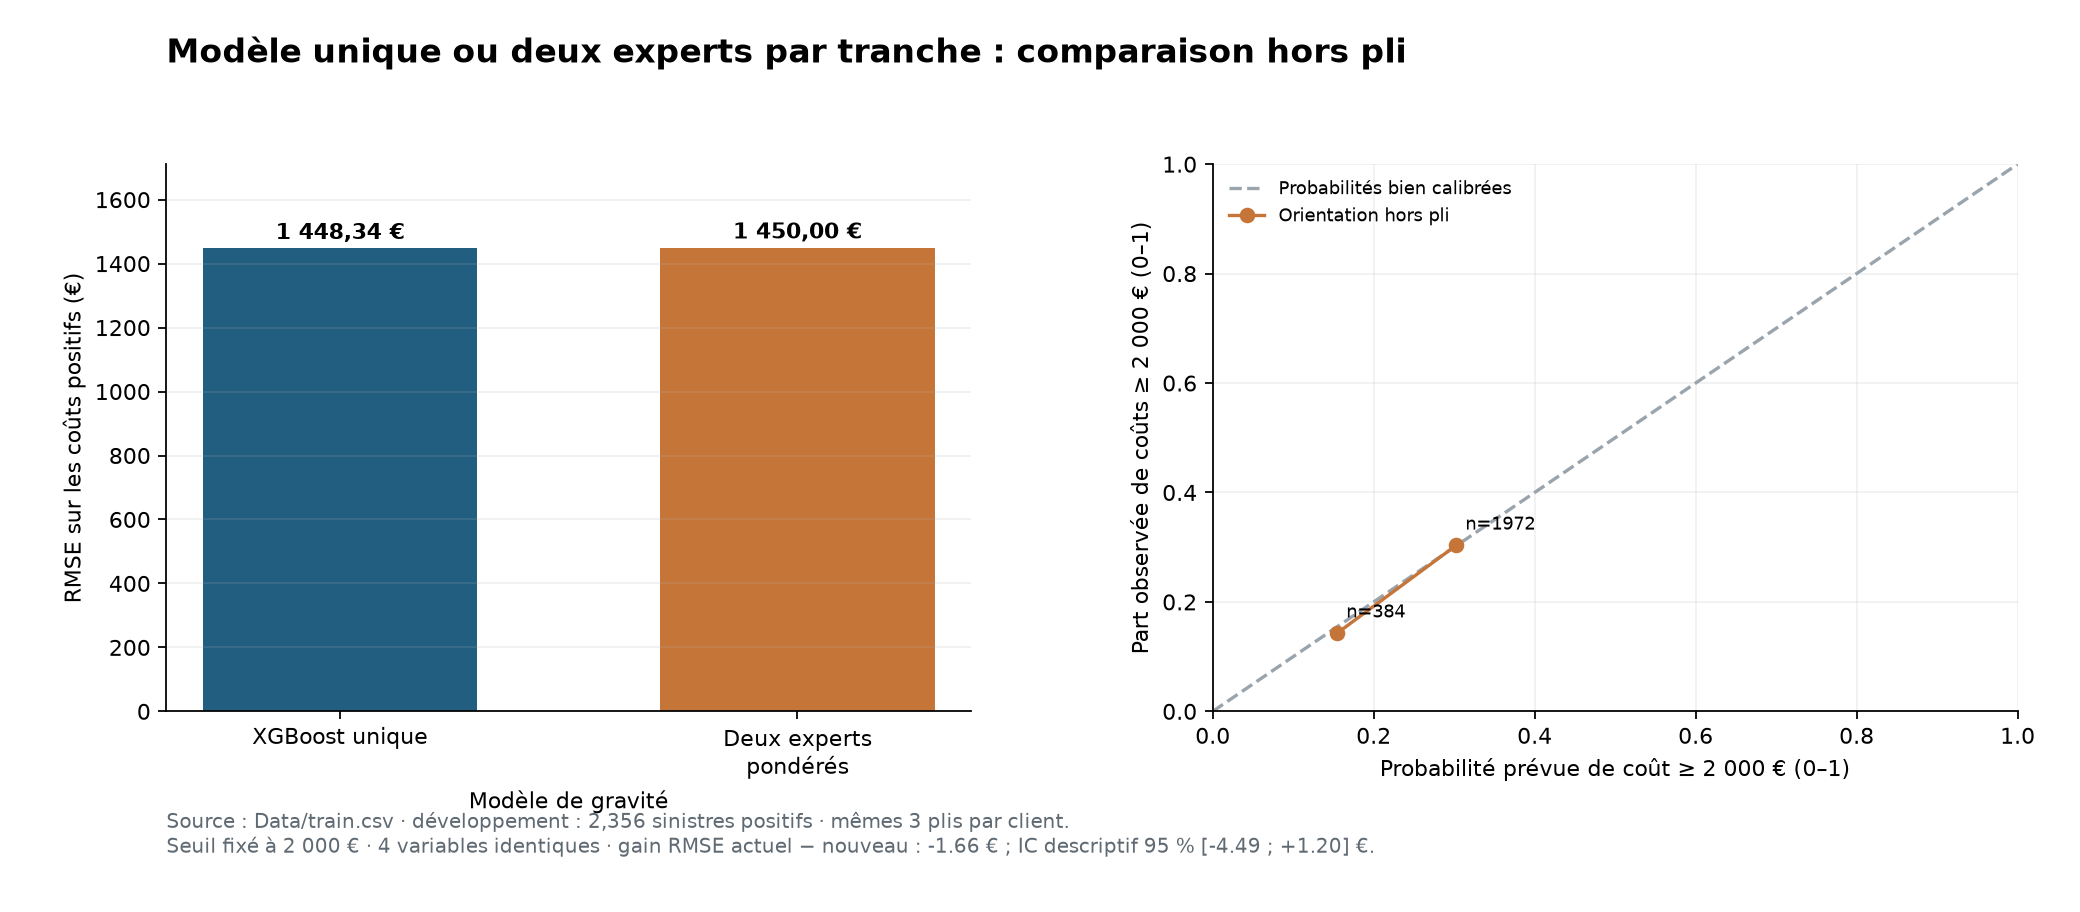

**Comparaison :** RMSE actuel **1,448.34 €** ; deux experts **1,450.00 €**. Gain actuel − nouveau : **-1.66 €**, intervalle descriptif 95 % [-4.49 ; +1.20] €. **Décision :** Le système à deux experts dégrade le RMSE global ; conserver le XGBoost unique actuel.

In [4]:
t_unique,t_inverse=np.unique(groups,return_inverse=True)
t_nclient=np.bincount(t_inverse)
t_se_current=np.bincount(t_inverse,weights=(y-t_baseline_oof)**2)
t_se_mixture=np.bincount(t_inverse,weights=(y-t_mixture_oof)**2)
t_rng=np.random.default_rng(202613); t_bootstrap=[]
for _ in range(1000):
    ii=t_rng.integers(0,len(t_unique),len(t_unique))
    t_bootstrap.append(float(np.sqrt(t_se_current[ii].sum()/t_nclient[ii].sum())-
                             np.sqrt(t_se_mixture[ii].sum()/t_nclient[ii].sum())))
t_ci=np.quantile(t_bootstrap,[.025,.975])
t_gain=rmse(y,t_baseline_oof)-rmse(y,t_mixture_oof)
t_uncertainty={'rmse_current':rmse(y,t_baseline_oof),'rmse_two_experts':rmse(y,t_mixture_oof),
    'gain_rmse_current_minus_two_experts':t_gain,'ci95_low':float(t_ci[0]),'ci95_high':float(t_ci[1]),
    'bootstrap_replicates':1000,'bootstrap_unit':'client','n_evaluation':len(y),'n_clients':len(t_unique),
    'holdout_evaluated':False,'development_previously_explored':True,
    'threshold_searched':False,'hyperparameters_searched':False}
(TR/'incertitude.json').write_text(json.dumps(t_uncertainty,indent=2,ensure_ascii=False))
t_labels=(y>=t_threshold).astype(int)
t_gate_metrics={'auc':float(roc_auc_score(t_labels,t_probability)),
    'brier_orientation':float(brier_score_loss(t_labels,t_probability)),
    'brier_proportion_constante':float(brier_score_loss(t_labels,t_prior)),
    'logloss_orientation':float(log_loss(t_labels,t_probability)),
    'logloss_proportion_constante':float(log_loss(t_labels,t_prior)),
    'accuracy_seuil_0.5':float(accuracy_score(t_labels,t_probability>=.5)),
    'accuracy_classe_majoritaire':float(accuracy_score(t_labels,t_prior>=.5)),
    'moyenne_probabilite_grand':float(t_probability.mean()),'proportion_grands_observee':float(t_labels.mean()),
    'n_expert_petit_borne':int(t_small_bounded.sum()),'n_expert_grand_borne':int(t_large_bounded.sum())}
(TR/'diagnostic_orientation.json').write_text(json.dumps(t_gate_metrics,indent=2,ensure_ascii=False))
t_band_rows=[]
for label,mask in [('cout_<2000',y<t_threshold),('cout_>=2000',y>=t_threshold)]:
    for model,pred in [('XGBoost_unique_actuel',t_baseline_oof),('Deux_experts_orientation_probabiliste',t_mixture_oof)]:
        t_band_rows.append({'tranche_reelle_diagnostic':label,'modele':model,'n_validation':int(mask.sum()),**scores(y[mask],pred[mask])})
pd.DataFrame(t_band_rows).to_csv(TR/'diagnostic_par_tranche.csv',index=False)
t_calibration=pd.DataFrame({'probabilite':t_probability,'tranche_grande':t_labels})
t_calibration['groupe']=pd.cut(t_calibration.probabilite,np.linspace(0,1,6),include_lowest=True)
t_calibration=t_calibration.groupby('groupe',observed=True).agg(
    n=('tranche_grande','size'),probabilite_moyenne=('probabilite','mean'),
    proportion_grands_observee=('tranche_grande','mean')).reset_index()
t_calibration.to_csv(TR/'calibration_orientation.csv',index=False)
display(pd.DataFrame([t_uncertainty])); display(pd.DataFrame([t_gate_metrics])); display(pd.DataFrame(t_band_rows))
fig,axes=plt.subplots(1,2,figsize=(13,5.7))
fig.subplots_adjust(top=.82,bottom=.22,left=.08,right=.97,wspace=.30)
fig.suptitle('Modèle unique ou deux experts par tranche : comparaison hors pli',x=.08,y=.96,ha='left',fontsize=15,fontweight='bold')
ax=axes[0]
bars=ax.bar(['XGBoost unique','Deux experts\npondérés'],t_comparison.rmse,color=['#215e80','#c67538'],width=.60)
ax.set(ylabel='RMSE sur les coûts positifs (€)',xlabel='Modèle de gravité',ylim=(0,float(t_comparison.rmse.max())*1.18))
ax.xaxis.grid(False)
for b,v in zip(bars,t_comparison.rmse):
    ax.text(b.get_x()+b.get_width()/2,v+12,f'{v:,.2f} €'.replace(',',' ').replace('.',','),ha='center',va='bottom',fontweight='bold')
ax=axes[1]
ax.plot([0,1],[0,1],linestyle='--',color='#9aa4ad',label='Probabilités bien calibrées')
ax.plot(t_calibration.probabilite_moyenne,t_calibration.proportion_grands_observee,'o-',color='#c67538',label='Orientation hors pli')
for row in t_calibration.itertuples():
    ax.annotate(f'n={row.n}',(row.probabilite_moyenne,row.proportion_grands_observee),xytext=(4,7),textcoords='offset points',fontsize=8)
ax.set(xlabel='Probabilité prévue de coût ≥ 2 000 € (0–1)',ylabel='Part observée de coûts ≥ 2 000 € (0–1)',xlim=(0,1),ylim=(0,1))
ax.legend(frameon=False,fontsize=8,loc='upper left')
fig.text(.08,.065,f'Source : Data/train.csv · développement : {len(y):,} sinistres positifs · mêmes 3 plis par client.\n'
         f'Seuil fixé à 2 000 € · 4 variables identiques · gain RMSE actuel − nouveau : {t_gain:+.2f} € ; IC descriptif 95 % [{t_ci[0]:+.2f} ; {t_ci[1]:+.2f}] €.',fontsize=9,color='#606a73')
fig.savefig(TR/'comparaison_deux_experts.png',dpi=160,facecolor='white')
display(Image(filename=str(TR/'comparaison_deux_experts.png'))); plt.close(fig)
if t_gain<=0:
    t_conclusion='Le système à deux experts dégrade le RMSE global ; conserver le XGBoost unique actuel.'
elif t_ci[0]<=0:
    t_conclusion='Le système à deux experts améliore le RMSE mesuré, mais le gain reste incertain ; conserver la référence actuelle à ce stade.'
else:
    t_conclusion='Le système à deux experts améliore le RMSE avec un intervalle descriptif positif ; ce candidat mérite une confirmation sur des données externes neuves.'
note(f'**Comparaison :** RMSE actuel **{rmse(y,t_baseline_oof):,.2f} €** ; deux experts **{rmse(y,t_mixture_oof):,.2f} €**. '
     f'Gain actuel − nouveau : **{t_gain:+,.2f} €**, intervalle descriptif 95 % [{t_ci[0]:+,.2f} ; {t_ci[1]:+,.2f}] €. '
     f'**Décision :** {t_conclusion}')


### 13.2 Sauvegarde du candidat et conservation du modèle actuel

Le candidat à deux tranches est réentraîné sur tous les 2 917 coûts positifs et sauvegardé séparément pour permettre sa reproduction. Ses prédictions sur les 50 000 contrats du test sont des coûts conditionnels à l'existence d'un sinistre, sans probabilité de fréquence.

Les prédictions sont vérifiées après rechargement, ainsi que leur invariance à des modifications des cibles dans les données de prédiction et de la population communale. L'empreinte du fichier du modèle actuel est contrôlée : il n'est pas remplacé par cette comparaison.

In [5]:
t_positive=train.loc[train.montant_sinistre.gt(0)].copy()
with threadpool_limits(limits=2):
    t_final=TwoBandSeverityEstimator(t_threshold,t_cfg['spec'],t_cfg['params']).fit(
        t_positive[FEATURES],t_positive[TARGET])
t_predictions=t_final.predict(test[FEATURES])
assert len(t_predictions)==len(test) and np.isfinite(t_predictions).all() and (t_predictions>0).all()
t_path=MODELS/'gravite_deux_tranches.joblib'; joblib.dump(t_final,t_path)
t_loaded=joblib.load(t_path)
np.testing.assert_allclose(t_loaded.predict(test[FEATURES]),t_predictions,rtol=0,atol=1e-8)
t_probe=test[FEATURES].head(100).copy()
t_probe[TARGET]=-1.e9; t_probe['nombre_sinistres']=999
np.testing.assert_array_equal(t_loaded.predict(t_probe),t_predictions[:100])
t_changed=copy.deepcopy(t_loaded)
for features in [t_changed.gate_.named_steps['qualitative'],
                 *[e.pipeline_.named_steps['qualitative'] for e in t_changed.experts_]]:
    features.geo_.reference_['population_2018']=1.e9
np.testing.assert_array_equal(t_changed.predict(test[FEATURES].head(100)),t_predictions[:100])
assert hashlib.sha256(t_baseline_path.read_bytes()).hexdigest()==t_baseline_sha
pd.DataFrame({'index':test['index'].to_numpy(),'gravite_predite':t_predictions}).to_csv(TR/'gravite_test.csv',index=False)
t_manifest={'target':'montant_sinistre conditionnellement positif','threshold':t_threshold,
    'bands':['0 < cout < 2000','cout >= 2000'],
    'current_model_path':str(t_baseline_path.relative_to(HERE)),'current_model_sha256':t_baseline_sha,
    'current_model_unchanged':True,'candidate_model_path':str(t_path.relative_to(HERE)),
    'features':t_final.feature_columns_,'spec':t_cfg['spec'],'expert_params':t_cfg['params'],
    'gate_params':t_cfg['params'],'expert_objective':'reg:gamma','gate_objective':'binary:logistic',
    'mixing':'(1 - probabilite_grand) * cout_expert_petit + probabilite_grand * cout_expert_grand',
    'expert_predictions_bounded_to_their_band':True,'model_selection_on_validation':False,
    'training_rows':len(t_positive),'training_band_counts':t_final.training_counts_,
    'n_test_predictions':len(t_predictions),'test_reload_equal':True,
    'prediction_target_invariance_verified':True,'population_invariance_verified':True,
    'comparison':t_comparison.to_dict(orient='records'),'validation':t_uncertainty,
    'gate_diagnostics':t_gate_metrics,'conclusion':t_conclusion,
    'holdout_evaluated':False,'frequency_model_trained':False,'frequency_encodings_used':False,
    'versions':VERSIONS,'source_sha256':hashlib.sha256((HERE/'gravite_tranches.py').read_bytes()).hexdigest()}
(TR/'manifest.json').write_text(json.dumps(t_manifest,indent=2,ensure_ascii=False))
print('Candidat sauvegardé séparément :',t_path.name)
print('Effectifs réentraînés par tranche :',t_final.training_counts_)
print('50 000 prédictions vérifiées après rechargement ; modèle actuel inchangé.')


Candidat sauvegardé séparément : gravite_deux_tranches.joblib
Effectifs réentraînés par tranche : [2110, 807]
50 000 prédictions vérifiées après rechargement ; modèle actuel inchangé.


**Conclusion de l’essai à deux tranches :** sur les mêmes 2 356 sinistres de validation et les mêmes trois plis par client, le RMSE passe de **1 448,34 €** pour le XGBoost Gamma unique à **1 450,00 €** pour le système à deux experts. La MAE passe de **924,34 €** à **927,12 €**. L’écart RMSE après − avant est de **+1,66 €** : l’essai n’améliore pas le score. Le gain inverse actuel − nouveau a un intervalle descriptif bootstrap à 95 % de **[−4,49 ; +1,20] €**, qui ne démontre pas de gain stable.

L’orientation distingue peu les tranches (**AUC = 0,586**) ; elle améliore légèrement le Brier et la perte logarithmique par rapport à une proportion constante, mais cela ne se traduit pas en amélioration du coût moyen prédit. Les bornes des experts ne modifient aucune prédiction hors pli dans cet essai. **On conserve le modèle actuel à quatre variables.** Le nouveau candidat reste sauvegardé séparément à titre de comparaison. Cette conclusion porte sur la recette testée, sans exclure toute autre approche de segmentation et sans prétendre à une validation externe neuve.

## 14. Modèle à deux tranches : apprentissage 90 % et validation 10 %

**Demande :** essayer le nouveau système à deux experts avec une répartition 90 % apprentissage / 10 % validation. Le périmètre reste la gravité : on repart des **2 917 montants strictement positifs de tout train.csv**, en excluant les montants nuls.

**Découpage préfixé :** `GroupShuffleSplit(test_size=0.10, random_state=2026)` sur `id_client`. Les 90/10 portent sur les clients, afin que les contrats d'un même client restent ensemble ; les proportions de lignes peuvent légèrement différer de 90/10. On utilise le premier et unique tirage, sans choisir une graine selon le résultat.

On conserve les quatre variables, le seuil à 2 000 €, les deux experts Gamma et l'orientation probabiliste du §13, ainsi que tous les réglages. Les modèles ne voient que le sous-train de 90 % lors de leur ajustement, y compris pour les médianes et les regroupements de catégories. Les probabilités d'orientation de la validation sont obtenues sans connaître ses montants réels.

Pour comparer correctement, le XGBoost unique à quatre variables est lui aussi **réentraîné sur les mêmes 90 %** et évalué sur les mêmes 10 %. Ce nouveau score à un seul découpage ne se compare pas directement au RMSE de validation croisée du §13. Ce redécoupage réutilise des données déjà explorées, y compris une partie des anciens jeux réservés : il ne constitue pas une cohorte externe neuve. Aucun nouveau réglage n'est choisi sur les 10 %.

Les modèles issus de cette expérience restent ajustés sur les seuls 90 % et sont sauvegardés séparément. Les modèles précédemment retenus et leurs prédictions restent inchangés.

In [3]:
from gravite_tranches import TwoBandSeverityEstimator
from qualitative_features import QualitativeSeverityEstimator
from sklearn.metrics import roc_auc_score,brier_score_loss
import copy
R90=REPORTS/'tranches_90_10'; R90.mkdir(exist_ok=True)
s90_previous=json.loads((REPORTS/'modele_tranches/manifest.json').read_text())
s90_spec=copy.deepcopy(s90_previous['spec']); s90_params=copy.deepcopy(s90_previous['expert_params'])
s90_threshold=float(s90_previous['threshold'])
s90_positive=train.loc[train[TARGET].gt(0)].copy().reset_index(drop=True)
assert len(s90_positive)==2917 and s90_positive[TARGET].gt(0).all()
s90_split=GroupShuffleSplit(n_splits=1,test_size=.10,random_state=2026)
s90_tr,s90_va=next(s90_split.split(s90_positive,groups=s90_positive.id_client))
s90_train=s90_positive.iloc[s90_tr].copy(); s90_validation=s90_positive.iloc[s90_va].copy()
assert len(s90_train)+len(s90_validation)==len(s90_positive)
assert not set(s90_train.id_client) & set(s90_validation.id_client)
assert not set(s90_train['index']) & set(s90_validation['index'])
s90_xtr=s90_train[FEATURES]; s90_ytr=s90_train[TARGET].to_numpy()
s90_xva=s90_validation[FEATURES]; s90_yva=s90_validation[TARGET].to_numpy()
s90_roles=s90_positive[['index','id_client']].copy()
s90_roles['role']=np.where(s90_roles.index.isin(s90_tr),'apprentissage_90','validation_10')
s90_roles.to_csv(R90/'decoupage_clients.csv',index=False)
s90_split_table=pd.DataFrame([{'jeu':name,'contrats_sinistres':len(frame),'clients':frame.id_client.nunique(),
    'part_lignes_pct':100*len(frame)/len(s90_positive),
    'part_clients_pct':100*frame.id_client.nunique()/s90_positive.id_client.nunique(),
    'cout_inferieur_2000':int(frame[TARGET].lt(s90_threshold).sum()),
    'cout_superieur_egal_2000':int(frame[TARGET].ge(s90_threshold).sum())}
    for name,frame in [('apprentissage_90',s90_train),('validation_10',s90_validation)]])
s90_split_table.to_csv(R90/'effectifs.csv',index=False)
s90_parent_paths=[HERE/s90_previous['current_model_path'],HERE/s90_previous['candidate_model_path']]
s90_parent_hashes={str(path.relative_to(HERE)):hashlib.sha256(path.read_bytes()).hexdigest() for path in s90_parent_paths}
with threadpool_limits(limits=2):
    s90_unique=QualitativeSeverityEstimator(s90_spec,s90_params,'reg:gamma').fit(s90_xtr,s90_ytr)
    s90_mixture=TwoBandSeverityEstimator(s90_threshold,s90_spec,s90_params).fit(s90_xtr,s90_ytr)
assert s90_unique.feature_columns_==s90_mixture.feature_columns_==s90_previous['features']
assert sum(s90_mixture.training_counts_)==len(s90_train)
s90_results=[]; s90_predictions={}
for label,model in [('XGBoost_unique',s90_unique),('Deux_experts',s90_mixture)]:
    s90_predictions[label]=model.predict(s90_xva)
    for role,xx,yy in [('apprentissage_90',s90_xtr,s90_ytr),('validation_10',s90_xva,s90_yva)]:
        pp=model.predict(xx)
        s90_results.append({'modele':label,'jeu':role,'n_sinistres':len(yy),**scores(yy,pp)})
s90_results=pd.DataFrame(s90_results)
s90_results.to_csv(R90/'scores_apprentissage_validation.csv',index=False)
s90_components=s90_mixture.predict_components(s90_xva)
s90_out=pd.DataFrame({'index':s90_validation['index'].to_numpy(),'id_client':s90_validation.id_client.to_numpy(),
    'montant_observe':s90_yva,'prediction_unique':s90_predictions['XGBoost_unique'],
    'prediction_deux_experts':s90_predictions['Deux_experts'],
    'probabilite_grand':s90_components.probabilite_grand.to_numpy(),
    'cout_expert_petit':s90_components.cout_petit.to_numpy(),
    'cout_expert_grand':s90_components.cout_grand.to_numpy()})
s90_out.to_csv(R90/'predictions_validation.csv',index=False)
s90_rmse_unique=rmse(s90_yva,s90_predictions['XGBoost_unique'])
s90_rmse_mixture=rmse(s90_yva,s90_predictions['Deux_experts'])
s90_difference=s90_rmse_mixture-s90_rmse_unique
s90_gate={'auc':float(roc_auc_score(s90_yva>=s90_threshold,s90_components.probabilite_grand)),
    'brier':float(brier_score_loss(s90_yva>=s90_threshold,s90_components.probabilite_grand))}
display(s90_split_table)
display(s90_results[['modele','jeu','n_sinistres','rmse','mae','ratio_predit_observe']])
print(f'90/10 : {len(s90_train)} sinistres apprentissage ; {len(s90_validation)} validation.',flush=True)
print(f'RMSE validation deux experts : {s90_rmse_mixture:.6f} euros ; unique sur le meme decoupage : {s90_rmse_unique:.6f} euros.',flush=True)


,jeu,contrats_sinistres,clients,part_lignes_pct,part_clients_pct,cout_inferieur_2000,cout_superieur_egal_2000
0,apprentissage_90,2625,2606,89.990,89.986,1888,737
1,validation_10,292,290,10.010,10.014,222,70


,modele,jeu,n_sinistres,rmse,mae,ratio_predit_observe
0,XGBoost_unique,apprentissage_90,2625,"1,464.604",930.686,0.997
1,XGBoost_unique,validation_10,292,"1,227.982",870.855,1.059
2,Deux_experts,apprentissage_90,2625,"1,466.891",931.147,0.998
3,Deux_experts,validation_10,292,"1,226.013",868.661,1.058


90/10 : 2625 sinistres apprentissage ; 292 validation.


RMSE validation deux experts : 1226.012687 euros ; unique sur le meme decoupage : 1227.981542 euros.


In [4]:
s90_model_paths={}
for label,model in [('unique',s90_unique),('deux_experts',s90_mixture)]:
    path=MODELS/f'gravite_{label}_train90.joblib'
    joblib.dump(model,path)
    loaded=joblib.load(path)
    np.testing.assert_allclose(loaded.predict(s90_xva),model.predict(s90_xva),rtol=0,atol=1e-8)
    s90_model_paths[label]=str(path.relative_to(HERE))
s90_test=s90_mixture.predict(test[FEATURES])
assert len(s90_test)==len(test) and np.isfinite(s90_test).all() and (s90_test>0).all()
pd.DataFrame({'index':test['index'].to_numpy(),'gravite_predite':s90_test}).to_csv(R90/'gravite_test_train90.csv',index=False)
for path in s90_parent_paths:
    assert hashlib.sha256(path.read_bytes()).hexdigest()==s90_parent_hashes[str(path.relative_to(HERE))]
s90_manifest={'target':'montant_sinistre conditionnellement positif',
    'sample_scope':'tous les montants strictement positifs de train.csv',
    'split_method':'GroupShuffleSplit','random_state':2026,'test_size_clients':.10,
    'n_positive':len(s90_positive),'n_training':len(s90_train),'n_validation':len(s90_validation),
    'training_clients':s90_train.id_client.nunique(),'validation_clients':s90_validation.id_client.nunique(),
    'actual_training_row_percent':100*len(s90_train)/len(s90_positive),
    'actual_validation_row_percent':100*len(s90_validation)/len(s90_positive),
    'client_overlap':False,'threshold':s90_threshold,'features':s90_mixture.feature_columns_,
    'spec':s90_spec,'expert_params':s90_params,'gate_params':s90_params,
    'scores':s90_results.to_dict(orient='records'),
    'validation_rmse_two_experts':s90_rmse_mixture,'validation_rmse_single':s90_rmse_unique,
    'validation_difference_two_experts_minus_single':s90_difference,'gate_diagnostics':s90_gate,
    'models_fitted_on_90_percent_only':True,'model_paths':s90_model_paths,
    'model_reload_verified':True,'n_test_predictions':len(s90_test),
    'previous_models_unchanged':True,'previous_model_sha256':s90_parent_hashes,
    'hyperparameters_searched':False,'split_chosen_from_multiple_attempts':False,
    'previously_explored_data':True,'reuses_some_previous_holdout_rows':True,
    'frequency_model_trained':False,'frequency_encodings_used':False,'versions':VERSIONS}
(R90/'manifest.json').write_text(json.dumps(s90_manifest,indent=2,ensure_ascii=False))
note(f'**Nouveau découpage :** {len(s90_train):,} sinistres pour l’apprentissage '
     f'({100*len(s90_train)/len(s90_positive):.2f} % des lignes), {len(s90_validation):,} pour la validation '
     f'({100*len(s90_validation)/len(s90_positive):.2f} %). Aucun client commun. '
     f'**RMSE de validation du modèle à deux experts : {s90_rmse_mixture:,.2f} €**. '
     f'Le XGBoost unique réentraîné sur les mêmes 90 % obtient **{s90_rmse_unique:,.2f} €** '
     f'(écart deux experts − unique : {s90_difference:+,.2f} €). '
     'Les modèles de cette section restent ajustés sur les 90 % seulement, sans réentraînement sur la validation. '
     'Les versions antérieures sont conservées. Un score sur ce nouveau découpage ne remplace pas les résultats de validation croisée précédents.')


**Nouveau découpage :** 2,625 sinistres pour l’apprentissage (89.99 % des lignes), 292 pour la validation (10.01 %). Aucun client commun. **RMSE de validation du modèle à deux experts : 1,226.01 €**. Le XGBoost unique réentraîné sur les mêmes 90 % obtient **1,227.98 €** (écart deux experts − unique : -1.97 €). Les modèles de cette section restent ajustés sur les 90 % seulement, sans réentraînement sur la validation. Les versions antérieures sont conservées. Un score sur ce nouveau découpage ne remplace pas les résultats de validation croisée précédents.

**Résultat du découpage 90/10 :** le modèle à deux tranches est ajusté sur **2 625 sinistres (89,99 %)** et évalué sur **292 sinistres (10,01 %)**, sans client commun. Son **RMSE de validation est de 1 226,01 €**, pour une **MAE de 868,66 €**. Sur les mêmes données, le XGBoost unique obtient un RMSE de **1 227,98 €** : le gain des deux experts est de **1,97 €**, faible sur ce seul découpage. Les scores d’apprentissage sont respectivement de 1 466,89 € et 1 464,60 €.

Ces résultats ne sont pas directement comparables aux anciens RMSE de validation croisée, car les contrats de validation et les tailles d’apprentissage diffèrent. Les deux nouvelles versions restent entraînées sur les seuls 90 %, avec sauvegarde séparée ; aucune version antérieure n’a été remplacée.

## 15. Trois tranches sur le même découpage 90/10

**Demande :** tester trois tranches après l'essai à deux tranches. Les seuils fixés avant le calcul sont **1 500 €** et **3 000 €** :

- tranche 1 : montant strictement positif et inférieur à 1 500 € ;
- tranche 2 : montant supérieur ou égal à 1 500 € et inférieur à 3 000 € ;
- tranche 3 : montant supérieur ou égal à 3 000 €.

On reprend **exactement les rôles enregistrés au §14** : 2 625 sinistres d'apprentissage et les mêmes 292 sinistres de validation, avec séparation des clients. Il n'y a aucun nouveau tirage. Les quatre variables et les réglages des experts Gamma sont inchangés.

Un XGBoost multiclasses (`multi:softprob`) apprend les trois probabilités à partir des caractéristiques disponibles chez les sinistrés. Chaque expert Gamma apprend sa tranche sur les seules données d'apprentissage. La prédiction finale est la somme des trois coûts conditionnels pondérés par leurs probabilités, **sans utiliser la tranche réelle de validation**. Les moyennes conditionnelles des experts sont bornées à leur tranche. Chaque composant apprend ses médianes et encodages sur son seul sous-train ; les classes ne sont pas rééquilibrées.

Les réglages de complexité du modèle d'orientation restent identiques (400 tours, profondeur 1, même régularisation). En multiclasses, XGBoost produit un arbre par classe et par tour : l'orientation à trois tranches comporte donc davantage d'arbres que l'orientation binaire. Il ne s'agit pas d'un budget total d'arbres identique. Aucun seuil ou paramètre n'est optimisé sur la validation.

Les modèles unique et à deux tranches ajustés sur les 90 % au §14 sont rechargés. On vérifie que leurs prédictions reproduisent le rapport précédent avant de les comparer au nouvel essai. Les trois systèmes sont mesurés sur les mêmes contrats et montants. Cette validation a déjà servi à plusieurs comparaisons : les résultats sont exploratoires et ne remplacent pas une validation externe neuve. Les modèles antérieurs ne sont pas remplacés.

In [3]:
from gravite_trois_tranches import ThreeBandSeverityEstimator
from sklearn.metrics import log_loss,accuracy_score
import copy
R3=REPORTS/'trois_tranches_90_10'; R3.mkdir(exist_ok=True)
r3_parent=json.loads((REPORTS/'tranches_90_10/manifest.json').read_text())
r3_split_path=REPORTS/'tranches_90_10/decoupage_clients.csv'
r3_roles=pd.read_csv(r3_split_path)
r3_source=train.set_index('index',drop=False)
r3_train_ids=r3_roles.loc[r3_roles.role.eq('apprentissage_90'),'index']
r3_val_ids=r3_roles.loc[r3_roles.role.eq('validation_10'),'index']
r3_train=r3_source.loc[r3_train_ids].copy().reset_index(drop=True)
r3_validation=r3_source.loc[r3_val_ids].copy().reset_index(drop=True)
assert len(r3_train)==2625 and len(r3_validation)==292
assert not set(r3_train.id_client)&set(r3_validation.id_client)
assert r3_train[TARGET].gt(0).all() and r3_validation[TARGET].gt(0).all()
(R3/'decoupage_clients.csv').write_bytes(r3_split_path.read_bytes())
r3_xtr=r3_train[FEATURES]; r3_ytr=r3_train[TARGET].to_numpy()
r3_xva=r3_validation[FEATURES]; r3_yva=r3_validation[TARGET].to_numpy()
r3_cuts=(1500.,3000.)
r3_spec=copy.deepcopy(r3_parent['spec']); r3_params=copy.deepcopy(r3_parent['expert_params'])
r3_old_paths=[HERE/p for p in r3_parent['model_paths'].values()]
r3_old_hash={str(p.relative_to(HERE)):hashlib.sha256(p.read_bytes()).hexdigest() for p in r3_old_paths}
r3_models={'XGBoost_unique':joblib.load(HERE/r3_parent['model_paths']['unique']),
           'Deux_experts':joblib.load(HERE/r3_parent['model_paths']['deux_experts'])}
r3_old_predictions=pd.read_csv(REPORTS/'tranches_90_10/predictions_validation.csv')
np.testing.assert_array_equal(r3_validation['index'],r3_old_predictions['index'])
np.testing.assert_allclose(r3_models['XGBoost_unique'].predict(r3_xva),r3_old_predictions.prediction_unique,rtol=0,atol=1e-8)
np.testing.assert_allclose(r3_models['Deux_experts'].predict(r3_xva),r3_old_predictions.prediction_deux_experts,rtol=0,atol=1e-8)
with threadpool_limits(limits=2):
    r3_new=ThreeBandSeverityEstimator(r3_cuts,r3_spec,r3_params).fit(r3_xtr,r3_ytr)
assert sum(r3_new.training_counts_)==len(r3_train)
assert r3_new.feature_columns_==r3_parent['features']
r3_models['Trois_experts']=r3_new
r3_rows=[]; r3_preds={}
for label,model in r3_models.items():
    r3_preds[label]=model.predict(r3_xva)
    for role,xx,yy in [('apprentissage_90',r3_xtr,r3_ytr),('validation_10',r3_xva,r3_yva)]:
        r3_rows.append({'modele':label,'jeu':role,'n_sinistres':len(yy),**scores(yy,model.predict(xx))})
r3_scores=pd.DataFrame(r3_rows)
r3_scores.to_csv(R3/'scores_apprentissage_validation.csv',index=False)
r3_effectifs=[]
for label,frame in [('apprentissage_90',r3_train),('validation_10',r3_validation)]:
    labels=np.searchsorted(r3_cuts,frame[TARGET].to_numpy(),side='right')
    for k,desc in enumerate(['0 < cout < 1500','1500 <= cout < 3000','cout >= 3000']):
        r3_effectifs.append({'jeu':label,'tranche':desc,'effectif':int((labels==k).sum())})
r3_effectifs=pd.DataFrame(r3_effectifs); r3_effectifs.to_csv(R3/'effectifs_par_tranche.csv',index=False)
r3_components=r3_new.predict_components(r3_xva)
r3_prob_cols=[f'probabilite_tranche_{i}' for i in (1,2,3)]
r3_prob=r3_components[r3_prob_cols].to_numpy()
np.testing.assert_allclose(r3_prob.sum(axis=1),1.,rtol=0,atol=1e-12)
r3_labels=np.searchsorted(r3_cuts,r3_yva,side='right')
r3_gate={'logloss':float(log_loss(r3_labels,r3_prob,labels=[0,1,2])),
    'logloss_proportions_constantes_train':float(log_loss(r3_labels,np.tile(r3_new.band_priors_,(len(r3_yva),1)),labels=[0,1,2])),
    'accuracy':float(accuracy_score(r3_labels,np.argmax(r3_prob,axis=1))),
    'accuracy_classe_majoritaire_train':float(accuracy_score(r3_labels,np.full(len(r3_yva),np.argmax(r3_new.band_priors_)))),
    'brier_multiclasse_somme_classes':float(np.mean(np.sum((r3_prob-np.eye(3)[r3_labels])**2,axis=1))),
    'n_experts_bornes':[int(r3_components[f'expert_{i}_borne'].sum()) for i in (1,2,3)]}
r3_out=pd.DataFrame({'index':r3_validation['index'].to_numpy(),'id_client':r3_validation.id_client.to_numpy(),
    'montant_observe':r3_yva,**{'prediction_'+k:v for k,v in r3_preds.items()}})
for col in r3_components:
    r3_out[col]=r3_components[col].to_numpy()
r3_out.to_csv(R3/'predictions_validation.csv',index=False)
r3_validation_scores=r3_scores.loc[r3_scores.jeu.eq('validation_10')].copy()
r3_rmse3=rmse(r3_yva,r3_preds['Trois_experts'])
r3_rmse2=rmse(r3_yva,r3_preds['Deux_experts'])
r3_rmse1=rmse(r3_yva,r3_preds['XGBoost_unique'])
display(r3_effectifs); display(r3_scores[['modele','jeu','n_sinistres','rmse','mae','ratio_predit_observe']])
print(f'RMSE validation : unique {r3_rmse1:.6f} ; deux tranches {r3_rmse2:.6f} ; trois tranches {r3_rmse3:.6f} euros.',flush=True)


,jeu,tranche,effectif
0,apprentissage_90,0 < cout < 1500,1617
1,apprentissage_90,1500 <= cout < 3000,683
2,apprentissage_90,cout >= 3000,325
3,validation_10,0 < cout < 1500,195
4,validation_10,1500 <= cout < 3000,61
5,validation_10,cout >= 3000,36


,modele,jeu,n_sinistres,rmse,mae,ratio_predit_observe
0,XGBoost_unique,apprentissage_90,2625,"1,464.604",930.686,0.997
1,XGBoost_unique,validation_10,292,"1,227.982",870.855,1.059
2,Deux_experts,apprentissage_90,2625,"1,466.891",931.147,0.998
3,Deux_experts,validation_10,292,"1,226.013",868.661,1.058
4,Trois_experts,apprentissage_90,2625,"1,467.842",929.937,0.999
5,Trois_experts,validation_10,292,"1,226.368",864.236,1.057


RMSE validation : unique 1227.981542 ; deux tranches 1226.012687 ; trois tranches 1226.368400 euros.


In [4]:
r3_path=MODELS/'gravite_trois_tranches_train90.joblib'
joblib.dump(r3_new,r3_path)
r3_loaded=joblib.load(r3_path)
np.testing.assert_allclose(r3_loaded.predict(r3_xva),r3_preds['Trois_experts'],rtol=0,atol=1e-8)
r3_probe=r3_xva.copy(); r3_probe[TARGET]=-1.e9; r3_probe['nombre_sinistres']=999
np.testing.assert_array_equal(r3_loaded.predict(r3_probe),r3_preds['Trois_experts'])
r3_changed=copy.deepcopy(r3_loaded)
for f in [r3_changed.gate_.named_steps['qualitative'],*[e.pipeline_.named_steps['qualitative'] for e in r3_changed.experts_]]:
    f.geo_.reference_['population_2018']=1.e9
np.testing.assert_array_equal(r3_changed.predict(r3_xva),r3_preds['Trois_experts'])
r3_test=r3_loaded.predict(test[FEATURES])
assert len(r3_test)==len(test) and np.isfinite(r3_test).all() and (r3_test>0).all()
pd.DataFrame({'index':test['index'].to_numpy(),'gravite_predite':r3_test}).to_csv(R3/'gravite_test_train90.csv',index=False)
for p in r3_old_paths:
    assert hashlib.sha256(p.read_bytes()).hexdigest()==r3_old_hash[str(p.relative_to(HERE))]
r3_difference=r3_rmse3-r3_rmse2
r3_conclusion=('Trois tranches améliorent le RMSE mesuré face à deux sur ce découpage ; ce résultat exploratoire doit être confirmé.'
    if r3_difference<0 else 'Trois tranches n’améliorent pas le RMSE face à deux sur ce découpage ; conserver les versions précédentes.')
r3_manifest={'target':'montant_sinistre conditionnellement positif','thresholds':list(r3_cuts),
    'bands':['0 < cout < 1500','1500 <= cout < 3000','cout >= 3000'],
    'split_source':'reports/tranches_90_10/decoupage_clients.csv',
    'split_sha256':hashlib.sha256(r3_split_path.read_bytes()).hexdigest(),
    'n_training':len(r3_train),'n_validation':len(r3_validation),'client_overlap':False,
    'features':r3_new.feature_columns_,'spec':r3_spec,'expert_params':r3_params,'gate_params':r3_params,
    'expert_objective':'reg:gamma','gate_objective':'multi:softprob','n_gate_classes':3,
    'multiclass_gate_trees_per_boosting_round':3,'class_rebalancing':False,
    'training_band_counts':r3_new.training_counts_,
    'validation_band_counts':np.bincount(r3_labels,minlength=3).tolist(),
    'scores':r3_scores.to_dict(orient='records'),'gate_diagnostics':r3_gate,
    'rmse_validation_single':r3_rmse1,'rmse_validation_two_bands':r3_rmse2,
    'rmse_validation_three_bands':r3_rmse3,'difference_three_minus_two':r3_difference,
    'difference_three_minus_single':r3_rmse3-r3_rmse1,
    'candidate_model_path':str(r3_path.relative_to(HERE)),'fitted_on_90_percent_only':True,
    'reload_verified':True,'prediction_target_invariance_verified':True,
    'population_invariance_verified':True,'probability_sum_verified':True,
    'n_test_predictions':len(r3_test),'previous_models_unchanged':True,'previous_model_sha256':r3_old_hash,
    'thresholds_searched':False,'hyperparameters_searched':False,
    'same_validation_already_consulted':True,'previously_explored_data':True,
    'frequency_model_trained':False,'frequency_encodings_used':False,
    'conclusion':r3_conclusion,'versions':VERSIONS,
    'source_sha256':hashlib.sha256((HERE/'gravite_trois_tranches.py').read_bytes()).hexdigest()}
(R3/'manifest.json').write_text(json.dumps(r3_manifest,indent=2,ensure_ascii=False))
note(f'**Même validation de 292 sinistres :** XGBoost unique **{r3_rmse1:,.2f} €**, '
     f'deux tranches **{r3_rmse2:,.2f} €**, trois tranches **{r3_rmse3:,.2f} €**. '
     f'Écart trois − deux : **{r3_difference:+,.2f} €**. {r3_conclusion} '
     'Le candidat à trois tranches est sauvegardé séparément, ajusté uniquement sur les 2 625 sinistres d’apprentissage. '
     'Les anciennes versions ne sont pas remplacées.')


**Même validation de 292 sinistres :** XGBoost unique **1,227.98 €**, deux tranches **1,226.01 €**, trois tranches **1,226.37 €**. Écart trois − deux : **+0.36 €**. Trois tranches n’améliorent pas le RMSE face à deux sur ce découpage ; conserver les versions précédentes. Le candidat à trois tranches est sauvegardé séparément, ajusté uniquement sur les 2 625 sinistres d’apprentissage. Les anciennes versions ne sont pas remplacées.

**Résultat à trois tranches sur le même 90/10 :** pour les 292 mêmes sinistres de validation, le RMSE est de **1 227,98 €** avec le modèle unique, **1 226,01 €** avec deux tranches et **1 226,37 €** avec trois tranches. Le passage à trois tranches ajoute **0,36 €** au RMSE : cet écart est négligeable et n’apporte pas de gain sur le critère principal. La MAE baisse légèrement, de **868,66 €** à **864,24 €**.

Les tranches testées sont **<1 500 €**, **1 500–<3 000 €**, **≥3 000 €**, avec respectivement **1 617 / 683 / 325** sinistres d’apprentissage et **195 / 61 / 36** de validation. Le modèle à trois experts est ajusté sur les seuls **2 625 sinistres de train**, sauvegardé séparément et vérifié après rechargement. Les anciens modèles sont conservés. Les seuils n’ont pas été optimisés ; ces résultats sur un jeu de validation déjà consulté restent exploratoires.

## 16. Modèle final retenu : XGBoost Gamma unique, découpage 80/20

**Décision confirmée :** conserver le modèle unique et le **découpage 80/20 initial par client**. On réutilise les groupes définis en section 1, avec `GroupShuffleSplit(test_size=0.20, random_state=2026)` sur le portefeuille complet. Il n'y a aucun nouveau tirage ni nouvelle sélection de paramètres.

Le portefeuille d'apprentissage contient 39 964 contrats, dont **2 356 sinistres positifs**. Le portefeuille de validation contient 10 036 contrats, dont **561 sinistres positifs**. Les 80/20 concernent les clients du portefeuille ; les proportions de sinistres positifs peuvent différer. **Seuls les 2 356 coûts positifs d'apprentissage sont utilisés pour ajuster le modèle final.** Les 561 coûts positifs de validation restent séparés ; il n'y a pas de réentraînement sur eux après l'évaluation.

On utilise le XGBoost Gamma à quatre variables du §11, avec les paramètres déjà fixés : 400 arbres, profondeur 1, apprentissage 0,03, `min_child_weight=40`, `reg_lambda=20`, `reg_alpha=0`, `subsample=0.9`, `colsample_bytree=1`. Le contrat et la classe géographique sont qualitatifs ; le prix et l'ancienneté restent numériques. Le référentiel INSEE est embarqué dans la pipeline sauvegardée. Les médianes et les modalités rares sont apprises uniquement sur le sous-train.

La RMSE hors pli du développement au §11 est conservée comme une mesure distincte. Les scores 90/10 des §§14–15 restent des comparaisons historiques sur un autre jeu de validation. La décision de retenir le modèle unique repose sur sa simplicité et l'absence de gain stable des modèles par tranches, et non sur une affirmation qu'il gagne chaque comparaison.

Le jeu de validation initial et les données ont été consultés dans d'autres expériences. Cette mesure reste descriptive sur des données déjà explorées, sans nouvelle optimisation sur ces résultats. La version finale est clairement identifiée dans le README et le manifeste, avec les empreintes des sources, des données et du modèle.

In [3]:
from qualitative_features import QualitativeSeverityEstimator
import copy
FINAL_REPORTS=REPORTS/'final'; FINAL_REPORTS.mkdir(exist_ok=True)
f_parent=json.loads((REPORTS/'ablation_taille_commune/manifest.json').read_text())
f_config=copy.deepcopy(f_parent['configuration'])
f_train=dev.copy()
f_validation=hold_portfolio.loc[hold_portfolio[TARGET].gt(0)].copy()
assert len(f_train)==2356 and len(f_validation)==561
assert not set(f_train.id_client)&set(f_validation.id_client)
assert not set(f_train['index'])&set(f_validation['index'])
assert f_train[TARGET].gt(0).all() and f_validation[TARGET].gt(0).all()
with threadpool_limits(limits=2):
    f_model=QualitativeSeverityEstimator(f_config['spec'],f_config['params'],f_config['objective']).fit(
        f_train[FEATURES],f_train[TARGET])
assert f_model.feature_columns_==['type_contrat','prix_vehicule','anciennete_vehicule','classe_geographique']
f_train_pred=f_model.predict(f_train[FEATURES])
f_validation_pred=f_model.predict(f_validation[FEATURES])
f_test_pred=f_model.predict(test[FEATURES])
assert len(f_test_pred)==len(test) and np.isfinite(f_test_pred).all() and (f_test_pred>0).all()
f_training_scores=scores(f_train[TARGET],f_train_pred)
f_validation_scores=scores(f_validation[TARGET],f_validation_pred)
f_cv_table=pd.read_csv(REPORTS/'ablation_taille_commune/comparaison_rmse.csv')
f_cv_row=f_cv_table.loc[f_cv_table.version.eq('sans_taille_commune')].iloc[0]
f_cv_scores={k:float(f_cv_row[k]) for k in ['rmse','mae','gamma_deviance','r2','ratio_predit_observe','moyenne_predite']}
f_score_table=pd.DataFrame([
    {'protocole':'apprentissage_80','n_sinistres':len(f_train),**f_training_scores},
    {'protocole':'validation_20','n_sinistres':len(f_validation),**f_validation_scores},
    {'protocole':'validation_croisee_3_plis_developpement','n_sinistres':len(f_train),**f_cv_scores}])
f_score_table.to_csv(FINAL_REPORTS/'scores.csv',index=False)
f_counts=pd.DataFrame([{'jeu':name,'contrats_portefeuille':len(portfolio),'clients_portefeuille':portfolio.id_client.nunique(),
    'sinistres_positifs':len(positive),'clients_sinistres':positive.id_client.nunique()}
    for name,portfolio,positive in [('apprentissage_80',dev_portfolio,f_train),('validation_20',hold_portfolio,f_validation)]])
f_counts.to_csv(FINAL_REPORTS/'effectifs_80_20.csv',index=False)
(FINAL_REPORTS/'decoupage_clients_80_20.csv').write_bytes((REPORTS/'decoupage_clients.csv').read_bytes())
pd.DataFrame({'index':f_validation['index'].to_numpy(),'id_client':f_validation.id_client.to_numpy(),
    'montant_observe':f_validation[TARGET].to_numpy(),'gravite_predite':f_validation_pred}).to_csv(
        FINAL_REPORTS/'predictions_validation.csv',index=False)
pd.DataFrame({'index':test['index'].to_numpy(),'gravite_predite':f_test_pred}).to_csv(FINAL_REPORTS/'gravite_test.csv',index=False)
f_path=MODELS/'gravite_final.joblib'; joblib.dump(f_model,f_path)
f_reloaded=joblib.load(f_path)
np.testing.assert_allclose(f_reloaded.predict(f_validation[FEATURES]),f_validation_pred,rtol=0,atol=1e-8)
np.testing.assert_allclose(f_reloaded.predict(test[FEATURES]),f_test_pred,rtol=0,atol=1e-8)
f_probe=f_validation[FEATURES].head(100).copy(); f_probe[TARGET]=-1.e9; f_probe['nombre_sinistres']=999
np.testing.assert_array_equal(f_reloaded.predict(f_probe),f_validation_pred[:len(f_probe)])
f_changed=copy.deepcopy(f_reloaded)
f_changed.pipeline_.named_steps['qualitative'].geo_.reference_['population_2018']=1.e9
np.testing.assert_array_equal(f_changed.predict(f_validation[FEATURES].head(100)),f_validation_pred[:100])
f_geo=json.loads((HERE/'assets/source_geographie.json').read_text())
f_manifest={'status':'modele_final_retenu','model_family':'XGBoost Gamma unique',
    'target':'E[montant_sinistre | montant_sinistre > 0, X]',
    'model_path':str(f_path.relative_to(HERE)),
    'model_sha256':hashlib.sha256(f_path.read_bytes()).hexdigest(),
    'configuration':f_config,'features':f_model.feature_columns_,
    'qualitative_features':f_model.qualitative_columns_,
    'encoded_features':f_model.pipeline_.named_steps['encoding'].get_feature_names_out().tolist(),
    'raw_input_columns':FEATURES,
    'split':{'method':'GroupShuffleSplit sur le portefeuille complet','random_state':SEED,'test_size_clients':.20,
        'training_portfolio_rows':len(dev_portfolio),'validation_portfolio_rows':len(hold_portfolio),
        'training_positive_rows':len(f_train),'validation_positive_rows':len(f_validation),
        'training_positive_clients':f_train.id_client.nunique(),'validation_positive_clients':f_validation.id_client.nunique(),
        'client_overlap':False,'source':'reports/final/decoupage_clients_80_20.csv',
        'sha256':hashlib.sha256((FINAL_REPORTS/'decoupage_clients_80_20.csv').read_bytes()).hexdigest()},
    'fitted_on_training_80_only':True,'validation_rows_used_for_fit':False,
    'metrics':{'training_80':f_training_scores,'validation_20':f_validation_scores,
        'development_cv_3_folds':f_cv_scores},
    'data_sha256':{name:hashlib.sha256((DATA/name).read_bytes()).hexdigest() for name in ['train.csv','test.csv']},
    'source_sha256':{name:hashlib.sha256((HERE/name).read_bytes()).hexdigest() for name in
        ['gravite_pipeline.py','metier_features.py','qualitative_features.py','predict_final.py']},
    'geography_reference':f_geo,'code_postal_interpreted_as_insee_commune_code':True,
    'geography_temporal_compatibility_unknown':True,
    'validation_data_previously_explored':True,'external_validation':False,
    'threshold_or_hyperparameters_retuned':False,'frequency_model_trained':False,
    'frequency_encodings_used':False,'n_test_predictions':len(f_test_pred),
    'test_predictions_path':'reports/final/gravite_test.csv','reload_verified':True,
    'prediction_target_invariance_verified':True,'population_invariance_verified':True,
    'selection_reason':'Modele unique choisi pour sa simplicite et l’absence de gain stable des modeles par tranches.',
    'versions':VERSIONS}
(MODELS/'gravite_final.json').write_text(json.dumps(f_manifest,indent=2,ensure_ascii=False))
(FINAL_REPORTS/'manifest.json').write_text(json.dumps(f_manifest,indent=2,ensure_ascii=False))
display(f_counts); display(f_score_table[['protocole','n_sinistres','rmse','mae','ratio_predit_observe']])
print(f'MODELE FINAL UNIQUE 80/20 : {len(f_train)} sinistres apprentissage ; {len(f_validation)} validation.',flush=True)
print(f'RMSE validation 20 % : {f_validation_scores["rmse"]:.6f} euros ; MAE : {f_validation_scores["mae"]:.6f} euros.',flush=True)
note(f'**Modèle final publié : XGBoost Gamma unique à quatre variables.** '
     f'Apprentissage sur **{len(f_train):,}** sinistres positifs ; validation séparée sur **{len(f_validation):,}** sinistres. '
     f'**RMSE de validation 80/20 : {f_validation_scores["rmse"]:,.2f} €** ; '
     f'MAE : **{f_validation_scores["mae"]:,.2f} €**. '
     f'La RMSE hors pli du développement reste **{f_cv_scores["rmse"]:,.2f} €** selon un autre protocole. '
     'Le modèle final n’a pas été réentraîné sur la validation. '
     'Les 50 000 prédictions ont été vérifiées après rechargement ; les essais par tranches restent historiques.')


,jeu,contrats_portefeuille,clients_portefeuille,sinistres_positifs,clients_sinistres
0,apprentissage_80,39964,36628,2356,2338
1,validation_20,10036,9157,561,558


,protocole,n_sinistres,rmse,mae,ratio_predit_observe
0,apprentissage_80,2356,"1,438.562",918.929,0.997
1,validation_20,561,"1,463.806",930.494,0.984
2,validation_croisee_3_plis_developpement,2356,"1,448.340",924.335,0.995


MODELE FINAL UNIQUE 80/20 : 2356 sinistres apprentissage ; 561 validation.


RMSE validation 20 % : 1463.806037 euros ; MAE : 930.493754 euros.


**Modèle final publié : XGBoost Gamma unique à quatre variables.** Apprentissage sur **2,356** sinistres positifs ; validation séparée sur **561** sinistres. **RMSE de validation 80/20 : 1,463.81 €** ; MAE : **930.49 €**. La RMSE hors pli du développement reste **1,448.34 €** selon un autre protocole. Le modèle final n’a pas été réentraîné sur la validation. Les 50 000 prédictions ont été vérifiées après rechargement ; les essais par tranches restent historiques.

**Version finale retenue et mise en avant : modèle unique, 80/20 initial.** Le XGBoost Gamma utilise `type_contrat`, `prix_vehicule`, `anciennete_vehicule` et `classe_geographique`. Il est ajusté uniquement sur les **2 356 sinistres positifs d’apprentissage** ; les **561 sinistres positifs de validation** restent séparés, sans client commun et sans réentraînement sur ces observations.

**RMSE validation 20 % : 1 463,81 € ; MAE : 930,49 €.** La RMSE hors pli du développement est de 1 448,34 € selon un protocole distinct. Les scores 90/10 restent des expériences historiques. Les données ayant déjà été explorées, la validation ne doit pas être présentée comme une cohorte externe neuve.

Le modèle canonique est `models/gravite_final.joblib`, avec le manifeste `models/gravite_final.json` et les 50 000 gravités conditionnelles de `reports/final/gravite_test.csv`. Le script `predict_final.py` permet de réutiliser ce modèle sans réentraînement. Les essais par tranches sont conservés pour expliquer le choix de simplicité.